# ICD 5211 — MosiPay Host-Data Privacy Laboratory
## Questions 1–6: architecture & enforced controls (Unit 2), de-identification (Units 3–4), synthetic data (Unit 4), differential privacy (Unit 5), federated analytics & PETs (Unit 6)

Name: Emmanuel Malichi, ID: 202614682

**Module:** ICD 5211 Big Data Privacy · **Examiner:** Dr N.E. Tamuka · **Dataset:** `Synthetic_TymeBank_Host_Data_500_Rows.csv` (supplied, synthetic. 

This notebook follows the Unit 2 Colab style: plain assignments, `for` loops and library calls; no user-defined functions or classes. Every sub-question ends with **executable evidence**: at least one positive test and one adversarial/negative test, expressed as `assert` statements.

**How to run.** Upload the supplied CSV to the Colab file pane (it lands in `/content`), then choose *Runtime → Run all*. All outputs are written under the relative folder `icd5211_lab/`. Colab erases them when the runtime is disc
arded.

**Honesty boundaries (apply to every result below).**
- The dataset is fictional. Nothing here touches a real bank, switch or cloud account.
- Cloud services named in Q1(b) are a **proposed** mapping. None was deployed.
- A masked or tokenised identifier is **pseudonymous**, not anonymous.
- A declined transaction is a recorded response outcome; it is **not** evidence of fraud.
- No business-field dictionary or amount-unit convention was supplied, so none is invented. Codes are reported as observed, with their uncertainty.
- A successful run is not proof of confidentiality, anonymity or differential privacy. It proves only that the listed controls behaved as asserted on this data.


## 0. Environment and reproducibility

- The original CSV is never modified. We hash it (SHA-256), copy it into a restricted folder, set the copy to read-only, and re-check both hashes at the end of the notebook.
- Secrets (HMAC keys, data-encryption keys and key-encryption keys) are created fresh in runtime memory with `secrets` / `os.urandom`. They are never printed or written to disk. A fixed seed is used **only** for the colour order of plots, never for keys or nonces.
- Colab runs as `root`, and `root` ignores file permission bits. So the read-only flag is only defence-in-depth; the hash check is the real integrity control. Cell 0.3 shows this.

In [1]:
# 0.1 Run once per new Colab runtime. cryptography provides REAL authenticated encryption (AES-GCM).
%pip -q install "cryptography>=42"

In [2]:
# 0.2 Imports, folders and display settings
from pathlib import Path
import os, sys, json, re, hmac, hashlib, secrets, shutil, stat, zipfile, base64, textwrap
from datetime import datetime, timezone, timedelta
from collections import Counter
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch
from IPython.display import display, Markdown
from cryptography.hazmat.primitives.ciphers.aead import AESGCM
from cryptography.exceptions import InvalidTag
from sklearn.metrics import precision_score, recall_score, confusion_matrix

SOURCE_NAME = 'Synthetic_TymeBank_Host_Data_500_Rows.csv'
ROOT = Path('icd5211_lab')                     # stable RELATIVE path (Colab cwd = /content)
ZONE_DIRS = {'raw': '00_restricted_raw', 'quarantine': '01_quarantine', 'bronze': '02_bronze',
             'silver': '03_silver', 'gold': '04_gold', 'release': '05_release',
             'audit': '06_audit', 'crypto': '07_encrypted', 'evidence': 'evidence'}
for zone_name in ZONE_DIRS:
    (ROOT / ZONE_DIRS[zone_name]).mkdir(parents=True, exist_ok=True)
EVID = ROOT / 'evidence'
pd.set_option('display.max_columns', 30)
pd.set_option('display.width', 160)
pd.set_option('display.max_colwidth', 70)
AUDIT = []          # in-memory audit buffer; written as hash-chained JSONL in Q2(e)
print('Python', sys.version.split()[0], '| pandas', pd.__version__, '| numpy', np.__version__)
print('Lab folder:', ROOT.resolve())

Python 3.13.18 | pandas 3.0.5 | numpy 2.5.3
Lab folder: /home/claude/runC/icd5211_lab


In [3]:
# 0.3 Locate the supplied CSV, fingerprint it, and create a read-only restricted copy
candidates = [Path(SOURCE_NAME), Path('/content') / SOURCE_NAME, Path('/mnt/data') / SOURCE_NAME]
for folder in [Path('.'), Path('/content'), Path('/mnt/data')]:
    if folder.exists():
        candidates = candidates + sorted(folder.glob('*Synthetic_TymeBank_Host_Data_500_Rows*.csv'))
SOURCE = None
for candidate in candidates:
    if candidate.exists():
        SOURCE = candidate
        break
if SOURCE is None and 'google.colab' in sys.modules:
    from google.colab import files
    uploaded = files.upload()                 # lecturer uploads the CSV when prompted
    for uploaded_name in uploaded:
        SOURCE = Path(uploaded_name)
assert SOURCE is not None, 'Upload ' + SOURCE_NAME + ' to the Colab working directory, then Run all.'

SOURCE_SHA256_BEFORE = hashlib.sha256(SOURCE.read_bytes()).hexdigest()
RAW_COPY = ROOT / ZONE_DIRS['raw'] / 'source_readonly.csv'
if RAW_COPY.exists():
    os.chmod(RAW_COPY, stat.S_IRUSR | stat.S_IWUSR)    # allow overwrite on a re-run
shutil.copy2(SOURCE, RAW_COPY)
os.chmod(RAW_COPY, stat.S_IRUSR)                      # 0o400: owner read-only
RAW_SHA256 = hashlib.sha256(RAW_COPY.read_bytes()).hexdigest()
assert RAW_SHA256 == SOURCE_SHA256_BEFORE, 'restricted copy differs from source'

# utf-8-sig strips the byte-order mark that is attached to the first header (hazard H1)
raw = pd.read_csv(RAW_COPY, dtype=str, keep_default_na=False, encoding='utf-8-sig')
first_header_bytes = SOURCE.read_bytes()[:3]
print('Source file:', SOURCE.name, '| SHA-256:', SOURCE_SHA256_BEFORE[:16], '...')
print('Shape:', raw.shape, '| first 3 bytes of file:', first_header_bytes)
print('Write permission bit on restricted copy:', bool(os.stat(RAW_COPY).st_mode & stat.S_IWUSR),
      '| running as root:', hasattr(os, 'geteuid') and os.geteuid() == 0)
print('NOTE: root bypasses permission bits; integrity is proven by the SHA-256 re-check at the end.')
assert raw.shape == (500, 149)
AUDIT.append({'time': datetime.now(timezone.utc).isoformat(), 'principal': 'ingest-svc', 'role': 'ingestion',
              'action': 'IngestSource', 'resource': 'restricted_raw/source_readonly.csv',
              'decision': 'ALLOW', 'reason': 'sha256-verified', 'rows': int(len(raw))})

Source file: Synthetic_TymeBank_Host_Data_500_Rows.csv | SHA-256: 3db5ef0eecb1a4d8 ...
Shape: (500, 149) | first 3 bytes of file: b'\xef\xbb\xbf'
Write permission bit on restricted copy: False | running as root: True
NOTE: root bypasses permission bits; integrity is proven by the SHA-256 re-check at the end.


# QUESTION 1 — Architect the privacy-preserving host-data platform [18]

Management's proposal is to upload all 149 host fields into a common analytics lake and email a filtered CSV to every partner. Before replacing that design, Q1(a) measures what the data actually contains.

## 1(a) Reproducible data profile [4]

The profile below records, for every column: physical type, nullness, distinct values, whether the column is constant, empty, unique per row, or an exact duplicate of another column, plus a privacy-role hint. Raw identifier values are **never** printed. For identifiers we report only counts and structure.

In [4]:
# 1(a)-1  Column-level profile (149 rows: one per source column)
ROLE_HINT = {}
for col in ['HPAN', 'ACCT1', 'ACCT_NO', 'ACCT2']:
    ROLE_HINT[col] = 'account identifier (direct/linked)'
for col in ['PINBLK', 'TRACK1', 'TRACK2', 'PASSWD', 'EXPRDATE', 'SECINFO', 'SERVICE_CODE']:
    ROLE_HINT[col] = 'sensitive authentication data (must stay empty)'
for col in ['REFNUM', 'SEQNO', 'TRACE', 'SV_TRACE', 'UTRNNO', 'NTWKSEQNO', 'AUTHIDRESP', 'ATMID', 'SMSGNO']:
    ROLE_HINT[col] = 'transaction/message reference'
for col in ['ACCTBAL', 'ACCTBAL2', 'NETBAL', 'NETBAL2', 'BALANCES']:
    ROLE_HINT[col] = 'confidential financial attribute'
for col in ['ADDRESS_CITY', 'ADDRESS_NAME', 'MERCHANT', 'TERMINAL_TYPE', 'SWITCH_DATE', 'CAPTDATE', 'UDATE',
            'BANK_STTL_DATE', 'AUTH_START', 'AUTH_END', 'TIME', 'SWITCH_TIME', 'TTIME', 'REQAMT', 'ACTAMT',
            'CONAMT', 'INSTITAMT', 'SYSAMT', 'STTLAMT', 'NETSTTLAMT', 'POSENTRYCC']:
    ROLE_HINT[col] = 'quasi-identifier (time/place/channel/value)'
for col in ['TRANS_STAT', 'RESPCODE', 'RESP', 'ADDRESP', 'REVERSAL', 'FINTRAN', 'AUTH_FLAGS', 'ISSUER_POSTED']:
    ROLE_HINT[col] = 'transaction outcome (sensitive in context)'

n_rows = len(raw)
profile_rows = []
for col in raw.columns:
    values = raw[col]
    blank = values.str.strip().eq('')
    present = values[~blank]
    if len(present) == 0:
        physical = 'empty'
    elif present.str.fullmatch(r'-?\d+').all():
        physical = 'integer-like text'
    elif present.str.fullmatch(r'\d{2}-[A-Z]{3}-\d{2} \d{2}\.\d{2}\.\d{2}\.\d{9} (AM|PM)').all():
        physical = 'timestamp text DD-MON-YY'
    else:
        physical = 'text'
    n_distinct = int(present.nunique())
    top_values = ''
    if 0 < n_distinct <= 7 and ROLE_HINT.get(col, '').startswith('account') is False:
        top_values = json.dumps(present.value_counts().head(7).to_dict())
    profile_rows.append({'column': col, 'physical_type': physical,
                         'leading_zero_codes': bool(present.str.fullmatch(r'0\d+').any()),
                         'n_null': int(blank.sum()), 'pct_null': round(100 * blank.mean(), 1),
                         'n_distinct': n_distinct, 'all_null': bool(blank.all()),
                         'constant': n_distinct == 1, 'unique_per_row': n_distinct == n_rows,
                         'privacy_role': ROLE_HINT.get(col, 'operational / encoded (no dictionary)'),
                         'value_counts_if_low_cardinality': top_values})
profile = pd.DataFrame(profile_rows)

# exact duplicate columns (identical content), ignoring empty and constant columns
content_groups = {}
for col in raw.columns:
    if raw[col].nunique() > 1:
        digest = hashlib.sha256('\x1f'.join(raw[col]).encode('utf-8')).hexdigest()
        content_groups.setdefault(digest, []).append(col)
duplicate_groups = []
for group in content_groups.values():
    if len(group) > 1:
        duplicate_groups.append(group)
profile['duplicate_of'] = ''
for group in duplicate_groups:
    for col in group:
        others = []
        for other in group:
            if other != col:
                others.append(other)
        profile.loc[profile['column'] == col, 'duplicate_of'] = ', '.join(others)

profile.to_csv(EVID / 'Q1a_data_profile.csv', index=False)
summary = pd.DataFrame({'measure': ['rows', 'columns', 'all-null columns', 'constant (single non-null value) columns',
                                    'columns unique on every row', 'informative columns (>1 distinct value)',
                                    'exact duplicate-column groups'],
                        'value': [n_rows, raw.shape[1], int(profile['all_null'].sum()),
                                  int((profile['constant'] & ~profile['all_null']).sum()),
                                  int(profile['unique_per_row'].sum()),
                                  int((profile['n_distinct'] > 1).sum()), len(duplicate_groups)]})
display(summary)
print('Duplicate-column groups:')
for group in duplicate_groups:
    print('  ', group)
display(profile.loc[profile['n_distinct'] > 1, ['column', 'physical_type', 'n_null', 'n_distinct',
                                                 'unique_per_row', 'privacy_role', 'duplicate_of']])

Duplicate-column groups:
   ['ACCT1', 'ACCT_NO']
   ['ACTAMT', 'CONAMT', 'INSTITAMT', 'REQAMT', 'SYSAMT']
   ['BANK_STTL_DATE', 'CAPTDATE', 'SWITCH_DATE', 'UDATE']
   ['NETSTTLAMT', 'STTLAMT']
   ['SWITCH_TIME', 'TIME', 'TTIME']


,measure,value
0,rows,500
1,columns,149
2,all-null columns,32
3,constant (single non-null value) columns,72
4,columns unique on every row,10
5,informative columns (>1 distinct value),45
6,exact duplicate-column groups,5


,column,physical_type,n_null,n_distinct,unique_per_row,privacy_role,duplicate_of
0,HPAN,text,0,157,False,account identifier (direct/linked),
1,ACCT1,integer-like text,0,157,False,account identifier (direct/linked),ACCT_NO
6,ACCTBAL,integer-like text,0,500,True,confidential financial attribute,
9,ACQINSTID,integer-like text,0,3,False,operational / encoded (no dictionary),
12,ACTAMT,integer-like text,0,171,False,quasi-identifier (time/place/channel/value),"CONAMT, INSTITAMT, REQAMT, SYSAMT"
15,ADDRESP,text,351,5,False,transaction outcome (sensitive in context),
16,ADDRESS_CITY,text,0,12,False,quasi-identifier (time/place/channel/value),
18,ADDRESS_NAME,text,0,128,False,quasi-identifier (time/place/channel/value),
22,ATMID,integer-like text,0,500,True,transaction/message reference,
24,AUTHIDRESP,integer-like text,131,369,False,transaction/message reference,


In [5]:
# 1(a)-2  Identifier linkability: do HPAN, ACCT1 and ACCT_NO point at the same subject?
link_rows = []
for pair in [('HPAN', 'ACCT1'), ('ACCT1', 'ACCT_NO'), ('HPAN', 'ACCT_NO')]:
    left, right = pair
    max_right_per_left = int(raw.groupby(left)[right].nunique().max())
    max_left_per_right = int(raw.groupby(right)[left].nunique().max())
    link_rows.append({'pair': left + ' ↔ ' + right, 'distinct_left': raw[left].nunique(),
                      'distinct_right': raw[right].nunique(),
                      'max_right_values_per_left': max_right_per_left,
                      'max_left_values_per_right': max_left_per_right,
                      'one_to_one': max_right_per_left == 1 and max_left_per_right == 1})
linkability = pd.DataFrame(link_rows)
display(linkability)

hpan_structure_ok = raw['HPAN'].str.fullmatch(r'\d{6}X{6}\d{4}').all()
last4_match_share = (raw['HPAN'].str[-4:] == raw['ACCT1'].str[-4:]).mean()
acct_equal_share = (raw['ACCT1'] == raw['ACCT_NO']).mean()
print('HPAN structure first6 + XXXXXX + last4 on all rows:', bool(hpan_structure_ok))
print('Share of rows where HPAN last-4 equals ACCT1 last-4:', round(float(last4_match_share), 3))
print('Share of rows where ACCT1 equals ACCT_NO exactly:', round(float(acct_equal_share), 3))
print('=> The "masked" HPAN is a linked identifier: it maps one-to-one onto ACCT1 and repeats its last 4 digits.')

# Transaction references: unique per row, therefore NOT a count of people
txn_ref_rows = []
for col in ['REFNUM', 'SEQNO', 'TRACE', 'SV_TRACE', 'UTRNNO', 'NTWKSEQNO', 'ATMID', 'ACCTBAL', 'AUTH_START']:
    txn_ref_rows.append({'field': col, 'distinct': raw[col].nunique(), 'unique_per_row': raw[col].nunique() == n_rows})
display(pd.DataFrame(txn_ref_rows))

HPAN structure first6 + XXXXXX + last4 on all rows: True
Share of rows where HPAN last-4 equals ACCT1 last-4: 1.0
Share of rows where ACCT1 equals ACCT_NO exactly: 1.0
=> The "masked" HPAN is a linked identifier: it maps one-to-one onto ACCT1 and repeats its last 4 digits.


,pair,distinct_left,distinct_right,max_right_values_per_left,max_left_values_per_right,one_to_one
0,HPAN ↔ ACCT1,157,157,1,1,True
1,ACCT1 ↔ ACCT_NO,157,157,1,1,True
2,HPAN ↔ ACCT_NO,157,157,1,1,True


,field,distinct,unique_per_row
0,REFNUM,500,True
1,SEQNO,500,True
2,TRACE,500,True
3,SV_TRACE,500,True
4,UTRNNO,500,True
5,NTWKSEQNO,500,True
6,ATMID,500,True
7,ACCTBAL,500,True
8,AUTH_START,500,True


In [6]:
# 1(a)-3  Transaction-level uniqueness of quasi-identifier combinations
qi_sets = [['SWITCH_DATE'], ['SWITCH_DATE', 'ADDRESS_CITY'], ['SWITCH_DATE', 'ADDRESS_CITY', 'TERMINAL_TYPE'],
           ['SWITCH_DATE', 'ADDRESS_CITY', 'TERMINAL_TYPE', 'REQAMT'], ['AUTH_START']]
uniq_rows = []
for qi in qi_sets:
    class_sizes = raw.groupby(qi).size()
    rows_in_singletons = int(class_sizes[class_sizes == 1].sum())
    uniq_rows.append({'quasi_identifier_set': ' + '.join(qi), 'equivalence_classes': len(class_sizes),
                      'rows_unique_on_set': rows_in_singletons,
                      'pct_rows_unique': round(100 * rows_in_singletons / n_rows, 1)})
uniqueness = pd.DataFrame(uniq_rows)
display(uniqueness)
print('This is TRANSACTION-level uniqueness. Person/account-level risk is analysed in Q3; '
      'one account contributes several rows, so these figures are not k-anonymity of people.')

This is TRANSACTION-level uniqueness. Person/account-level risk is analysed in Q3; one account contributes several rows, so these figures are not k-anonymity of people.


,quasi_identifier_set,equivalence_classes,rows_unique_on_set,pct_rows_unique
0,SWITCH_DATE,42,0,0.0
1,SWITCH_DATE + ADDRESS_CITY,291,155,31.0
2,SWITCH_DATE + ADDRESS_CITY + TERMINAL_TYPE,400,317,63.4
3,SWITCH_DATE + ADDRESS_CITY + TERMINAL_TYPE + REQAMT,497,495,99.0
4,AUTH_START,500,500,100.0


Transactions: 500 | distinct REFNUM: 500 | distinct source accounts (ACCT1): 157
Transactions per account: min 1 | median 3.0 | max 9 | accounts with exactly one transaction: 21
Accounts seen in more than one city: 134 | in more than one channel: 116


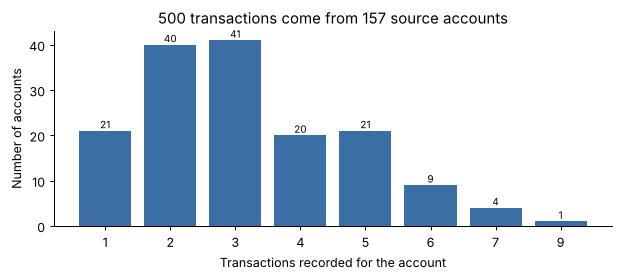

In [7]:
# 1(a)-4  Distinct privacy subjects: transactions per source account
txn_per_account = raw.groupby('ACCT1').size()
dist = txn_per_account.value_counts().sort_index()
print('Transactions:', n_rows, '| distinct REFNUM:', raw['REFNUM'].nunique(),
      '| distinct source accounts (ACCT1):', raw['ACCT1'].nunique())
print('Transactions per account: min', txn_per_account.min(), '| median', txn_per_account.median(),
      '| max', txn_per_account.max(), '| accounts with exactly one transaction:', int((txn_per_account == 1).sum()))
cities_per_acct = raw.groupby('ACCT1')['ADDRESS_CITY'].nunique()
channels_per_acct = raw.groupby('ACCT1')['TERMINAL_TYPE'].nunique()
print('Accounts seen in more than one city:', int((cities_per_acct > 1).sum()),
      '| in more than one channel:', int((channels_per_acct > 1).sum()))

fig, ax = plt.subplots(figsize=(7, 3.2))
ax.bar(dist.index.astype(str), dist.values, color='#3a6ea5')
ax.set_xlabel('Transactions recorded for the account')
ax.set_ylabel('Number of accounts')
ax.set_title('500 transactions come from 157 source accounts')
for x_pos, y_val in zip(range(len(dist)), dist.values):
    ax.text(x_pos, y_val + 0.6, str(y_val), ha='center', fontsize=8)
ax.spines[['top', 'right']].set_visible(False)
plt.tight_layout()
plt.savefig(EVID / 'Q1a_transactions_per_account.png', dpi=150)
plt.show()

In [8]:
# 1(a)-5  Response / status distributions (recorded outcomes, not fraud labels)
display(pd.crosstab(raw['RESPCODE'], raw['TRANS_STAT'], margins=True))
display(pd.crosstab(raw['ADDRESP'].replace('', '(blank)'), raw['RESPCODE']))
display(pd.crosstab(raw['REVERSAL'], raw['TRANS_STAT'], margins=True))
display(pd.crosstab(raw['TERMINAL_TYPE'], raw['TRANS_STAT'], margins=True))
display(pd.crosstab(raw['MSGTYPE'], raw['REVERSAL']))

TRANS_STAT,DECLINED,SUCCESS,All
RESPCODE,,,
00,0,369,369
05,45,0,45
51,48,0,48
55,14,0,14
96,24,0,24
All,131,369,500


RESPCODE,00,05,51,55,96
ADDRESP,,,,,
(blank),351,0,0,0,0
INSUFFICIENT,0,0,48,0,0
PIN,0,0,0,14,0
REJECTED,0,45,0,0,0
REVERSAL,18,0,0,0,0
TIMEOUT,0,0,0,0,24


TRANS_STAT,DECLINED,SUCCESS,All
REVERSAL,,,
0,131,351,482
1,0,18,18
All,131,369,500


TRANS_STAT,DECLINED,SUCCESS,All
TERMINAL_TYPE,,,
ATM,46,136,182
ECOM,46,114,160
POS,39,119,158
All,131,369,500


REVERSAL,0,1
MSGTYPE,,
1031,268,16
1041,210,2
1044,4,0


In [9]:
# 1(a)-6  Transaction counts versus unique-account counts
count_rows = []
for channel in sorted(raw['TERMINAL_TYPE'].unique()):
    part = raw[raw['TERMINAL_TYPE'] == channel]
    declined = part[part['TRANS_STAT'] == 'DECLINED']
    count_rows.append({'channel': channel, 'transactions': len(part), 'distinct_accounts': part['ACCT1'].nunique(),
                       'declined_transactions': len(declined),
                       'accounts_with_>=1_decline': declined['ACCT1'].nunique(),
                       'txn_decline_rate': round(len(declined) / len(part), 3),
                       'share_of_accounts_with_decline': round(declined['ACCT1'].nunique() / part['ACCT1'].nunique(), 3)})
all_declined = raw[raw['TRANS_STAT'] == 'DECLINED']
count_rows.append({'channel': 'ALL', 'transactions': n_rows, 'distinct_accounts': raw['ACCT1'].nunique(),
                   'declined_transactions': len(all_declined),
                   'accounts_with_>=1_decline': all_declined['ACCT1'].nunique(),
                   'txn_decline_rate': round(len(all_declined) / n_rows, 3),
                   'share_of_accounts_with_decline': round(all_declined['ACCT1'].nunique() / raw['ACCT1'].nunique(), 3)})
txn_vs_accounts = pd.DataFrame(count_rows)
txn_vs_accounts.to_csv(EVID / 'Q1a_transactions_vs_accounts.csv', index=False)
display(txn_vs_accounts)
channel_sum = int(txn_vs_accounts.loc[txn_vs_accounts['channel'] != 'ALL', 'distinct_accounts'].sum())
print('Sum of per-channel distinct accounts =', channel_sum, 'but the true total is', raw['ACCT1'].nunique(),
      '-> accounts are double-counted when per-channel account counts are added.')

Sum of per-channel distinct accounts = 318 but the true total is 157 -> accounts are double-counted when per-channel account counts are added.


,channel,transactions,distinct_accounts,declined_transactions,accounts_with_>=1_decline,txn_decline_rate,share_of_accounts_with_decline
0,ATM,182,105,46,40,0.253,0.381
1,ECOM,160,109,46,39,0.287,0.358
2,POS,158,104,39,37,0.247,0.356
3,ALL,500,157,131,91,0.262,0.580


In [10]:
# 1(a)-7  Data-quality and semantic hazards, each backed by computed evidence
parse_start = pd.to_datetime(raw['AUTH_START'].str.replace(r'(\.\d{6})\d{3}', r'\1', regex=True),
                             format='%d-%b-%y %I.%M.%S.%f %p')
parse_end = pd.to_datetime(raw['AUTH_END'].str.replace(r'(\.\d{6})\d{3}', r'\1', regex=True),
                           format='%d-%b-%y %I.%M.%S.%f %p')
merchant_word = raw['ADDRESS_NAME'].str.extract(r'^DEMO (\w+)')[0]
atm_named_not_atm = int(((merchant_word == 'ATM') & (raw['TERMINAL_TYPE'] != 'ATM')).sum())
cities_per_merchant = raw.groupby('MERCHANT')['ADDRESS_CITY'].nunique()
amount_group = ['REQAMT', 'ACTAMT', 'CONAMT', 'INSTITAMT', 'SYSAMT']
amount_identical = True
for col in amount_group[1:]:
    amount_identical = amount_identical and bool((raw[col] == raw['REQAMT']).all())
declined_with_actamt = int(((raw['TRANS_STAT'] == 'DECLINED') & (raw['ACTAMT'].astype(int) > 0)).sum())
reversal_rows = raw[raw['REVERSAL'] == '1']
negative_balances = int((raw['ACCTBAL'].astype(int) < 0).sum())
sad_columns = ['PINBLK', 'TRACK1', 'TRACK2', 'PASSWD', 'EXPRDATE', 'SECINFO']
sad_all_empty = bool(raw[sad_columns].eq('').all().all())
ecom_with_city = int((raw['TERMINAL_TYPE'] == 'ECOM').sum())
atmid_on_non_atm = int(((raw['TERMINAL_TYPE'] != 'ATM') & raw['ATMID'].ne('')).sum())
name_max_len = int(raw['ADDRESS_NAME'].str.len().max())

hazards = pd.DataFrame([
    {'id': 'H1', 'hazard': 'Byte-order mark on first header',
     'evidence': 'first bytes=' + str(first_header_bytes) + '; a plain utf-8 reader names the first column "\\ufeffHPAN" (pandas strips it, many tools do not)',
     'consequence': 'HPAN silently missed by column-name rules and DLP; read with utf-8-sig'},
    {'id': 'H2', 'hazard': 'Masked HPAN is still a linked identifier',
     'evidence': 'HPAN↔ACCT1 one-to-one; last-4 match share=' + str(round(float(last4_match_share), 3)),
     'consequence': 'masking ≠ anonymisation; HPAN must be classified with ACCT1'},
    {'id': 'H3', 'hazard': 'Redundant copies of identifiers and dates',
     'evidence': str(len(duplicate_groups)) + ' exact duplicate-column groups, e.g. ACCT1=ACCT_NO, 4 date copies, 3 time copies',
     'consequence': 'removing one copy leaves the value elsewhere; minimise every copy'},
    {'id': 'H4', 'hazard': 'Amount unit and meaning unknown',
     'evidence': 'REQAMT=ACTAMT=CONAMT=INSTITAMT=SYSAMT on all rows: ' + str(amount_identical)
                 + '; declined rows with ACTAMT>0: ' + str(declined_with_actamt),
     'consequence': 'cannot assert rand vs cents or "actual" spend; report raw units only, never sum as money'},
    {'id': 'H5', 'hazard': 'Reversals counted as successes',
     'evidence': str(len(reversal_rows)) + ' REVERSAL=1 rows are TRANS_STAT=SUCCESS, RESPCODE=00, STTLAMT=0',
     'consequence': 'naive success rate overstates completed payments; reversal ≠ decline ≠ fraud'},
    {'id': 'H6', 'hazard': 'Channel and merchant name contradict each other',
     'evidence': str(atm_named_not_atm) + ' "DEMO ATM ..." names on POS/ECOM rows; MERCHANT id spans up to '
                 + str(int(cities_per_merchant.max())) + ' cities; names truncated at ' + str(name_max_len) + ' chars',
     'consequence': 'ADDRESS_NAME is not a reliable merchant/location label; it also embeds city (QI)'},
    {'id': 'H7', 'hazard': 'City is not the cardholder location',
     'evidence': str(ecom_with_city) + ' ECOM rows carry a physical city; ' + str(int((cities_per_acct > 1).sum()))
                 + ' accounts appear in >1 city',
     'consequence': 'no "home city" exists; account-level city needs a stated tie-break (Q3)'},
    {'id': 'H8', 'hazard': 'ATMID unique per row and present on non-ATM rows',
     'evidence': 'distinct ATMID=' + str(raw['ATMID'].nunique()) + '; non-ATM rows with ATMID=' + str(atmid_on_non_atm),
     'consequence': 'not a terminal identifier; cannot count terminals; treat as row reference'},
    {'id': 'H9', 'hazard': 'Mixed timestamp formats',
     'evidence': 'AUTH_START uses DD-MON-YY 12-hour clock with 9-digit fractions; SWITCH_DATE uses YYYYMMDD; '
                 'date agreement=' + str(round(float((parse_start.dt.strftime('%Y%m%d') == raw['SWITCH_DATE']).mean()), 3)),
     'consequence': '2-digit year and AM/PM parsing errors; time zone not stated'},
    {'id': 'H10', 'hazard': 'Encoded codes with no dictionary',
     'evidence': 'MSGTYPE ' + str(sorted(raw['MSGTYPE'].unique())) + ', RESP ' + str(sorted(raw['RESP'].unique()))
                 + ', TRANS_TYPE ' + str(raw['TRANS_TYPE'].nunique()) + ' codes, PRCODE ' + str(raw['PRCODE'].nunique()) + ' codes',
     'consequence': 'report codes verbatim; do not invent meanings'},
    {'id': 'H11', 'hazard': 'Negative and per-row balances',
     'evidence': str(negative_balances) + ' negative ACCTBAL values; ACCTBAL distinct on every row',
     'consequence': 'confidential financial attribute of unknown definition; exclude from analytics'},
    {'id': 'H12', 'hazard': 'Sensitive-authentication fields exist in schema',
     'evidence': 'PINBLK/TRACK1/TRACK2/PASSWD/EXPRDATE/SECINFO all empty: ' + str(sad_all_empty),
     'consequence': 'contract must REJECT any future non-empty value (Q1c test M3)'},
])
hazards.to_csv(EVID / 'Q1a_hazards.csv', index=False)
display(hazards)

,id,hazard,evidence,consequence
0,H1,Byte-order mark on first header,"first bytes=b'\xef\xbb\xbf'; a plain utf-8 reader names the first column ""\ufeffHPAN"" (pandas strips it, many tools do not)",HPAN silently missed by column-name rules and DLP; read with utf-8-sig
1,H2,Masked HPAN is still a linked identifier,HPAN↔ACCT1 one-to-one; last-4 match share=1.0,masking ≠ anonymisation; HPAN must be classified with ACCT1
2,H3,Redundant copies of identifiers and dates,"5 exact duplicate-column groups, e.g. ACCT1=ACCT_NO, 4 date copies, 3 time copies",removing one copy leaves the value elsewhere; minimise every copy
3,H4,Amount unit and meaning unknown,REQAMT=ACTAMT=CONAMT=INSTITAMT=SYSAMT on all rows: True; declined rows with ACTAMT>0: 131,"cannot assert rand vs cents or ""actual"" spend; report raw units only, never sum as money"
4,H5,Reversals counted as successes,"18 REVERSAL=1 rows are TRANS_STAT=SUCCESS, RESPCODE=00, STTLAMT=0",naive success rate overstates completed payments; reversal ≠ decline ≠ fraud
5,H6,Channel and merchant name contradict each other,"12 ""DEMO ATM ..."" names on POS/ECOM rows; MERCHANT id spans up to 8 cities; names truncated at 25 chars",ADDRESS_NAME is not a reliable merchant/location label; it also embeds city (QI)
6,H7,City is not the cardholder location,160 ECOM rows carry a physical city; 134 accounts appear in >1 city,"no ""home city"" exists; account-level city needs a stated tie-break (Q3)"
7,H8,ATMID unique per row and present on non-ATM rows,distinct ATMID=500; non-ATM rows with ATMID=318,not a terminal identifier; cannot count terminals; treat as row reference
8,H9,Mixed timestamp formats,AUTH_START uses DD-MON-YY 12-hour clock with 9-digit fractions; SWITCH_DATE uses YYYYMMDD; date agreement=1.0,2-digit year and AM/PM parsing errors; time zone not stated
9,H10,Encoded codes with no dictionary,"MSGTYPE ['1031', '1041', '1044'], RESP ['-1', '901'], TRANS_TYPE 7 codes, PRCODE 5 codes",report codes verbatim; do not invent meanings


In [11]:
# 1(a)  TESTS
# Positive: the profile covers every column and every row; counts are internally consistent.
assert len(profile) == 149 and profile['n_null'].max() <= 500
assert int(txn_per_account.sum()) == 500 and raw['ACCT1'].nunique() == 157
assert bool(linkability['one_to_one'].all()) and last4_match_share == 1.0
assert len(hazards) >= 6
# Adversarial/negative: REFNUM uniqueness must NOT be mistaken for a count of privacy subjects.
assert raw['REFNUM'].nunique() == 500 and raw['ACCT1'].nunique() < raw['REFNUM'].nunique()
# Negative: the naive read (no utf-8-sig) does not expose a usable 'HPAN' column name.
naive_header = RAW_COPY.read_text(encoding='utf-8').split('\n')[0].split(',')[0]   # what csv/Spark-style readers see
assert naive_header != 'HPAN' and naive_header.startswith('\ufeff'), 'BOM hazard not reproduced'
# Negative: no raw account number leaked into the profile evidence file.
assert re.search(r'99\d{9}', (EVID / 'Q1a_data_profile.csv').read_text()) is None
print('Q1(a) tests passed: profile complete, linkage proven, REFNUM≠subject, BOM reproduced, no identifier leakage.')

Q1(a) tests passed: profile complete, linkage proven, REFNUM≠subject, BOM reproduced, no identifier leakage.


### 1(a) Interpretation

**What is in the file.** 500 transactions and 149 columns. Only **45 columns vary**; 32 are completely empty and 72 hold a single constant value, and several of the varying columns are exact copies of each other (amount × 5, date × 4, time × 3, `ACCT1 = ACCT_NO`, `STTLAMT = NETSTTLAMT`). The real information content is therefore far smaller than "149 fields" suggests. Bulk-loading every field into a lake, as management proposes, mostly copies redundant identifiers.

**Privacy subject.** No customer identifier exists. The most specific subject we can observe is the **source account** (`ACCT1`), so the privacy unit chosen here is *one source account*. This is a proxy, not a person. One person may hold several accounts, and a joint account may belong to several people. A privacy claim must therefore be stated per account, with that limitation written beside it.

**Transaction counts versus unique-account counts.** The 500 transactions come from **157 accounts** (1 to 9 transactions each; only 21 accounts appear once). The 131 declined transactions belong to only **91 accounts**. So 26.2% of *transactions* were declined, but 58% of *accounts* experienced at least one decline. The per-channel decline rate counts events, whereas "share of accounts with a decline" counts subjects. The two can diverge sharply. Adding per-channel distinct-account counts gives 318, more than double the true 157, because 116 accounts use several channels. Any disclosure threshold (for example "publish only cells with ≥10") must therefore count **distinct accounts**, never rows. Ten rows could come from one person.

**Identifier linkability.** `HPAN` is shown as `999999XXXXXX####`, but it is one-to-one with `ACCT1` and shares its last four digits on 100% of rows. `REFNUM`, `SEQNO`, `TRACE`, `SV_TRACE`, `UTRNNO`, `NTWKSEQNO`, `ATMID`, `ACCTBAL` and `AUTH_START` are unique per row. They identify **events**, not people. That is why REFNUM uniqueness says nothing about the number of distinct persons.

**Transaction-level uniqueness.** Date + city + channel singles out 63.4% of rows. Adding the amount singles out 99%. A recipient who saw one purchase (date, place, channel, value) could locate that row and, through repeated account tokens, the account's other transactions.

## 1(b) End-to-end architecture [6]

### Why the management proposal is rejected
| Proposal element | Failure |
|---|---|
| Upload all 149 fields to a common lake | Violates purpose limitation and minimisation. Copies `ACCT1`, `ACCT_NO`, `HPAN`, `ACCTBAL` and empty sensitive-authentication slots to every lake reader. One broad read role exposes everything. |
| Email a filtered CSV to every partner | No authenticated channel, no recipient authorisation, no revocation, no audit trail, no disclosure check. A "filtered" transaction-level file is still linkable (1(a)). |
| One copy for internal and external use | Internal fraud traceability and external statistics have different purposes, so they need different views and different keys. |

### Replacement design (diagram below; full version in the PDF deliverable)
- **Record unit:** one host transaction (`REFNUM`). **Privacy unit:** one source account (`ACCT1`). Account-level aggregation happens **only** inside the internal analytics zone (Silver → account-level table), before any release.
- **Trust boundaries:** TB0 partner source → TB1 ingestion/restricted zone → TB2 key and token boundary (separate security account) → TB3 internal analytics → TB4 release zone → TB5 external recipients. TB6 security/audit sits across all of them.
- **Encryption points:** E1 TLS 1.3 + mTLS on ingest; E2 envelope encryption (AES-256-GCM, DEK wrapped by KMS KEK) on raw and quarantine objects; E3 HMAC-SHA256 tokenisation at Bronze (key held in TB2); E4 storage-service encryption on every zone; E5 signed, TLS-only release export.
- **Logging:** payload-free audit events for every read, deny, token access and key operation are shipped to an append-only store in a separate security account (TB6).
- **Exact public outputs:** only `external_release_v1.csv`. It holds two tables: month × channel and city × channel, with transactions, distinct accounts and decline rate, for cells with ≥10 distinct accounts. No tokens, no row-level data and no amounts are released.
- **Assumptions that would invalidate a privacy claim:** (1) one account = one person; joint or multiple accounts break per-account reasoning. (2) HMAC and KMS keys stay inside TB2; any copy outside defeats tokenisation. (3) No other release overlaps this one; differencing across releases can reveal small cells. (4) Recipients hold only the auxiliary data assumed in the threat model. (5) The 99-prefix DLP rule generalises beyond this synthetic file. (6) Logs and backups are inventoried; an untracked copy defeats crypto-shredding. (7) The ≥10 threshold is a disclosure-control heuristic, not a formal guarantee.
- **Deletion:** TTL per retention class, crypto-shredding of DEKs for the raw and quarantine batches, and a copy inventory (exports, caches, backups). Destroying a key does not by itself prove deletion if plaintext copies exist.

In [12]:
# 1(b)-1  Machine-checkable architecture model: flows, controls and trust-boundary rules
APPROVED_TRANSIT = ['TLS1.3+mTLS', 'TLS1.3 private endpoint', 'in-zone (same boundary)']
architecture_flows = [
    {'flow': 'F1', 'from': 'Partner host export', 'from_zone': 'TB0', 'to': 'Ingestion gateway', 'to_zone': 'TB1',
     'data_class': 'RESTRICTED', 'transit': 'TLS1.3+mTLS', 'at_rest': 'n/a', 'authz': 'workload identity ingest-svc', 'logged': True},
    {'flow': 'F2', 'from': 'Ingestion gateway', 'from_zone': 'TB1', 'to': 'Quarantine', 'to_zone': 'TB1',
     'data_class': 'RESTRICTED', 'transit': 'in-zone (same boundary)', 'at_rest': 'AES-256-GCM envelope (KMS KEK)', 'authz': 'ingest-svc write-only', 'logged': True},
    {'flow': 'F3', 'from': 'Ingestion gateway', 'from_zone': 'TB1', 'to': 'Raw landing (read-only)', 'to_zone': 'TB1',
     'data_class': 'RESTRICTED', 'transit': 'in-zone (same boundary)', 'at_rest': 'AES-256-GCM envelope (KMS KEK)', 'authz': 'ingest-svc write-once', 'logged': True},
    {'flow': 'F4', 'from': 'Token vault / HMAC key', 'from_zone': 'TB2', 'to': 'Bronze tokeniser', 'to_zone': 'TB1',
     'data_class': 'SECRET', 'transit': 'TLS1.3 private endpoint', 'at_rest': 'HSM-backed', 'authz': 'tokeniser-svc sign-only (no export)', 'logged': True},
    {'flow': 'F5', 'from': 'Bronze (tokenised)', 'from_zone': 'TB1', 'to': 'Silver (minimised)', 'to_zone': 'TB3',
     'data_class': 'CONFIDENTIAL', 'transit': 'TLS1.3 private endpoint', 'at_rest': 'SSE-KMS', 'authz': 'data-engineer pipeline role', 'logged': True},
    {'flow': 'F6', 'from': 'Silver', 'from_zone': 'TB3', 'to': 'Account-level aggregation', 'to_zone': 'TB3',
     'data_class': 'CONFIDENTIAL', 'transit': 'in-zone (same boundary)', 'at_rest': 'SSE-KMS', 'authz': 'aggregation job', 'logged': True},
    {'flow': 'F7', 'from': 'Silver', 'from_zone': 'TB3', 'to': 'Fraud-ops case view', 'to_zone': 'TB3',
     'data_class': 'CONFIDENTIAL', 'transit': 'in-zone (same boundary)', 'at_rest': 'SSE-KMS', 'authz': 'RBAC fraud_investigator + ABAC purpose/MFA/expiry', 'logged': True},
    {'flow': 'F8', 'from': 'Account-level aggregation', 'from_zone': 'TB3', 'to': 'Gold aggregates', 'to_zone': 'TB4',
     'data_class': 'INTERNAL', 'transit': 'TLS1.3 private endpoint', 'at_rest': 'SSE-KMS', 'authz': 'release-builder job', 'logged': True},
    {'flow': 'F9', 'from': 'Release gate (DLP + threshold + DPO approval)', 'from_zone': 'TB4', 'to': 'Industry association', 'to_zone': 'TB5',
     'data_class': 'PUBLIC_AGGREGATE', 'transit': 'TLS1.3+mTLS', 'at_rest': 'n/a', 'authz': 'approved export id + recipient identity', 'logged': True, 'release_gate': True},
    {'flow': 'F10', 'from': 'All zones (metadata only)', 'from_zone': 'TB3', 'to': 'Append-only audit store', 'to_zone': 'TB6',
     'data_class': 'INTERNAL', 'transit': 'TLS1.3 private endpoint', 'at_rest': 'immutable (WORM)', 'authz': 'log-writer role, no read-back', 'logged': True},
]
management_flows = [
    {'flow': 'M1', 'from': 'Partner host export', 'from_zone': 'TB0', 'to': 'Common lake (149 fields)', 'to_zone': 'TB3',
     'data_class': 'RESTRICTED', 'transit': 'unspecified', 'at_rest': 'unspecified', 'authz': 'broad lake read', 'logged': False},
    {'flow': 'M2', 'from': 'Common lake (149 fields)', 'from_zone': 'TB3', 'to': 'Every partner (email)', 'to_zone': 'TB5',
     'data_class': 'RESTRICTED', 'transit': 'email attachment', 'at_rest': 'mailbox', 'authz': 'none', 'logged': False},
]
flow_check_rows = []
for design_name, flows in [('proposed', architecture_flows), ('management', management_flows)]:
    for flow in flows:
        problems = []
        if flow['transit'] not in APPROVED_TRANSIT and flow['transit'] != 'n/a':
            problems.append('unapproved transit')
        if flow['from_zone'] != flow['to_zone'] and flow['transit'] == 'in-zone (same boundary)':
            problems.append('boundary crossing labelled in-zone')
        if flow['authz'] in ['none', 'broad lake read']:
            problems.append('no least-privilege authorisation')
        if not flow['logged']:
            problems.append('not audited')
        if flow['data_class'] in ['RESTRICTED', 'SECRET'] and flow['at_rest'] in ['unspecified', 'mailbox']:
            problems.append('restricted data not encrypted at rest')
        if flow['to_zone'] == 'TB5' and (flow['data_class'] != 'PUBLIC_AGGREGATE' or not flow.get('release_gate', False)):
            problems.append('external release without aggregate-only gate')
        flow_check_rows.append({'design': design_name, 'flow': flow['flow'], 'from': flow['from'], 'to': flow['to'],
                                'crosses_boundary': flow['from_zone'] != flow['to_zone'],
                                'violations': '; '.join(problems) if problems else 'none'})
flow_check = pd.DataFrame(flow_check_rows)
flow_check.to_csv(EVID / 'Q1b_flow_control_check.csv', index=False)
display(flow_check)
assert (flow_check.loc[flow_check['design'] == 'proposed', 'violations'] == 'none').all()          # positive
assert (flow_check.loc[flow_check['design'] == 'management', 'violations'] != 'none').all()        # negative
print('Every proposed boundary-crossing flow carries approved transit, least-privilege authz and audit; '
      'both management flows fail.')

Every proposed boundary-crossing flow carries approved transit, least-privilege authz and audit; both management flows fail.


,design,flow,from,to,crosses_boundary,violations
0,proposed,F1,Partner host export,Ingestion gateway,True,none
1,proposed,F2,Ingestion gateway,Quarantine,False,none
2,proposed,F3,Ingestion gateway,Raw landing (read-only),False,none
3,proposed,F4,Token vault / HMAC key,Bronze tokeniser,True,none
4,proposed,F5,Bronze (tokenised),Silver (minimised),True,none
5,proposed,F6,Silver,Account-level aggregation,False,none
6,proposed,F7,Silver,Fraud-ops case view,False,none
7,proposed,F8,Account-level aggregation,Gold aggregates,True,none
8,proposed,F9,Release gate (DLP + threshold + DPO approval),Industry association,True,none
9,proposed,F10,All zones (metadata only),Append-only audit store,True,none


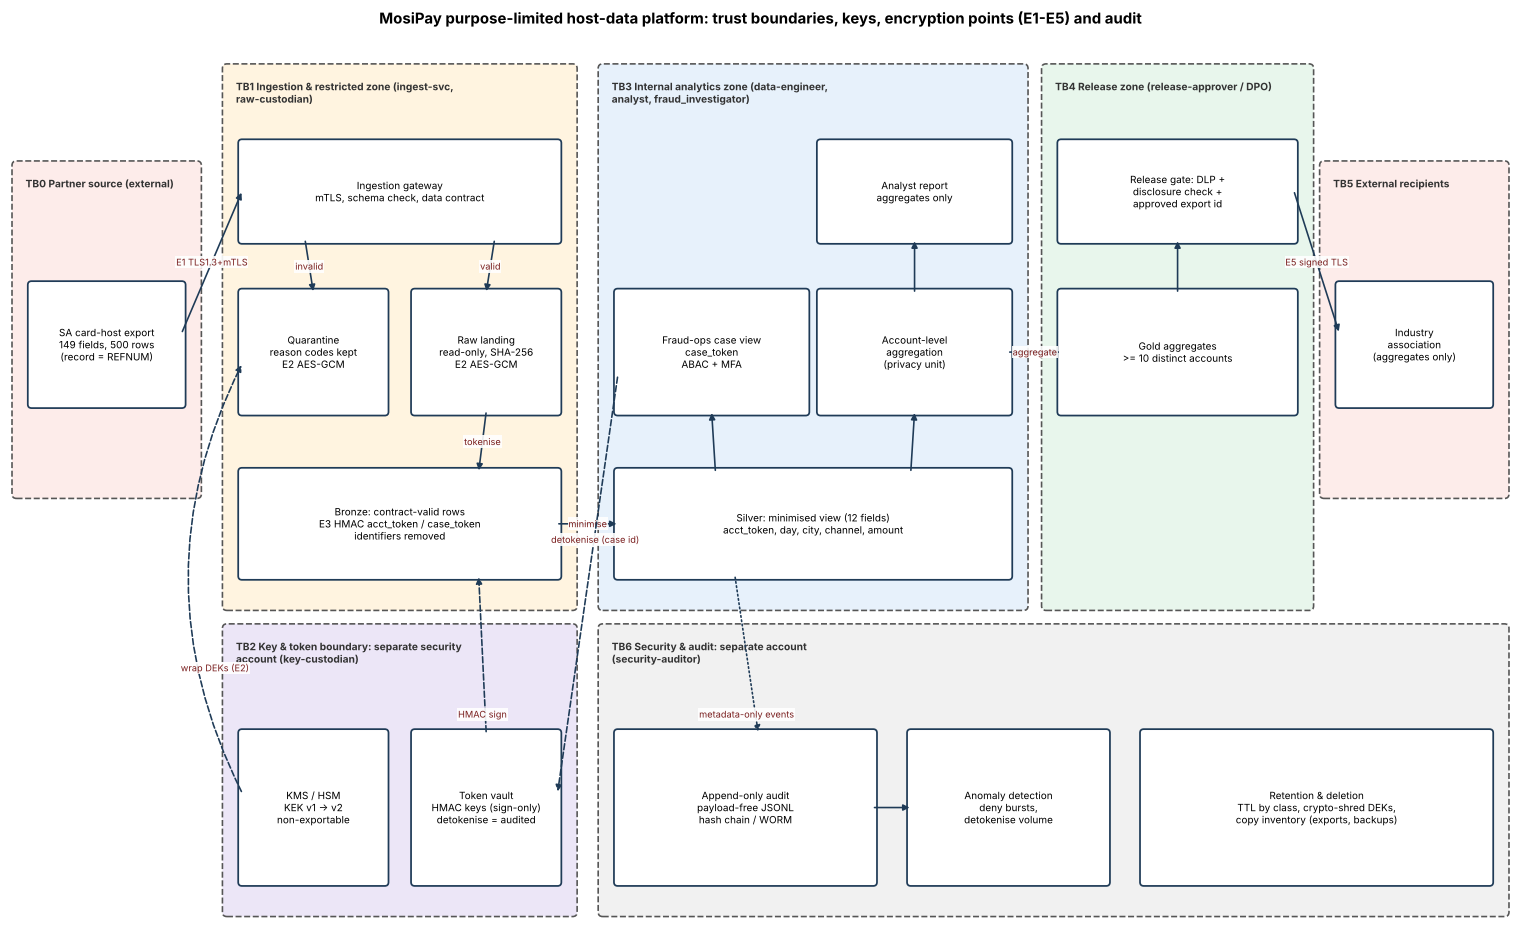

In [13]:
# 1(b)-2  Architecture diagram (trust boundaries, principals, keys, encryption points, logging)
fig, ax = plt.subplots(figsize=(17, 10.5))
ax.set_xlim(0, 100)
ax.set_ylim(0, 60)
ax.axis('off')
zones = [
    ('TB0 Partner source (external)', 0.5, 29, 12, 22, '#fdecea'),
    ('TB1 Ingestion & restricted zone (ingest-svc, raw-custodian)', 14.5, 21.5, 23, 36, '#fff4e0'),
    ('TB2 Key & token boundary: separate security account (key-custodian)', 14.5, 1, 23, 19, '#ece6f7'),
    ('TB3 Internal analytics zone (data-engineer, analyst, fraud_investigator)', 39.5, 21.5, 28, 36, '#e7f1fb'),
    ('TB4 Release zone (release-approver / DPO)', 69, 21.5, 17.5, 36, '#e8f6ec'),
    ('TB5 External recipients', 87.5, 29, 12, 22, '#fdecea'),
    ('TB6 Security & audit: separate account (security-auditor)', 39.5, 1, 60, 19, '#f1f1f1'),
]
for label, x0, y0, w, h, colour in zones:
    ax.add_patch(FancyBboxPatch((x0, y0), w, h, boxstyle='round,pad=0.3', fc=colour, ec='#555555', ls='--', lw=1.3))
    ax.text(x0 + 0.6, y0 + h - 0.8, textwrap.fill(label, 46), fontsize=8.2, weight='bold', va='top', color='#333333')
boxes = {
    'src': (1.5, 35, 10, 8, 'SA card-host export\n149 fields, 500 rows\n(record = REFNUM)'),
    'gw': (15.5, 46, 21, 6.5, 'Ingestion gateway\nmTLS, schema check, data contract'),
    'quar': (15.5, 34.5, 9.5, 8, 'Quarantine\nreason codes kept\nE2 AES-GCM'),
    'rawz': (27, 34.5, 9.5, 8, 'Raw landing\nread-only, SHA-256\nE2 AES-GCM'),
    'bronze': (15.5, 23.5, 21, 7, 'Bronze: contract-valid rows\nE3 HMAC acct_token / case_token\nidentifiers removed'),
    'kms': (15.5, 3, 9.5, 10, 'KMS / HSM\nKEK v1 -> v2\nnon-exportable'),
    'vault': (27, 3, 9.5, 10, 'Token vault\nHMAC keys (sign-only)\ndetokenise = audited'),
    'silver': (40.5, 23.5, 26, 7, 'Silver: minimised view (12 fields)\nacct_token, day, city, channel, amount'),
    'fraud': (40.5, 34.5, 12.5, 8, 'Fraud-ops case view\ncase_token\nABAC + MFA'),
    'acctagg': (54, 34.5, 12.5, 8, 'Account-level\naggregation\n(privacy unit)'),
    'analyst': (54, 46, 12.5, 6.5, 'Analyst report\naggregates only'),
    'gold': (70, 34.5, 15.5, 8, 'Gold aggregates\n>= 10 distinct accounts'),
    'gate': (70, 46, 15.5, 6.5, 'Release gate: DLP +\ndisclosure check +\napproved export id'),
    'ext': (88.5, 35, 10, 8, 'Industry\nassociation\n(aggregates only)'),
    'audit': (40.5, 3, 17, 10, 'Append-only audit\npayload-free JSONL\nhash chain / WORM'),
    'anom': (60, 3, 13, 10, 'Anomaly detection\ndeny bursts,\ndetokenise volume'),
    'del': (75.5, 3, 23, 10, 'Retention & deletion\nTTL by class, crypto-shred DEKs,\ncopy inventory (exports, backups)'),
}
for key in boxes:
    bx, by, bw, bh, text = boxes[key]
    ax.add_patch(FancyBboxPatch((bx, by), bw, bh, boxstyle='round,pad=0.25', fc='white', ec='#1f3b57', lw=1.4))
    ax.text(bx + bw / 2, by + bh / 2, text, ha='center', va='center', fontsize=8)
# (start box, x-fraction, y-fraction, end box, x-fraction, y-fraction, label, line style, curvature)
arrows = [('src', 1, 0.6, 'gw', 0, 0.5, 'E1 TLS1.3+mTLS', '-', 0),
          ('gw', 0.2, 0, 'quar', 0.5, 1, 'invalid', '-', 0), ('gw', 0.8, 0, 'rawz', 0.5, 1, 'valid', '-', 0),
          ('rawz', 0.5, 0, 'bronze', 0.75, 1, 'tokenise', '-', 0),
          ('vault', 0.5, 1, 'bronze', 0.75, 0, 'HMAC sign', '--', 0),
          ('kms', 0, 0.6, 'quar', 0, 0.4, 'wrap DEKs (E2)', '--', -0.25),
          ('bronze', 1, 0.5, 'silver', 0, 0.5, 'minimise', '-', 0),
          ('silver', 0.25, 1, 'fraud', 0.5, 0, '', '-', 0), ('silver', 0.75, 1, 'acctagg', 0.5, 0, '', '-', 0),
          ('acctagg', 0.5, 1, 'analyst', 0.5, 0, '', '-', 0), ('acctagg', 1, 0.5, 'gold', 0, 0.5, 'aggregate', '-', 0),
          ('gold', 0.5, 1, 'gate', 0.5, 0, '', '-', 0), ('gate', 1, 0.5, 'ext', 0, 0.6, 'E5 signed TLS', '-', 0),
          ('fraud', 0, 0.3, 'vault', 1, 0.6, 'detokenise (case id)', '--', 0),
          ('silver', 0.3, 0, 'audit', 0.55, 1, 'metadata-only events', ':', 0),
          ('audit', 1, 0.5, 'anom', 0, 0.5, '', '-', 0)]
LABEL_SHIFT = {'HMAC sign': (0, -4), 'metadata-only events': (0, -4), 'detokenise (case id)': (0.5, 3),
               'wrap DEKs (E2)': (-1.8, -6)}
for start, sfx, sfy, end, efx, efy, label, style, rad in arrows:
    sx, sy, sw, sh, _ = boxes[start]
    ex, ey, ew, eh, _ = boxes[end]
    p1 = (sx + sfx * sw, sy + sfy * sh)
    p2 = (ex + efx * ew, ey + efy * eh)
    ax.annotate('', xy=p2, xytext=p1, arrowprops=dict(arrowstyle='-|>', lw=1.3, ls=style, color='#1f3b57',
                                                      shrinkA=1, shrinkB=1, connectionstyle='arc3,rad=' + str(rad)))
    if label:
        shift = LABEL_SHIFT.get(label, (0, 0))
        ax.text((p1[0] + p2[0]) / 2 + shift[0], (p1[1] + p2[1]) / 2 + shift[1], label, fontsize=7.4, ha='center',
                va='center', color='#7a1f1f', bbox=dict(fc='white', ec='none', alpha=0.9, pad=0.6))
ax.set_title('MosiPay purpose-limited host-data platform: trust boundaries, keys, encryption points (E1-E5) and audit',
             fontsize=12, weight='bold')
plt.tight_layout()
plt.savefig(EVID / 'Q1b_architecture.png', dpi=160)
plt.savefig(EVID / 'Q1b_architecture.pdf')
plt.show()

In [14]:
# 1(b)-3  Principals, rejected alternatives and PROPOSED (not deployed) cloud mapping
principals = pd.DataFrame([
    {'principal': 'ingest-svc', 'type': 'workload identity', 'may': 'write raw/quarantine; call tokeniser', 'may_not': 'read Silver/Gold; decrypt archived raw'},
    {'principal': 'raw-custodian', 'type': 'human, break-glass', 'may': 'read raw for incident forensics with ticket', 'may_not': 'export; routine access'},
    {'principal': 'key-custodian', 'type': 'human, security account', 'may': 'create/rotate/disable KEKs', 'may_not': 'read any data zone'},
    {'principal': 'data-engineer', 'type': 'human + pipeline role', 'may': 'write curated Silver; run jobs', 'may_not': 'detokenise; release externally'},
    {'principal': 'analyst (contracted)', 'type': 'human', 'may': 'read approved aggregate reports', 'may_not': 'raw refs, tokens, HMAC key, transaction-level export'},
    {'principal': 'fraud_investigator', 'type': 'human, MFA', 'may': 'case view; detokenise one account per case id', 'may_not': 'bulk export; external release'},
    {'principal': 'release-approver (DPO)', 'type': 'human', 'may': 'approve export id after disclosure check', 'may_not': 'edit data'},
    {'principal': 'external_partner', 'type': 'external identity', 'may': 'read approved Gold release', 'may_not': 'anything below Gold'},
    {'principal': 'security-auditor', 'type': 'human, security account', 'may': 'read audit logs', 'may_not': 'modify/delete logs; read data'},
])
rejected = pd.DataFrame([
    {'alternative': 'A1 Common lake with all 149 fields + emailed CSV (management proposal)',
     'why_rejected': 'no minimisation, broad read, unaudited unauthenticated email channel, transaction-level linkable file leaves control'},
    {'alternative': 'A2 Unkeyed SHA-256 of ACCT1 as "anonymous ID"',
     'why_rejected': 'account space is small and structured; dictionary attack reverses every hash (proved in Q2a)'},
    {'alternative': 'A3 Tokenise late (at Gold) after landing raw IDs in shared Bronze/Silver',
     'why_rejected': 'every upstream reader, backup and log already holds identifiers; minimisation must be at ingestion'},
    {'alternative': 'A4 Encryption key stored with the data / in notebook or repo',
     'why_rejected': 'an attacker who reads the files also gets the key; no separation of duties or rotation'},
    {'alternative': 'A5 Ship raw records to partners and trust their contract to delete',
     'why_rejected': 'violates "records stay local" requirement; no technical enforcement or audit'},
])
cloud_map = pd.DataFrame([
    {'capability': 'Object storage (zones)', 'AWS (PROPOSED, not deployed)': 'Amazon S3 buckets per zone, Block Public Access, S3 Object Lock for raw/audit',
     'Azure (PROPOSED, not deployed)': 'ADLS Gen2 containers per zone, immutable blob storage for raw/audit'},
    {'capability': 'Identity & access', 'AWS (PROPOSED, not deployed)': 'IAM roles + bucket policies (explicit deny), Lake Formation column/row filters, ABAC via principal/resource tags',
     'Azure (PROPOSED, not deployed)': 'Microsoft Entra ID + Azure RBAC with ABAC role-assignment conditions, Purview/Synapse row & column security'},
    {'capability': 'Key management', 'AWS (PROPOSED, not deployed)': 'AWS KMS customer-managed KEKs (rotation, key policies), CloudHSM optional; Secrets Manager for HMAC key ref',
     'Azure (PROPOSED, not deployed)': 'Azure Key Vault / Managed HSM keys (rotation policy, RBAC), customer-managed keys for storage'},
    {'capability': 'Audit logging', 'AWS (PROPOSED, not deployed)': 'CloudTrail management + S3/KMS data events to a separate log-archive account, log-file integrity validation',
     'Azure (PROPOSED, not deployed)': 'Azure Monitor activity + storage/Key Vault diagnostic logs to a separate Log Analytics workspace / immutable storage'},
])
principals.to_csv(EVID / 'Q1b_principals.csv', index=False)
rejected.to_csv(EVID / 'Q1b_rejected_alternatives.csv', index=False)
cloud_map.to_csv(EVID / 'Q1b_cloud_mapping_PROPOSED.csv', index=False)
display(principals)
display(rejected)
display(cloud_map)
assert len(rejected) >= 3 and cloud_map.shape[0] == 4
assert cloud_map.drop(columns='capability').columns.str.contains('PROPOSED').all()
print('Cloud mapping is labelled PROPOSED; no cloud resource was created by this notebook.')

Cloud mapping is labelled PROPOSED; no cloud resource was created by this notebook.


,principal,type,may,may_not
0,ingest-svc,workload identity,write raw/quarantine; call tokeniser,read Silver/Gold; decrypt archived raw
1,raw-custodian,"human, break-glass",read raw for incident forensics with ticket,export; routine access
2,key-custodian,"human, security account",create/rotate/disable KEKs,read any data zone
3,data-engineer,human + pipeline role,write curated Silver; run jobs,detokenise; release externally
4,analyst (contracted),human,read approved aggregate reports,"raw refs, tokens, HMAC key, transaction-level export"
5,fraud_investigator,"human, MFA",case view; detokenise one account per case id,bulk export; external release
6,release-approver (DPO),human,approve export id after disclosure check,edit data
7,external_partner,external identity,read approved Gold release,anything below Gold
8,security-auditor,"human, security account",read audit logs,modify/delete logs; read data


,alternative,why_rejected
0,A1 Common lake with all 149 fields + emailed CSV (management proposal),"no minimisation, broad read, unaudited unauthenticated email channel, transaction-level linkable file leaves control"
1,"A2 Unkeyed SHA-256 of ACCT1 as ""anonymous ID""",account space is small and structured; dictionary attack reverses every hash (proved in Q2a)
2,A3 Tokenise late (at Gold) after landing raw IDs in shared Bronze/Silver,"every upstream reader, backup and log already holds identifiers; minimisation must be at ingestion"
3,A4 Encryption key stored with the data / in notebook or repo,an attacker who reads the files also gets the key; no separation of duties or rotation
4,A5 Ship raw records to partners and trust their contract to delete,"violates ""records stay local"" requirement; no technical enforcement or audit"


,capability,"AWS (PROPOSED, not deployed)","Azure (PROPOSED, not deployed)"
0,Object storage (zones),"Amazon S3 buckets per zone, Block Public Access, S3 Object Lock for raw/audit","ADLS Gen2 containers per zone, immutable blob storage for raw/audit"
1,Identity & access,"IAM roles + bucket policies (explicit deny), Lake Formation column/row filters, ABAC via principal/resource tags","Microsoft Entra ID + Azure RBAC with ABAC role-assignment conditions, Purview/Synapse row & column security"
2,Key management,"AWS KMS customer-managed KEKs (rotation, key policies), CloudHSM optional; Secrets Manager for HMAC key ref","Azure Key Vault / Managed HSM keys (rotation policy, RBAC), customer-managed keys for storage"
3,Audit logging,"CloudTrail management + S3/KMS data events to a separate log-archive account, log-file integrity validation",Azure Monitor activity + storage/Key Vault diagnostic logs to a separate Log Analytics workspace / immutable storage


## 1(c) Executable data contract (21 real source fields) [4]

The contract is machine-readable (`data_contract.json`) and drives validation directly. **Patterns are observed formats, not business definitions.** Each field records its semantic uncertainty. Cross-field rules are labelled *observed invariants*: a violation is quarantined for human review, not silently "corrected" or deleted. Rejected rows are kept, with reason codes and a row hash, in restricted quarantine. The evidence ZIP carries only the payload-free quarantine log.

In [15]:
# 1(c)-1  Build the contract
contract_fields = [
    {'field': 'REFNUM', 'pattern': r'SYN\d{12}', 'nullable': False, 'classification': 'CONFIDENTIAL', 'privacy_role': 'transaction reference',
     'semantic_uncertainty': 'appears to embed YYMMDD + sequence; uniqueness is per event, not per person', 'purpose': 'traceability (fraud case)',
     'access_role': 'fraud_investigator via case_token', 'retention_class': 'R2-operational-13m', 'minimisation': 'HMAC case_token; raw dropped'},
    {'field': 'HPAN', 'pattern': r'\d{6}X{6}\d{4}', 'nullable': False, 'classification': 'RESTRICTED', 'privacy_role': 'linked account identifier',
     'semantic_uncertainty': 'masked card number; one-to-one with ACCT1 (last-4 identical)', 'purpose': 'none in analytics',
     'access_role': 'raw-custodian only', 'retention_class': 'R1-raw-90d', 'minimisation': 'drop after ingestion'},
    {'field': 'ACCT1', 'pattern': r'\d{11}', 'nullable': False, 'classification': 'RESTRICTED', 'privacy_role': 'direct account identifier (privacy unit)',
     'semantic_uncertainty': 'account ≠ person; ownership model unknown', 'purpose': 'account-level aggregation via token',
     'access_role': 'tokeniser-svc; detokenise=fraud_investigator', 'retention_class': 'R1-raw-90d', 'minimisation': 'HMAC acct_token'},
    {'field': 'ACCT_NO', 'pattern': r'\d{11}', 'nullable': False, 'classification': 'RESTRICTED', 'privacy_role': 'duplicate of ACCT1',
     'semantic_uncertainty': 'identical to ACCT1 on every row; meaning of duplication unknown', 'purpose': 'consistency check only',
     'access_role': 'ingest-svc', 'retention_class': 'R1-raw-90d', 'minimisation': 'drop'},
    {'field': 'ACCTBAL', 'pattern': r'-?\d+', 'nullable': False, 'classification': 'RESTRICTED', 'privacy_role': 'confidential financial attribute',
     'semantic_uncertainty': 'available vs ledger balance and unit unknown; negatives present', 'purpose': 'none approved',
     'access_role': 'raw-custodian only', 'retention_class': 'R1-raw-90d', 'minimisation': 'drop'},
    {'field': 'ADDRESS_CITY', 'allowed': sorted(raw['ADDRESS_CITY'].unique().tolist()), 'nullable': False, 'classification': 'INTERNAL', 'privacy_role': 'quasi-identifier',
     'semantic_uncertainty': 'acceptor city, not cardholder residence; ECOM rows also carry a city', 'purpose': 'merchant-channel service reporting',
     'access_role': 'data-engineer, analyst (aggregated)', 'retention_class': 'R3-analytics-24m', 'minimisation': 'keep (Silver); coarsen for release'},
    {'field': 'ADDRESS_NAME', 'pattern': r'DEMO [A-Z ]{1,20}', 'nullable': False, 'classification': 'CONFIDENTIAL', 'privacy_role': 'quasi-identifier (merchant + city)',
     'semantic_uncertainty': 'truncated at 25 chars; type word contradicts channel on some rows', 'purpose': 'none (MERCHANT id suffices)',
     'access_role': 'raw-custodian only', 'retention_class': 'R1-raw-90d', 'minimisation': 'drop'},
    {'field': 'MERCHANT', 'pattern': r'DEMO_MERCHANT_\d{3}', 'nullable': False, 'classification': 'INTERNAL', 'privacy_role': 'quasi-identifier',
     'semantic_uncertainty': 'same id appears in several cities; may be a chain or a test artefact', 'purpose': 'merchant service metrics',
     'access_role': 'data-engineer, analyst (aggregated)', 'retention_class': 'R3-analytics-24m', 'minimisation': 'keep internally; not released'},
    {'field': 'TERMINAL_TYPE', 'allowed': ['ATM', 'ECOM', 'POS'], 'nullable': False, 'classification': 'INTERNAL', 'privacy_role': 'quasi-identifier (channel)',
     'semantic_uncertainty': 'channel label; conflicts with ADDRESS_NAME on some rows', 'purpose': 'merchant-channel reporting',
     'access_role': 'analyst, external (aggregated)', 'retention_class': 'R3-analytics-24m', 'minimisation': 'keep'},
    {'field': 'AUTH_START', 'pattern': r'\d{2}-[A-Z]{3}-\d{2} \d{2}\.\d{2}\.\d{2}\.\d{9} (AM|PM)', 'nullable': False, 'classification': 'CONFIDENTIAL', 'privacy_role': 'quasi-identifier (exact time)',
     'semantic_uncertainty': 'time zone unstated; 2-digit year; 12-hour clock', 'purpose': 'auth latency metric (derived seconds)',
     'access_role': 'fraud_investigator (exact); others derived only', 'retention_class': 'R2-operational-13m', 'minimisation': 'derive auth_seconds + day; drop exact'},
    {'field': 'SWITCH_DATE', 'pattern': r'20\d{6}', 'date_format': '%Y%m%d', 'nullable': False, 'classification': 'INTERNAL', 'privacy_role': 'quasi-identifier (date)',
     'semantic_uncertainty': 'identical to CAPTDATE/UDATE/BANK_STTL_DATE; settlement vs switch semantics unknown', 'purpose': 'daily/monthly reporting',
     'access_role': 'analyst (aggregated), external (month)', 'retention_class': 'R3-analytics-24m', 'minimisation': 'keep day internally; month externally'},
    {'field': 'REQAMT', 'pattern': r'\d+', 'nullable': False, 'classification': 'CONFIDENTIAL', 'privacy_role': 'quasi-identifier (value)',
     'semantic_uncertainty': 'unit unknown (major vs minor units); currency code 710 is constant', 'purpose': 'transaction-quality metrics',
     'access_role': 'data-engineer; analyst sees bands/aggregates', 'retention_class': 'R3-analytics-24m', 'minimisation': 'keep raw units internally; bands externally'},
    {'field': 'ACTAMT', 'pattern': r'\d+', 'nullable': False, 'classification': 'CONFIDENTIAL', 'privacy_role': 'duplicate amount',
     'semantic_uncertainty': 'equals REQAMT even on declined rows; "actual" meaning unverified', 'purpose': 'consistency check only',
     'access_role': 'ingest-svc', 'retention_class': 'R1-raw-90d', 'minimisation': 'drop'},
    {'field': 'STTLAMT', 'pattern': r'\d+', 'nullable': False, 'classification': 'CONFIDENTIAL', 'privacy_role': 'outcome-correlated value',
     'semantic_uncertainty': 'zero for declines and reversals; settlement semantics unverified', 'purpose': 'quality metric (settled vs requested)',
     'access_role': 'data-engineer', 'retention_class': 'R3-analytics-24m', 'minimisation': 'derive settled_flag'},
    {'field': 'TRANS_STAT', 'allowed': ['DECLINED', 'SUCCESS'], 'nullable': False, 'classification': 'CONFIDENTIAL', 'privacy_role': 'sensitive outcome',
     'semantic_uncertainty': 'DECLINED is a response outcome, NOT fraud', 'purpose': 'service-quality reporting',
     'access_role': 'analyst (aggregated), external (rates)', 'retention_class': 'R3-analytics-24m', 'minimisation': 'keep'},
    {'field': 'RESPCODE', 'allowed': ['00', '05', '51', '55', '96'], 'nullable': False, 'classification': 'CONFIDENTIAL', 'privacy_role': 'sensitive outcome detail',
     'semantic_uncertainty': 'resembles ISO 8583 codes but no dictionary supplied; unseen codes possible', 'purpose': 'decline-reason distribution',
     'access_role': 'analyst (aggregated)', 'retention_class': 'R3-analytics-24m', 'minimisation': 'keep internally; grouped externally'},
    {'field': 'REVERSAL', 'allowed': ['0', '1'], 'nullable': False, 'classification': 'INTERNAL', 'privacy_role': 'outcome modifier',
     'semantic_uncertainty': 'reversal rows are SUCCESS/00 with zero settlement', 'purpose': 'correct success-rate denominator',
     'access_role': 'analyst (aggregated)', 'retention_class': 'R3-analytics-24m', 'minimisation': 'keep'},
    {'field': 'MSGTYPE', 'pattern': r'\d{4}', 'nullable': False, 'classification': 'INTERNAL', 'privacy_role': 'encoded operational',
     'semantic_uncertainty': '1031/1041/1044 not explained; do not map to ISO MTI without dictionary', 'purpose': 'none approved',
     'access_role': 'data-engineer', 'retention_class': 'R2-operational-13m', 'minimisation': 'drop from Silver'},
    {'field': 'ATMID', 'pattern': r'\d{8}', 'nullable': False, 'classification': 'CONFIDENTIAL', 'privacy_role': 'row-level reference',
     'semantic_uncertainty': 'unique per row and present on POS/ECOM; not a terminal id', 'purpose': 'none approved',
     'access_role': 'raw-custodian only', 'retention_class': 'R1-raw-90d', 'minimisation': 'drop'},
    {'field': 'TRACK2', 'must_be_empty': True, 'nullable': True, 'classification': 'PROHIBITED', 'privacy_role': 'sensitive authentication data',
     'semantic_uncertainty': 'empty in this export; any value is a policy breach', 'purpose': 'none (must not be stored)',
     'access_role': 'nobody', 'retention_class': 'R0-reject-on-arrival', 'minimisation': 'reject record'},
    {'field': 'PINBLK', 'must_be_empty': True, 'nullable': True, 'classification': 'PROHIBITED', 'privacy_role': 'sensitive authentication data',
     'semantic_uncertainty': 'empty in this export; any value is a policy breach', 'purpose': 'none (must not be stored)',
     'access_role': 'nobody', 'retention_class': 'R0-reject-on-arrival', 'minimisation': 'reject record'},
]
cross_field_rules = [
    {'rule': 'X1_ACCT1_EQ_ACCT_NO', 'description': 'ACCT1 equals ACCT_NO (observed invariant)'},
    {'rule': 'X2_HPAN_LAST4_EQ_ACCT1', 'description': 'HPAN last-4 equals ACCT1 last-4 (observed invariant)'},
    {'rule': 'X3_STATUS_CODE_CONSISTENT', 'description': 'TRANS_STAT=SUCCESS exactly when RESPCODE=00 (observed invariant)'},
    {'rule': 'X4_SWITCH_DATE_EQ_AUTH_DATE', 'description': 'SWITCH_DATE equals calendar date of AUTH_START (observed invariant)'},
]
contract = {'contract_name': 'mosipay_host_txn', 'version': '1.0.0', 'record_unit': 'one host transaction (REFNUM)',
            'privacy_unit': 'one source account (ACCT1) — proxy for a person', 'owner': 'Privacy Engineer (MosiPay)',
            'on_violation': 'quarantine with reason codes; never delete', 'retention_classes': {
                'R0-reject-on-arrival': 'not stored beyond quarantine evidence hash',
                'R1-raw-90d': 'encrypted raw/quarantine; crypto-shred after 90 days unless legal hold',
                'R2-operational-13m': 'fraud case material; 13 months', 'R3-analytics-24m': 'minimised Silver/Gold; 24 months'},
            'fields': contract_fields, 'cross_field_rules': cross_field_rules}
(EVID / 'data_contract.json').write_text(json.dumps(contract, indent=2))
contract_table = pd.DataFrame(contract_fields)[['field', 'classification', 'privacy_role', 'nullable', 'purpose',
                                                'access_role', 'retention_class', 'minimisation', 'semantic_uncertainty']]
contract_table.to_csv(EVID / 'data_contract.csv', index=False)
display(contract_table)
real_fields_ok = True
for field in contract_fields:
    real_fields_ok = real_fields_ok and field['field'] in raw.columns
assert len(contract_fields) >= 12 and real_fields_ok
print(len(contract_fields), 'real source fields under contract; all exist in the supplied CSV.')

21 real source fields under contract; all exist in the supplied CSV.


,field,classification,privacy_role,nullable,purpose,access_role,retention_class,minimisation,semantic_uncertainty
0,REFNUM,CONFIDENTIAL,transaction reference,False,traceability (fraud case),fraud_investigator via case_token,R2-operational-13m,HMAC case_token; raw dropped,"appears to embed YYMMDD + sequence; uniqueness is per event, not per person"
1,HPAN,RESTRICTED,linked account identifier,False,none in analytics,raw-custodian only,R1-raw-90d,drop after ingestion,masked card number; one-to-one with ACCT1 (last-4 identical)
2,ACCT1,RESTRICTED,direct account identifier (privacy unit),False,account-level aggregation via token,tokeniser-svc; detokenise=fraud_investigator,R1-raw-90d,HMAC acct_token,account ≠ person; ownership model unknown
3,ACCT_NO,RESTRICTED,duplicate of ACCT1,False,consistency check only,ingest-svc,R1-raw-90d,drop,identical to ACCT1 on every row; meaning of duplication unknown
4,ACCTBAL,RESTRICTED,confidential financial attribute,False,none approved,raw-custodian only,R1-raw-90d,drop,available vs ledger balance and unit unknown; negatives present
5,ADDRESS_CITY,INTERNAL,quasi-identifier,False,merchant-channel service reporting,"data-engineer, analyst (aggregated)",R3-analytics-24m,keep (Silver); coarsen for release,"acceptor city, not cardholder residence; ECOM rows also carry a city"
6,ADDRESS_NAME,CONFIDENTIAL,quasi-identifier (merchant + city),False,none (MERCHANT id suffices),raw-custodian only,R1-raw-90d,drop,truncated at 25 chars; type word contradicts channel on some rows
7,MERCHANT,INTERNAL,quasi-identifier,False,merchant service metrics,"data-engineer, analyst (aggregated)",R3-analytics-24m,keep internally; not released,same id appears in several cities; may be a chain or a test artefact
8,TERMINAL_TYPE,INTERNAL,quasi-identifier (channel),False,merchant-channel reporting,"analyst, external (aggregated)",R3-analytics-24m,keep,channel label; conflicts with ADDRESS_NAME on some rows
9,AUTH_START,CONFIDENTIAL,quasi-identifier (exact time),False,auth latency metric (derived seconds),fraud_investigator (exact); others derived only,R2-operational-13m,derive auth_seconds + day; drop exact,time zone unstated; 2-digit year; 12-hour clock


In [16]:
# 1(c)-2  Validate: 500 real rows + 3 deliberately malformed test records
malformed = raw.iloc[[0, 1, 2]].copy()
malformed['REFNUM'] = ['SYN999999000001', 'SYN999999000002', 'SYN999999000003']
malformed['TEST_CASE'] = ['M1', 'M2', 'M3']
malformed.loc[malformed.index[0], 'ACCT_NO'] = '99000000999'          # M1: identifier mismatch
malformed.loc[malformed.index[0], 'REQAMT'] = '-500'                   # M1: negative amount
malformed.loc[malformed.index[1], 'TRANS_STAT'] = 'SUCCESS'            # M2: status/code conflict
malformed.loc[malformed.index[1], 'RESPCODE'] = '51'
malformed.loc[malformed.index[1], 'SWITCH_DATE'] = '20261341'          # M2: impossible date
malformed.loc[malformed.index[2], 'TRACK2'] = ';9999990000000157=2912101?'  # M3: prohibited SAD present
incoming = pd.concat([raw.assign(TEST_CASE=''), malformed], ignore_index=True)

violations = pd.DataFrame(index=incoming.index)
for field in contract_fields:
    name = field['field']
    values = incoming[name]
    if field.get('must_be_empty'):
        violations[name + ':PROHIBITED_PRESENT'] = values.str.strip().ne('')
        continue
    if not field['nullable']:
        violations[name + ':NULL'] = values.str.strip().eq('')
    if 'pattern' in field:
        violations[name + ':PATTERN'] = ~values.str.fullmatch(field['pattern'])
    if 'allowed' in field:
        violations[name + ':NOT_ALLOWED'] = ~values.isin(field['allowed'])
    if 'date_format' in field:
        violations[name + ':BAD_DATE'] = pd.to_datetime(values, format=field['date_format'], errors='coerce').isna()
auth_dates = pd.to_datetime(incoming['AUTH_START'].str.replace(r'(\.\d{6})\d{3}', r'\1', regex=True),
                            format='%d-%b-%y %I.%M.%S.%f %p', errors='coerce').dt.strftime('%Y%m%d')
violations['X1_ACCT1_EQ_ACCT_NO'] = incoming['ACCT1'] != incoming['ACCT_NO']
violations['X2_HPAN_LAST4_EQ_ACCT1'] = incoming['HPAN'].str[-4:] != incoming['ACCT1'].str[-4:]
violations['X3_STATUS_CODE_CONSISTENT'] = (incoming['TRANS_STAT'] == 'SUCCESS') != (incoming['RESPCODE'] == '00')
violations['X4_SWITCH_DATE_EQ_AUTH_DATE'] = incoming['SWITCH_DATE'] != auth_dates

reason_lists = []
for row_index in incoming.index:
    failed = violations.columns[violations.loc[row_index].to_numpy()].tolist()
    reason_lists.append('; '.join(failed))
incoming['contract_violations'] = reason_lists
row_hashes = []
for row_index in incoming.index:
    row_hashes.append(base64.b32encode(hashlib.sha256('\x1f'.join(incoming.loc[row_index, raw.columns]).encode()).digest()).decode()[:24].lower())
incoming['row_sha256_b32'] = row_hashes
is_bad = incoming['contract_violations'] != ''
quarantine_df = incoming.loc[is_bad].copy()
accepted_df = incoming.loc[~is_bad, raw.columns].copy()
quarantine_df.assign(quarantined_at=datetime.now(timezone.utc).isoformat()).to_csv(
    ROOT / ZONE_DIRS['quarantine'] / 'quarantine_RESTRICTED.csv', index=False)     # restricted: payload kept
quarantine_evidence = quarantine_df[['TEST_CASE', 'row_sha256_b32', 'contract_violations']].copy()
quarantine_evidence['decision'] = 'QUARANTINE (held for review; not deleted)'
quarantine_evidence.to_csv(EVID / 'Q1c_quarantine_log_payload_free.csv', index=False)
display(quarantine_evidence)
for test_case in ['M1', 'M2', 'M3']:
    AUDIT.append({'time': datetime.now(timezone.utc).isoformat(), 'principal': 'ingest-svc', 'role': 'ingestion',
                  'action': 'Quarantine', 'resource': 'quarantine/' + test_case, 'decision': 'ALLOW',
                  'reason': quarantine_df.loc[quarantine_df['TEST_CASE'] == test_case, 'contract_violations'].iloc[0]})
print('Incoming:', len(incoming), '| accepted:', len(accepted_df), '| quarantined:', len(quarantine_df))

Incoming: 503 | accepted: 500 | quarantined: 3


,TEST_CASE,row_sha256_b32,contract_violations,decision
500,M1,jkoqdp53tbddvyzs5dy3xbeg,REQAMT:PATTERN; X1_ACCT1_EQ_ACCT_NO,QUARANTINE (held for review; not deleted)
501,M2,ar5guucstsakeqbt2dqmxvyg,SWITCH_DATE:BAD_DATE; X3_STATUS_CODE_CONSISTENT; X4_SWITCH_DATE_EQ_AUTH_DATE,QUARANTINE (held for review; not deleted)
502,M3,gkx6nhnumdzv7wbew5hd7kuu,TRACK2:PROHIBITED_PRESENT,QUARANTINE (held for review; not deleted)


In [17]:
# 1(c)  TESTS
assert len(accepted_df) + len(quarantine_df) == len(incoming)           # nothing silently deleted
assert len(accepted_df) == 500 and set(quarantine_df['TEST_CASE']) == {'M1', 'M2', 'M3'}   # positive: real rows pass
m1 = quarantine_df.loc[quarantine_df['TEST_CASE'] == 'M1', 'contract_violations'].iloc[0]
m2 = quarantine_df.loc[quarantine_df['TEST_CASE'] == 'M2', 'contract_violations'].iloc[0]
m3 = quarantine_df.loc[quarantine_df['TEST_CASE'] == 'M3', 'contract_violations'].iloc[0]
assert 'X1_ACCT1_EQ_ACCT_NO' in m1 and 'REQAMT:PATTERN' in m1                  # negative test 1
assert 'X3_STATUS_CODE_CONSISTENT' in m2 and 'SWITCH_DATE:BAD_DATE' in m2       # negative test 2
assert 'TRACK2:PROHIBITED_PRESENT' in m3                                         # negative test 3
assert (ROOT / ZONE_DIRS['quarantine'] / 'quarantine_RESTRICTED.csv').exists()  # evidence retained
assert ';9999990000000157' not in (EVID / 'Q1c_quarantine_log_payload_free.csv').read_text()
print('Q1(c) tests passed: 500 genuine rows valid, 3 malformed rows quarantined with reasons, evidence retained, log payload-free.')

Q1(c) tests passed: 500 genuine rows valid, 3 malformed rows quarantined with reasons, evidence retained, log payload-free.


## 1(d) Architecture Decision Record, risk register and decision log [4]

In [18]:
# 1(d)-1  ADR (written to evidence as Markdown)
adr_text = '''# ADR-001: Purpose-limited, tokenise-at-ingestion host-data platform

* **Status:** Accepted (coursework design; cloud mapping proposed, not deployed)
* **Date:** ''' + datetime.now(timezone.utc).strftime('%Y-%m-%d') + '''
* **Decision owner:** Data Protection Officer (DPO), MosiPay. **Author:** Privacy Engineer.
* **Consulted:** Head of Analytics, Head of Fraud Operations, CISO, Key Custodian.

## Context
Management proposed loading all 149 host fields into a common lake and emailing filtered CSVs to partners.
Profiling (Q1a) showed: ''' + str(int((profile['n_distinct'] <= 1).sum())) + ''' empty/constant columns, duplicated identifier copies (ACCT1=ACCT_NO, HPAN one-to-one with ACCT1),
500 events from 157 accounts, and transaction-level QI combinations that single out most rows.

## Decision
1. Record unit = host transaction (REFNUM); privacy unit = source account (ACCT1), acknowledged as a proxy for a person.
2. Validate against `data_contract.json` at the gateway; quarantine violations with reason codes, never delete.
3. Tokenise ACCT1 (acct_token) and REFNUM (case_token) with separate HMAC-SHA256 keys at Bronze; drop HPAN, ACCT_NO, ACCTBAL,
   ADDRESS_NAME, ATMID and all empty/constant fields before Silver (149 → 12 fields).
4. Envelope-encrypt raw, quarantine and token-vault batches with AES-256-GCM; KEKs versioned in KMS/HSM in a separate security account.
5. Default-deny RBAC + ABAC (purpose, classification, expiry, region, MFA, approved export, replay).
6. External outputs = Gold aggregates only, thresholded on **distinct accounts ≥ 10**, released through DLP + approval gate.
7. Payload-free, hash-chained audit events shipped to an append-only store owned by the security account.

## Consequences
+ Identifiers never reach analyst-facing storage; HMAC key compromise requires breaching TB2.
+ Controls are testable in code (Q2) rather than only described in a policy.
− Tokens remain linkable pseudonyms; Silver is still personal data and must be governed as such.
− Small cells are suppressed, so some city × channel statistics are unavailable externally.
− Thresholding is not a formal privacy guarantee; differential privacy is deferred to Q5.

## Rejected alternatives
A1 common lake + email; A2 unkeyed SHA-256 IDs; A3 late tokenisation; A4 key stored with data; A5 shipping raw records to partners.
'''
(EVID / 'ADR-001.md').write_text(adr_text)
display(Markdown(adr_text))

# ADR-001: Purpose-limited, tokenise-at-ingestion host-data platform

* **Status:** Accepted (coursework design; cloud mapping proposed, not deployed)
* **Date:** 2026-11-17
* **Decision owner:** Data Protection Officer (DPO), MosiPay. **Author:** Privacy Engineer.
* **Consulted:** Head of Analytics, Head of Fraud Operations, CISO, Key Custodian.

## Context
Management proposed loading all 149 host fields into a common lake and emailing filtered CSVs to partners.
Profiling (Q1a) showed: 104 empty/constant columns, duplicated identifier copies (ACCT1=ACCT_NO, HPAN one-to-one with ACCT1),
500 events from 157 accounts, and transaction-level QI combinations that single out most rows.

## Decision
1. Record unit = host transaction (REFNUM); privacy unit = source account (ACCT1), acknowledged as a proxy for a person.
2. Validate against `data_contract.json` at the gateway; quarantine violations with reason codes, never delete.
3. Tokenise ACCT1 (acct_token) and REFNUM (case_token) with separate HMAC-SHA256 keys at Bronze; drop HPAN, ACCT_NO, ACCTBAL,
   ADDRESS_NAME, ATMID and all empty/constant fields before Silver (149 → 12 fields).
4. Envelope-encrypt raw, quarantine and token-vault batches with AES-256-GCM; KEKs versioned in KMS/HSM in a separate security account.
5. Default-deny RBAC + ABAC (purpose, classification, expiry, region, MFA, approved export, replay).
6. External outputs = Gold aggregates only, thresholded on **distinct accounts ≥ 10**, released through DLP + approval gate.
7. Payload-free, hash-chained audit events shipped to an append-only store owned by the security account.

## Consequences
+ Identifiers never reach analyst-facing storage; HMAC key compromise requires breaching TB2.
+ Controls are testable in code (Q2) rather than only described in a policy.
− Tokens remain linkable pseudonyms; Silver is still personal data and must be governed as such.
− Small cells are suppressed, so some city × channel statistics are unavailable externally.
− Thresholding is not a formal privacy guarantee; differential privacy is deferred to Q5.

## Rejected alternatives
A1 common lake + email; A2 unkeyed SHA-256 IDs; A3 late tokenisation; A4 key stored with data; A5 shipping raw records to partners.


In [19]:
# 1(d)-2  Six-entry risk register (likelihood/impact 1–5 with rationale)
risk_register = pd.DataFrame([
    {'id': 'R1', 'threat_actor': 'Contracted analyst (legitimate but curious)', 'entry_point': 'Report/query tool on internal zone',
     'asset': 'Transaction-level rows with acct_token', 'likelihood': 3, 'impact': 4,
     'rationale': 'has legitimate access to adjacent data; tokens + date/city/amount allow singling out (1a)',
     'preventive_control': 'aggregate-only analyst view; deny transaction-level read/export (ABAC)', 'detective_control': 'deny-burst and export-volume alerts',
     'residual_risk': 'Low', 'decision_owner': 'Head of Analytics'},
    {'id': 'R2', 'threat_actor': 'Unauthorised principal / stolen credential', 'entry_point': 'Raw landing or quarantine storage',
     'asset': 'ACCT1, HPAN, ACCTBAL', 'likelihood': 2, 'impact': 5,
     'rationale': 'raw objects are the highest-value target; credential theft is common',
     'preventive_control': 'default-deny bucket policy, private endpoint, AES-GCM envelope with KMS decrypt separated', 'detective_control': 'data-event logs, KMS Decrypt deny alerts',
     'residual_risk': 'Low', 'decision_owner': 'CISO'},
    {'id': 'R3', 'threat_actor': 'Former contractor / replaying attacker', 'entry_point': 'Expired grant or captured request',
     'asset': 'Fraud case view, detokenisation', 'likelihood': 3, 'impact': 4,
     'rationale': 'grants are often not revoked on time; requests can be replayed',
     'preventive_control': 'grant expiry check, request-id replay cache, MFA', 'detective_control': 'denied expired/replay events trigger alert',
     'residual_risk': 'Low', 'decision_owner': 'IAM Lead'},
    {'id': 'R4', 'threat_actor': 'Developer or attacker concealing access', 'entry_point': 'Application logs',
     'asset': 'Account numbers written to logs', 'likelihood': 3, 'impact': 4,
     'rationale': 'debug logging of payloads is a common leak path and hides access',
     'preventive_control': 'payload-free log schema; DLP pre-write redaction', 'detective_control': 'scheduled DLP scan of logs; hash-chain verification',
     'residual_risk': 'Medium (encoded evasion, Q2d)', 'decision_owner': 'Platform Engineering Lead'},
    {'id': 'R5', 'threat_actor': 'Data recipient with auxiliary merchant/location observation', 'entry_point': 'Published statistics',
     'asset': 'Account-level outcomes (declines)', 'likelihood': 3, 'impact': 3,
     'rationale': 'date/city/channel overlap enables linkage; repeated releases enable differencing',
     'preventive_control': 'aggregates only, ≥10 distinct accounts, monthly granularity, no tokens released', 'detective_control': 'release review incl. differencing check vs previous releases',
     'residual_risk': 'Medium (until DP, Q5)', 'decision_owner': 'Data Protection Officer'},
    {'id': 'R6', 'threat_actor': 'Attacker who knows schema, code and policy (Kerckhoffs)', 'entry_point': 'HMAC key / token vault',
     'asset': 'Tokenisation key', 'likelihood': 2, 'impact': 5,
     'rationale': 'algorithm is public by design; secrecy rests only on the key',
     'preventive_control': 'key in HSM/secret manager in TB2, sign-only use, versioned tokens (acct_v1_)', 'detective_control': 'key-usage logs; anomaly on detokenise volume',
     'residual_risk': 'Low–Medium', 'decision_owner': 'Key Custodian (Security Operations)'},
])
risk_register['inherent_score'] = risk_register['likelihood'] * risk_register['impact']
risk_register.to_csv(EVID / 'Q1d_risk_register.csv', index=False)
display(risk_register)

decision_log = pd.DataFrame([
    {'id': 'D1', 'topic': 'Analyst utility vs minimisation',
     'analyst_position': 'Head of Analytics wants ACCT1, ADDRESS_NAME, exact AUTH_START and exact amounts in Silver for repeat-customer and merchant service metrics',
     'privacy_position': 'Privacy Engineer: identifiers and exact time/place/value are unnecessary and enable singling-out',
     'resolution': 'Silver keeps acct_token (not ACCT1), MERCHANT id (not name), day + auth_seconds (not exact time), exact amount internally only; external Gold uses month, channel, ≥10 distinct accounts',
     'evidence': 'Q2(a) utility test: decline rate and distinct-account counts identical on Silver vs raw',
     'decision_owner': 'Data Protection Officer', 'review_date': (datetime.now(timezone.utc) + timedelta(days=90)).strftime('%Y-%m-%d')},
    {'id': 'D2', 'topic': 'Disclosure threshold unit',
     'analyst_position': 'Threshold on transaction count (more cells published)',
     'privacy_position': 'Threshold on distinct accounts (privacy unit)',
     'resolution': 'Distinct accounts ≥ 10 adopted', 'evidence': 'Q1a: 500 txns vs 157 accounts',
     'decision_owner': 'Data Protection Officer', 'review_date': (datetime.now(timezone.utc) + timedelta(days=90)).strftime('%Y-%m-%d')},
])
decision_log.to_csv(EVID / 'Q1d_decision_log.csv', index=False)
display(decision_log)

,id,threat_actor,entry_point,asset,likelihood,impact,rationale,preventive_control,detective_control,residual_risk,decision_owner,inherent_score
0,R1,Contracted analyst (legitimate but curious),Report/query tool on internal zone,Transaction-level rows with acct_token,3,4,has legitimate access to adjacent data; tokens + date/city/amount allow singling out (1a),aggregate-only analyst view; deny transaction-level read/export (ABAC),deny-burst and export-volume alerts,Low,Head of Analytics,12
1,R2,Unauthorised principal / stolen credential,Raw landing or quarantine storage,"ACCT1, HPAN, ACCTBAL",2,5,raw objects are the highest-value target; credential theft is common,"default-deny bucket policy, private endpoint, AES-GCM envelope with KMS decrypt separated","data-event logs, KMS Decrypt deny alerts",Low,CISO,10
2,R3,Former contractor / replaying attacker,Expired grant or captured request,"Fraud case view, detokenisation",3,4,grants are often not revoked on time; requests can be replayed,"grant expiry check, request-id replay cache, MFA",denied expired/replay events trigger alert,Low,IAM Lead,12
3,R4,Developer or attacker concealing access,Application logs,Account numbers written to logs,3,4,debug logging of payloads is a common leak path and hides access,payload-free log schema; DLP pre-write redaction,scheduled DLP scan of logs; hash-chain verification,"Medium (encoded evasion, Q2d)",Platform Engineering Lead,12
4,R5,Data recipient with auxiliary merchant/location observation,Published statistics,Account-level outcomes (declines),3,3,date/city/channel overlap enables linkage; repeated releases enable differencing,"aggregates only, ≥10 distinct accounts, monthly granularity, no tokens released",release review incl. differencing check vs previous releases,"Medium (until DP, Q5)",Data Protection Officer,9
5,R6,"Attacker who knows schema, code and policy (Kerckhoffs)",HMAC key / token vault,Tokenisation key,2,5,algorithm is public by design; secrecy rests only on the key,"key in HSM/secret manager in TB2, sign-only use, versioned tokens (acct_v1_)",key-usage logs; anomaly on detokenise volume,Low–Medium,Key Custodian (Security Operations),10


,id,topic,analyst_position,privacy_position,resolution,evidence,decision_owner,review_date
0,D1,Analyst utility vs minimisation,"Head of Analytics wants ACCT1, ADDRESS_NAME, exact AUTH_START and exact amounts in Silver for repeat-customer and merchant service metrics",Privacy Engineer: identifiers and exact time/place/value are unnecessary and enable singling-out,"Silver keeps acct_token (not ACCT1), MERCHANT id (not name), day + auth_seconds (not exact time), exact amount internally only; external Gold uses month, channel, ≥10 distinct accounts",Q2(a) utility test: decline rate and distinct-account counts identical on Silver vs raw,Data Protection Officer,2027-02-15
1,D2,Disclosure threshold unit,Threshold on transaction count (more cells published),Threshold on distinct accounts (privacy unit),Distinct accounts ≥ 10 adopted,Q1a: 500 txns vs 157 accounts,Data Protection Officer,2027-02-15


In [20]:
# 1(d)  TESTS
required = ['threat_actor', 'entry_point', 'asset', 'likelihood', 'impact', 'rationale', 'preventive_control',
            'detective_control', 'residual_risk', 'decision_owner']
assert len(risk_register) == 6 and risk_register[required].notna().all().all()                   # positive
for col in required:
    assert (risk_register[col].astype(str).str.strip() != '').all(), col
assert (risk_register['preventive_control'] != risk_register['detective_control']).all()
# negative: a risk entry without a named owner must fail the same completeness check
incomplete = risk_register.iloc[[0]].copy()
incomplete['decision_owner'] = ''
assert not (incomplete[required].astype(str) != '').all().all()
print('Risk register complete; incomplete entry correctly rejected. (Utility check for D1 runs after Silver is built in Q2a.)')

Risk register complete; incomplete entry correctly rejected. (Utility check for D1 runs after Silver is built in Q2a.)


**ADR summary.** The proposal is replaced by a tokenise-at-ingestion, zone-separated design. **Disagreement resolved (D1):** the analyst keeps every metric they asked for (repeat-account behaviour via `acct_token`, merchant metrics via `MERCHANT`, latency via derived `auth_seconds`), but not the raw identifiers or the exact time and place that enable singling out. Q2(a) checks this resolution in code: decline rates and distinct-account counts computed on Silver equal those computed on raw data.

---
# QUESTION 2 — Implement and break the lifecycle controls [18]

## 2(a) Privacy-aware pipeline with keyed HMAC tokens [4]

Three views are produced:
1. **Restricted raw / quarantine** (`00_restricted_raw`, `01_quarantine`): raw-custodian only.
2. **Minimised analytics view** (Silver, 12 fields): `acct_token`, `case_token`, day, hour, auth seconds, city, channel, merchant id, amount (raw units), status, response code, reversal.
3. **External release view** (Gold → release): aggregates by month × channel and city × channel, published only where distinct accounts ≥ 10.

Tokens are the HMAC-SHA256 output encoded in base32 and truncated to 26 characters (130 bits). That is ample against collisions for this volume, and the base32 alphabet (`a–z`, `2–7`) cannot form the long digit runs that the DLP rules in 2(d) look for. Two **separate** HMAC keys give domain separation: `ACCT_KEY` for account tokens and `CASE_KEY` for transaction case references. A token from one domain cannot be joined to the other without its key.

In [21]:
# 2(a)-1  Keys (memory only) and deterministic tokenisation
ACCT_KEY = secrets.token_bytes(32)     # never printed, never saved
CASE_KEY = secrets.token_bytes(32)
acct_tokens = []
for account in accepted_df['ACCT1']:
    acct_tokens.append('acct_v1_' + base64.b32encode(hmac.new(ACCT_KEY, account.encode('utf-8'), hashlib.sha256).digest()).decode()[:26].lower())
case_tokens = []
for reference in accepted_df['REFNUM']:
    case_tokens.append('case_v1_' + base64.b32encode(hmac.new(CASE_KEY, reference.encode('utf-8'), hashlib.sha256).digest()).decode()[:26].lower())

# Token vault (restricted, in memory; encrypted to disk in 2(b))
TOKEN_VAULT = {}
for account, token in zip(accepted_df['ACCT1'], acct_tokens):
    TOKEN_VAULT[token] = account
AUDIT.append({'time': datetime.now(timezone.utc).isoformat(), 'principal': 'tokeniser-svc', 'role': 'tokenisation',
              'action': 'HMACTokenise', 'resource': 'key:acct_v1,key:case_v1', 'decision': 'ALLOW', 'reason': 'ingestion',
              'rows': int(len(accepted_df))})

# Bronze: contract-valid, tokenised, direct/linked identifiers removed
bronze = accepted_df.copy()
bronze.insert(0, 'acct_token', acct_tokens)
bronze.insert(1, 'case_token', case_tokens)
informative = profile.loc[profile['n_distinct'] > 1, 'column'].tolist()
drop_now = ['HPAN', 'ACCT1', 'ACCT_NO', 'ACCTBAL', 'ATMID', 'ADDRESS_NAME', 'REFNUM', 'SEQNO', 'TRACE', 'SV_TRACE',
            'UTRNNO', 'NTWKSEQNO', 'AUTHIDRESP']
keep_bronze = ['acct_token', 'case_token']
for col in informative:
    if col not in drop_now:
        keep_bronze.append(col)
bronze = bronze[keep_bronze]
bronze.to_csv(ROOT / ZONE_DIRS['bronze'] / 'host_bronze_tokenised.csv', index=False)

# Silver: minimised analytics view (12 fields)
silver = pd.DataFrame({
    'acct_token': bronze['acct_token'], 'case_token': bronze['case_token'],
    'txn_day': pd.to_datetime(bronze['SWITCH_DATE'], format='%Y%m%d').dt.strftime('%Y-%m-%d'),
    'txn_hour': bronze['SWITCH_TIME'].str[:2].astype(int),
    'auth_seconds': (parse_end - parse_start).dt.total_seconds().loc[bronze.index].astype(int),
    'city': bronze['ADDRESS_CITY'], 'channel': bronze['TERMINAL_TYPE'], 'merchant_id': bronze['MERCHANT'],
    'amount_raw_units': bronze['REQAMT'].astype(int), 'status': bronze['TRANS_STAT'],
    'respcode': bronze['RESPCODE'], 'reversal': bronze['REVERSAL'].astype(int)})
silver.to_csv(ROOT / ZONE_DIRS['silver'] / 'host_silver_minimised.csv', index=False)

# Account-level table (privacy unit) inside the internal zone
account_level = silver.assign(is_declined=silver['status'].eq('DECLINED').astype(int)).groupby('acct_token').agg(
    transactions=('case_token', 'size'), declined_txns=('is_declined', 'sum'), channels=('channel', 'nunique'),
    cities=('city', 'nunique')).reset_index()
account_level['any_decline'] = (account_level['declined_txns'] > 0).astype(int)

# Gold: aggregates thresholded on DISTINCT ACCOUNTS (privacy unit)
silver['month'] = silver['txn_day'].str[:7]
gold_parts = []
for grouping in [['month', 'channel'], ['city', 'channel']]:
    grouped = silver.assign(is_declined=silver['status'].eq('DECLINED').astype(int)).groupby(grouping).agg(
        transactions=('case_token', 'size'), distinct_accounts=('acct_token', 'nunique'),
        declined_txns=('is_declined', 'sum')).reset_index()
    grouped['decline_rate'] = (grouped['declined_txns'] / grouped['transactions']).round(3)
    grouped['grouping'] = ' x '.join(grouping)
    gold_parts.append(grouped)
gold = pd.concat(gold_parts, ignore_index=True)
gold[['month', 'city']] = gold[['month', 'city']].fillna('(all)')
gold['publishable'] = gold['distinct_accounts'] >= 10
gold.to_csv(ROOT / ZONE_DIRS['gold'] / 'gold_aggregates_internal.csv', index=False)
release = gold.loc[gold['publishable']].drop(columns=['publishable', 'declined_txns'])
release.to_csv(ROOT / ZONE_DIRS['release'] / 'external_release_v1.csv', index=False)
release.to_csv(EVID / 'Q2a_external_release_v1.csv', index=False)
print('Bronze fields:', bronze.shape[1], '| Silver fields:', silver.shape[1] - 1, '(+month helper) | account-level rows:',
      len(account_level))
print('Gold cells:', len(gold), '| suppressed (<10 distinct accounts):', int((~gold['publishable']).sum()),
      '| released:', len(release))
display(silver.head(3))
display(release.head(8))

Bronze fields: 34 | Silver fields: 12 (+month helper) | account-level rows: 157
Gold cells: 42 | suppressed (<10 distinct accounts): 14 | released: 28


,acct_token,case_token,txn_day,txn_hour,auth_seconds,city,channel,merchant_id,amount_raw_units,status,respcode,reversal,month
0,acct_v1_imx3urz37xvuya6wiamwdkv6ih,case_v1_fqvfltg7bfoerajp5gfidpi55r,2026-10-12,10,0,Durban,ECOM,DEMO_MERCHANT_076,50000,DECLINED,96,0,2026-10
1,acct_v1_sornspvloabbqsng63vxgcqbix,case_v1_7s4gtdfgpkcwlcxxh6byxw7ufn,2026-10-12,10,2,Polokwane,POS,DEMO_MERCHANT_061,18597,SUCCESS,00,0,2026-10
2,acct_v1_mpnmo6nuwsukrg2biirpdlgsp2,case_v1_2fl6tu7zhecgawl3npmykyfk3t,2026-10-12,10,0,Kimberley,ECOM,DEMO_MERCHANT_061,1299,SUCCESS,00,0,2026-10


,month,channel,transactions,distinct_accounts,decline_rate,grouping,city
0,2026-09,ATM,122,85,0.270,month x channel,(all)
1,2026-09,ECOM,113,83,0.310,month x channel,(all)
2,2026-09,POS,100,73,0.280,month x channel,(all)
3,2026-10,ATM,60,45,0.217,month x channel,(all)
4,2026-10,ECOM,47,44,0.234,month x channel,(all)
5,2026-10,POS,58,49,0.190,month x channel,(all)
6,(all),ATM,21,19,0.333,city x channel,Bloemfontein
7,(all),ECOM,15,15,0.267,city x channel,Bloemfontein


In [22]:
# 2(a)-2  Deterministic join WITHOUT exposing the key: a referral list is tokenised inside TB1/TB2
# The fraud team receives a list of accounts referred for manual review (accounts with ≥3 recorded declines).
# A referral is a workflow flag, NOT a finding of fraud.
declines_per_acct = raw[raw['TRANS_STAT'] == 'DECLINED'].groupby('ACCT1').size()
referred_accounts = sorted(declines_per_acct[declines_per_acct >= 3].index.tolist())
referral_tokens = []
for account in referred_accounts:                         # executed by tokeniser-svc, which holds the key
    referral_tokens.append('acct_v1_' + base64.b32encode(hmac.new(ACCT_KEY, account.encode('utf-8'), hashlib.sha256).digest()).decode()[:26].lower())
referrals = pd.DataFrame({'acct_token': referral_tokens, 'referral_reason': 'manual review: ≥3 recorded declines'})
joined_on_token = referrals.merge(silver, on='acct_token', how='inner')
joined_on_raw = raw[raw['ACCT1'].isin(referred_accounts)]
print('Referred accounts:', len(referrals), '| rows joined on token:', len(joined_on_token),
      '| rows joined on raw ACCT1 (restricted check):', len(joined_on_raw))

# Leak scan: neither key nor any raw account number appears in any non-raw file
key_hexes = [ACCT_KEY.hex(), CASE_KEY.hex()]
files_checked = 0
for path in ROOT.rglob('*'):
    if path.is_file() and path.suffix in ['.csv', '.json', '.jsonl', '.md', '.txt'] and ZONE_DIRS['raw'] not in str(path) and ZONE_DIRS['quarantine'] not in str(path):
        text = path.read_bytes().decode('utf-8', errors='ignore')
        files_checked = files_checked + 1
        for key_hex in key_hexes:
            assert key_hex not in text, 'HMAC key leaked into ' + str(path)
        assert re.search(r'(?<!\d)99\d{9}(?!\d)', text) is None, 'raw account number leaked into ' + str(path)
print('Leak scan: no HMAC key and no raw account number in', files_checked, 'derived files.')

Referred accounts: 6 | rows joined on token: 33 | rows joined on raw ACCT1 (restricted check): 33
Leak scan: no HMAC key and no raw account number in 18 derived files.


In [23]:
# 2(a)-3  Why keyed HMAC and why tokens remain linkable (adversarial tests)
# Attack A: an attacker who knows the schema (11-digit, prefix 99000000) enumerates the account space.
observed_prefixes = sorted(raw['ACCT1'].str[:8].unique())
candidate_space = []
for prefix in observed_prefixes:
    for suffix in range(1000):
        candidate_space.append(prefix + f'{suffix:03d}')
unkeyed = {}
for account in accepted_df['ACCT1'].unique():
    unkeyed[hashlib.sha256(account.encode()).hexdigest()] = account
recovered_unkeyed = 0
for candidate in candidate_space:
    if hashlib.sha256(candidate.encode()).hexdigest() in unkeyed:
        recovered_unkeyed = recovered_unkeyed + 1
attacker_key = secrets.token_bytes(32)            # attacker does not know ACCT_KEY
token_set = set(acct_tokens)
recovered_hmac = 0
for candidate in candidate_space:
    guess = 'acct_v1_' + base64.b32encode(hmac.new(attacker_key, candidate.encode(), hashlib.sha256).digest()).decode()[:26].lower()
    if guess in token_set:
        recovered_hmac = recovered_hmac + 1
print('Dictionary attack over', len(candidate_space), 'candidates: unkeyed SHA-256 reversed', recovered_unkeyed,
      'of', len(unkeyed), 'accounts; HMAC tokens reversed', recovered_hmac)

# Attack B: deterministic tokens link every transaction of an account -> behavioural fingerprint
fp_rows = []
for token, part in silver.groupby('acct_token'):
    fp_rows.append({'acct_token': token, 'fingerprint': '|'.join(sorted((part['txn_day'] + '/' + part['city']).tolist()))})
fp = pd.DataFrame(fp_rows)
unique_fp = int((fp['fingerprint'].map(fp['fingerprint'].value_counts()) == 1).sum())
print('Accounts whose set of (day, city) observations is unique:', unique_fp, 'of', len(fp),
      '-> a token is a stable pseudonym, so it is NOT anonymous and is never released externally.')

# Domain separation: same account, different key -> unlinkable tokens
cross_domain = base64.b32encode(hmac.new(CASE_KEY, accepted_df['ACCT1'].iloc[0].encode(), hashlib.sha256).digest()).decode()[:26].lower()
assert cross_domain != acct_tokens[0].replace('acct_v1_', '')

Dictionary attack over 1000 candidates: unkeyed SHA-256 reversed 157 of 157 accounts; HMAC tokens reversed 0
Accounts whose set of (day, city) observations is unique: 157 of 157 -> a token is a stable pseudonym, so it is NOT anonymous and is never released externally.


In [24]:
# 2(a)  TESTS
assert len(joined_on_token) == len(joined_on_raw) and len(referrals) > 0                       # positive: deterministic join
recompute = 'acct_v1_' + base64.b32encode(hmac.new(ACCT_KEY, accepted_df['ACCT1'].iloc[5].encode(), hashlib.sha256).digest()).decode()[:26].lower()
assert recompute == acct_tokens[5]                                                              # positive: determinism
assert recovered_unkeyed == len(unkeyed) and recovered_hmac == 0                               # adversarial
banned = {'HPAN', 'ACCT1', 'ACCT_NO', 'ACCTBAL', 'REFNUM', 'ATMID', 'ADDRESS_NAME', 'TRACK2', 'PINBLK'}
assert banned.isdisjoint(silver.columns) and banned.isdisjoint(release.columns)
assert 'acct_token' not in release.columns and (release['distinct_accounts'] >= 10).all()      # external view
# D1 utility evidence: minimised Silver reproduces the analyst's metrics exactly
raw_metrics = raw.assign(d=raw['TRANS_STAT'].eq('DECLINED')).groupby('TERMINAL_TYPE').agg(r=('d', 'mean'), a=('ACCT1', 'nunique'))
silver_metrics = silver.assign(d=silver['status'].eq('DECLINED')).groupby('channel').agg(r=('d', 'mean'), a=('acct_token', 'nunique'))
assert np.allclose(raw_metrics['r'].to_numpy(), silver_metrics['r'].to_numpy()) and (raw_metrics['a'].to_numpy() == silver_metrics['a'].to_numpy()).all()
print('Q2(a) tests passed: deterministic join, key never exposed, SHA-256 reversed / HMAC not, views minimised, D1 utility preserved.')

Q2(a) tests passed: deterministic join, key never exposed, SHA-256 reversed / HMAC not, views minimised, D1 utility preserved.


**Token-linkage risk (justification).** HMAC-SHA256 with a secret 256-bit key resists the dictionary attack that reverses **every** unkeyed SHA-256 hash in this small, structured account space (all 157 recovered from about 1,000 guesses). However, the token is **deterministic**: all of an account's transactions share it, and almost every account has a unique day-and-city footprint. Anyone holding Silver plus one auxiliary observation can single out an account and read its whole history. So: (i) tokens are pseudonymous personal data; (ii) they never leave TB3; (iii) separate keys per domain (account vs case) prevent cross-dataset joins; (iv) key compromise, or the detokenisation vault, re-identifies everyone. That is why both sit in TB2 under separate custody, with audited, case-bound detokenisation (2(c)).

## 2(b) AES-256-GCM envelope encryption, KEK versioning and rotation [5]

| Term | Here |
|---|---|
| DEK | fresh 256-bit key per batch (`AESGCM.generate_key`) |
| KEK | versioned keys in `KEK_RING` (`kek-v1`, `kek-v2`) with a state (`ENABLED`/`DISABLED`); simulates KMS/HSM |
| Nonce | 96-bit random value per encryption. A registry refuses reuse under the same key. The data nonce is also bound into the DEK-wrap AAD, so swapping or altering it is detected. |
| AAD | JSON context (dataset, batch, classification, schema). Decrypting with any other context fails. |

Batches encrypted: **B1** the token vault (token → account), and **B2** the quarantine payload. A **backup copy** of B1's header is also tracked, so that retirement checks cover replicas.

In [25]:
# 2(b)-1  Envelope encryption
KEK_RING = {'kek-v1': {'key': AESGCM.generate_key(bit_length=256), 'state': 'ENABLED',
                        'created': datetime.now(timezone.utc).isoformat()}}
NONCE_REGISTRY = set()
ENVELOPES = {}
batch_plaintexts = {
    'B1-token-vault': json.dumps(TOKEN_VAULT, sort_keys=True).encode('utf-8'),
    'B2-quarantine': (ROOT / ZONE_DIRS['quarantine'] / 'quarantine_RESTRICTED.csv').read_bytes(),
}
for batch_id in batch_plaintexts:
    plaintext = batch_plaintexts[batch_id]
    dek = AESGCM.generate_key(bit_length=256)                       # fresh DEK per batch
    nonce_data = os.urandom(12)
    nonce_wrap = os.urandom(12)
    assert nonce_data not in NONCE_REGISTRY and nonce_wrap not in NONCE_REGISTRY
    NONCE_REGISTRY.add(nonce_data)
    NONCE_REGISTRY.add(nonce_wrap)
    aad_context = {'dataset': batch_id, 'classification': 'RESTRICTED', 'schema': 'v1', 'owner': 'mosipay'}
    aad = json.dumps(aad_context, sort_keys=True).encode('utf-8')
    ciphertext = AESGCM(dek).encrypt(nonce_data, plaintext, aad)
    wrap_aad = ('dek-wrap|' + batch_id + '|kek-v1|' + nonce_data.hex()).encode('utf-8')
    wrapped_dek = AESGCM(KEK_RING['kek-v1']['key']).encrypt(nonce_wrap, dek, wrap_aad)
    (ROOT / ZONE_DIRS['crypto'] / (batch_id + '.bin')).write_bytes(ciphertext)
    header = {'batch_id': batch_id, 'kek_version': 'kek-v1', 'nonce_data_hex': nonce_data.hex(),
              'nonce_wrap_hex': nonce_wrap.hex(), 'wrapped_dek_hex': wrapped_dek.hex(), 'aad': aad_context,
              'ciphertext_sha256': hashlib.sha256(ciphertext).hexdigest(), 'alg': 'AES-256-GCM'}
    ENVELOPES[batch_id] = header
    (ROOT / ZONE_DIRS['crypto'] / (batch_id + '.header.json')).write_text(json.dumps(header, indent=2))
    del dek                                                         # plaintext DEK discarded
    AUDIT.append({'time': datetime.now(timezone.utc).isoformat(), 'principal': 'crypto-svc', 'role': 'encryption',
                  'action': 'GenerateDataKey+Encrypt', 'resource': 'kms:kek-v1/' + batch_id, 'decision': 'ALLOW',
                  'reason': 'envelope encryption'})
ENVELOPES['B1-token-vault-BACKUP'] = dict(ENVELOPES['B1-token-vault'])     # replica header tracked in inventory
print('Encrypted batches:', list(batch_plaintexts), '| inventory entries:', list(ENVELOPES))
print('B1 ciphertext bytes:', (ROOT / ZONE_DIRS['crypto'] / 'B1-token-vault.bin').stat().st_size,
      '| prefix:', (ROOT / ZONE_DIRS['crypto'] / 'B1-token-vault.bin').read_bytes()[:12].hex(), '...')

Encrypted batches: ['B1-token-vault', 'B2-quarantine'] | inventory entries: ['B1-token-vault', 'B2-quarantine', 'B1-token-vault-BACKUP']
B1 ciphertext bytes: 8337 | prefix: cdf32655a912ec7309f8bda3 ...


In [26]:
# 2(b)-2  Correct decryption and four attacks (each must raise InvalidTag)
batch_id = 'B1-token-vault'
header = ENVELOPES[batch_id]
ciphertext = (ROOT / ZONE_DIRS['crypto'] / (batch_id + '.bin')).read_bytes()
aad = json.dumps(header['aad'], sort_keys=True).encode('utf-8')
nonce_data = bytes.fromhex(header['nonce_data_hex'])
wrap_aad = ('dek-wrap|' + batch_id + '|' + header['kek_version'] + '|' + header['nonce_data_hex']).encode('utf-8')
dek = AESGCM(KEK_RING[header['kek_version']]['key']).decrypt(bytes.fromhex(header['nonce_wrap_hex']),
                                                             bytes.fromhex(header['wrapped_dek_hex']), wrap_aad)
recovered = AESGCM(dek).decrypt(nonce_data, ciphertext, aad)
assert recovered == batch_plaintexts[batch_id]
print('PASS correct decryption: token vault restored,', len(json.loads(recovered)), 'entries')

attack_results = []
tampered = bytearray(ciphertext)
tampered[10] = tampered[10] ^ 0x01
wrong_context = dict(header['aad'])
wrong_context['classification'] = 'PUBLIC'
other_kek = AESGCM.generate_key(bit_length=256)
bad_nonce = bytearray(nonce_data)
bad_nonce[0] = bad_nonce[0] ^ 0x01
attempts = [
    ('ciphertext bit-flip', 'payload', bytes(tampered), aad, nonce_data),
    ('wrong AAD context (classification=PUBLIC)', 'payload', ciphertext, json.dumps(wrong_context, sort_keys=True).encode(), nonce_data),
    ('tampered data nonce', 'payload', ciphertext, aad, bytes(bad_nonce)),
    ('wrong KEK for unwrap', 'wrap', None, None, None),
]
for name, layer, ct, ad, nn in attempts:
    try:
        if layer == 'payload':
            AESGCM(dek).decrypt(nn, ct, ad)
        else:
            AESGCM(other_kek).decrypt(bytes.fromhex(header['nonce_wrap_hex']), bytes.fromhex(header['wrapped_dek_hex']), wrap_aad)
        outcome = 'ACCEPTED (FAIL)'
    except InvalidTag:
        outcome = 'REJECTED InvalidTag (PASS)'
    attack_results.append({'attack': name, 'outcome': outcome})
# Nonce-reuse guard: the registry refuses a second use
reuse_refused = nonce_data in NONCE_REGISTRY
attack_results.append({'attack': 'nonce reuse under same key', 'outcome': 'REFUSED by registry (PASS)' if reuse_refused else 'ALLOWED (FAIL)'})
# base64 is encoding, not encryption: anyone recovers the plaintext without a key
encoded = base64.b64encode(batch_plaintexts[batch_id][:60])
attack_results.append({'attack': 'base64 "protection" decoded without key',
                       'outcome': 'plaintext recovered -> base64 is NOT encryption' if base64.b64decode(encoded) == batch_plaintexts[batch_id][:60] else '?'})
attack_df = pd.DataFrame(attack_results)
attack_df.to_csv(EVID / 'Q2b_crypto_attack_tests.csv', index=False)
display(attack_df)
assert attack_df['outcome'].str.contains('PASS').sum() == 5
del dek

PASS correct decryption: token vault restored, 157 entries


,attack,outcome
0,ciphertext bit-flip,REJECTED InvalidTag (PASS)
1,wrong AAD context (classification=PUBLIC),REJECTED InvalidTag (PASS)
2,tampered data nonce,REJECTED InvalidTag (PASS)
3,wrong KEK for unwrap,REJECTED InvalidTag (PASS)
4,nonce reuse under same key,REFUSED by registry (PASS)
5,"base64 ""protection"" decoded without key",plaintext recovered -> base64 is NOT encryption


In [27]:
# 2(b)-3  KEK rotation by RE-WRAPPING the DEK only (payload ciphertext untouched)
KEK_RING['kek-v2'] = {'key': AESGCM.generate_key(bit_length=256), 'state': 'ENABLED',
                      'created': datetime.now(timezone.utc).isoformat()}
AUDIT.append({'time': datetime.now(timezone.utc).isoformat(), 'principal': 'key-custodian', 'role': 'key_admin',
              'action': 'CreateKey', 'resource': 'kms:kek-v2', 'decision': 'ALLOW', 'reason': 'scheduled rotation'})
ciphertext_hash_before = {}
for batch_id in ['B1-token-vault', 'B2-quarantine']:
    ciphertext_hash_before[batch_id] = hashlib.sha256((ROOT / ZONE_DIRS['crypto'] / (batch_id + '.bin')).read_bytes()).hexdigest()

# Retirement preconditions are evaluated BEFORE and AFTER re-wrapping
retirement_checks = []
for phase in ['1: primaries re-wrapped, backup forgotten', '2: backup copy re-wrapped too']:
    for inventory_id in list(ENVELOPES):
        header = ENVELOPES[inventory_id]
        if header['kek_version'] != 'kek-v1':
            continue
        if phase.startswith('1') and inventory_id.endswith('-BACKUP'):
            continue
        old_aad = ('dek-wrap|' + header['batch_id'] + '|kek-v1|' + header['nonce_data_hex']).encode()
        dek = AESGCM(KEK_RING['kek-v1']['key']).decrypt(bytes.fromhex(header['nonce_wrap_hex']),
                                                        bytes.fromhex(header['wrapped_dek_hex']), old_aad)
        new_nonce_wrap = os.urandom(12)
        assert new_nonce_wrap not in NONCE_REGISTRY
        NONCE_REGISTRY.add(new_nonce_wrap)
        new_aad = ('dek-wrap|' + header['batch_id'] + '|kek-v2|' + header['nonce_data_hex']).encode()
        new_header = dict(header)
        new_header['kek_version'] = 'kek-v2'
        new_header['nonce_wrap_hex'] = new_nonce_wrap.hex()
        new_header['wrapped_dek_hex'] = AESGCM(KEK_RING['kek-v2']['key']).encrypt(new_nonce_wrap, dek, new_aad).hex()
        ENVELOPES[inventory_id] = new_header
        if not inventory_id.endswith('-BACKUP'):
            (ROOT / ZONE_DIRS['crypto'] / (header['batch_id'] + '.header.json')).write_text(json.dumps(new_header, indent=2))
        del dek
        AUDIT.append({'time': datetime.now(timezone.utc).isoformat(), 'principal': 'crypto-svc', 'role': 'encryption',
                      'action': 'ReEncrypt(RewrapDEK)', 'resource': 'kms:kek-v1->kek-v2/' + inventory_id,
                      'decision': 'ALLOW', 'reason': 'rotation'})
    still_on_v1 = 0
    for inventory_id in ENVELOPES:
        if ENVELOPES[inventory_id]['kek_version'] == 'kek-v1':
            still_on_v1 = still_on_v1 + 1
    verified = 0
    for inventory_id in ENVELOPES:
        header = ENVELOPES[inventory_id]
        try:
            unwrap_aad = ('dek-wrap|' + header['batch_id'] + '|kek-v2|' + header['nonce_data_hex']).encode()
            dek = AESGCM(KEK_RING['kek-v2']['key']).decrypt(bytes.fromhex(header['nonce_wrap_hex']),
                                                            bytes.fromhex(header['wrapped_dek_hex']), unwrap_aad)
            ct = (ROOT / ZONE_DIRS['crypto'] / (header['batch_id'] + '.bin')).read_bytes()
            pt = AESGCM(dek).decrypt(bytes.fromhex(header['nonce_data_hex']), ct,
                                     json.dumps(header['aad'], sort_keys=True).encode())
            if pt == batch_plaintexts[header['batch_id']]:
                verified = verified + 1
            del dek
        except InvalidTag:
            pass
    rewrap_events = 0
    for event in AUDIT:
        if event['action'] == 'ReEncrypt(RewrapDEK)':
            rewrap_events = rewrap_events + 1
    last_rewrap = -1
    for position, event in enumerate(AUDIT):
        if event['action'] == 'ReEncrypt(RewrapDEK)':
            last_rewrap = position
    v1_used_after = False
    for event in AUDIT[last_rewrap + 1:]:
        if 'kek-v1' in event['resource']:
            v1_used_after = True
    retirement_checks.append({'phase': phase, 'inventory_entries': len(ENVELOPES),
                              'P1_no_copy_wrapped_by_v1': still_on_v1 == 0,
                              'P2_all_copies_decrypt_with_v2': verified == len(ENVELOPES),
                              'P3_rewrap_audited_per_copy': rewrap_events >= len(ENVELOPES),
                              'P4_kek_v1_not_used_since_rewrap': not v1_used_after})
retire = pd.DataFrame(retirement_checks)
retire['may_disable_kek_v1'] = retire[['P1_no_copy_wrapped_by_v1', 'P2_all_copies_decrypt_with_v2',
                                       'P3_rewrap_audited_per_copy', 'P4_kek_v1_not_used_since_rewrap']].all(axis=1)
display(retire)

ciphertext_unchanged = True
for batch_id in ciphertext_hash_before:
    after_hash = hashlib.sha256((ROOT / ZONE_DIRS['crypto'] / (batch_id + '.bin')).read_bytes()).hexdigest()
    ciphertext_unchanged = ciphertext_unchanged and after_hash == ciphertext_hash_before[batch_id]
print('Payload ciphertext byte-identical after rotation:', ciphertext_unchanged)

# Retirement decision: DISABLE (not destroy) kek-v1 once all preconditions hold; schedule destruction
if bool(retire['may_disable_kek_v1'].iloc[-1]):
    KEK_RING['kek-v1']['state'] = 'DISABLED'
    KEK_RING['kek-v1']['destroy_not_before'] = (datetime.now(timezone.utc) + timedelta(days=30)).isoformat()
    AUDIT.append({'time': datetime.now(timezone.utc).isoformat(), 'principal': 'key-custodian', 'role': 'key_admin',
                  'action': 'DisableKey+ScheduleDeletion', 'resource': 'kms:kek-v1', 'decision': 'ALLOW',
                  'reason': 'P1-P4 satisfied; 30-day pending-deletion window'})
# Attempted use of the retired key is refused by key state, before any cryptography runs
requested_kek = 'kek-v1'
if KEK_RING[requested_kek]['state'] != 'ENABLED':
    retired_use = 'DENY: key state ' + KEK_RING[requested_kek]['state']
else:
    retired_use = 'ALLOW'
AUDIT.append({'time': datetime.now(timezone.utc).isoformat(), 'principal': 'crypto-svc', 'role': 'encryption',
              'action': 'Decrypt', 'resource': 'kms:kek-v1', 'decision': 'DENY', 'reason': retired_use})
print('Use of kek-v1 after retirement ->', retired_use)
key_states = {}
for kek_name in KEK_RING:
    key_states[kek_name] = KEK_RING[kek_name]['state']
print('KEK states:', key_states)

Payload ciphertext byte-identical after rotation: True
Use of kek-v1 after retirement -> DENY: key state DISABLED
KEK states: {'kek-v1': 'DISABLED', 'kek-v2': 'ENABLED'}


,phase,inventory_entries,P1_no_copy_wrapped_by_v1,P2_all_copies_decrypt_with_v2,P3_rewrap_audited_per_copy,P4_kek_v1_not_used_since_rewrap,may_disable_kek_v1
0,"1: primaries re-wrapped, backup forgotten",3,False,False,False,True,False
1,2: backup copy re-wrapped too,3,True,True,True,True,True


In [28]:
# 2(b)  TESTS
assert ciphertext_unchanged                                                              # rotation did not rewrite payload
assert not bool(retire['may_disable_kek_v1'].iloc[0])                                     # negative: retirement blocked before all copies re-wrapped
assert bool(retire['may_disable_kek_v1'].iloc[-1]) and KEK_RING['kek-v1']['state'] == 'DISABLED'
assert retired_use.startswith('DENY')
for path in (ROOT / ZONE_DIRS['crypto']).glob('*'):
    content = path.read_bytes()
    for kek_name in KEK_RING:
        assert KEK_RING[kek_name]['key'].hex().encode() not in content and KEK_RING[kek_name]['key'] not in content
print('Q2(b) tests passed: decrypt OK; tamper, wrong context, nonce and wrong-KEK attacks rejected; '
      'rotation verified on existing ciphertext incl. backup; retired KEK refused; no key material on disk.')

Q2(b) tests passed: decrypt OK; tamper, wrong context, nonce and wrong-KEK attacks rejected; rotation verified on existing ciphertext incl. backup; retired KEK refused; no key material on disk.


**Old-key retirement decision.** `kek-v1` is **disabled, not destroyed**, and becomes eligible for destruction after a 30-day pending-deletion window. The preconditions are:
- **P1:** no inventory entry (primary *or backup/replica*) is still wrapped by v1.
- **P2:** every entry has been decrypted end-to-end with v2. Re-wrapping alone is not enough; the test opens the actual ciphertext.
- **P3:** each re-wrap is audited.
- **P4:** no v1 use was observed after the re-wrap.

The first row of the table shows retirement **blocked** while the backup copy still depended on v1. In a real KMS (AWS KMS `ReEncrypt` / scheduled key deletion; Azure Key Vault key versions with soft-delete), the same checklist applies. Destroying v1 is crypto-shredding: it makes any forgotten v1-wrapped copy permanently unreadable, which is why the inventory check comes first.

## 2(c) Enforceable RBAC + ABAC with recorded decisions [4]

Evaluation order: **replay check → explicit deny → RBAC (role, action, resource) → ABAC** conditions:
- purpose ∈ resource purposes;
- classification ≤ role ceiling;
- grant not expired;
- region ∈ residency list;
- MFA for CONFIDENTIAL and above;
- approved export id for exports.

The default is **DENY**.

In [29]:
# 2(c)-1  Policy model
NOW = datetime.now(timezone.utc)
CLASS_RANK = {'PUBLIC_AGGREGATE': 0, 'INTERNAL': 1, 'CONFIDENTIAL': 2, 'RESTRICTED': 3}
ROLE_POLICY = {
    'analyst':            {'grants': [('read', 'analyst_report')], 'max_class': 'INTERNAL'},
    'fraud_investigator': {'grants': [('read', 'fraud_case_view'), ('detokenise', 'token_vault'), ('read', 'analyst_report')],
                           'max_class': 'RESTRICTED'},
    'external_partner':   {'grants': [('read', 'external_release'), ('export', 'external_release')], 'max_class': 'PUBLIC_AGGREGATE'},
}
RESOURCES = {
    'analyst_report':   {'classification': 'INTERNAL', 'purposes': ['service_reporting', 'quality_metrics'], 'regions': ['ZM', 'ZA']},
    'fraud_case_view':  {'classification': 'CONFIDENTIAL', 'purposes': ['fraud_case_review'], 'regions': ['ZA', 'ZM']},
    'token_vault':      {'classification': 'RESTRICTED', 'purposes': ['fraud_case_review'], 'regions': ['ZA']},
    'external_release': {'classification': 'PUBLIC_AGGREGATE', 'purposes': ['industry_statistics'], 'regions': ['ZA', 'ZM', 'ANY']},
    'silver_txn':       {'classification': 'CONFIDENTIAL', 'purposes': ['pipeline'], 'regions': ['ZA']},
    'raw_source':       {'classification': 'RESTRICTED', 'purposes': ['incident_forensics'], 'regions': ['ZA']},
}
EXPLICIT_DENY = [('*', 'export', 'raw_source'), ('*', 'export', 'silver_txn'), ('external_partner', '*', 'token_vault'),
                 ('analyst', 'export', '*')]
APPROVED_EXPORTS = {'EXP-2026-11-001': {'resource': 'external_release', 'recipient': 'industry-assoc'}}
SEEN_REQUEST_IDS = set()
case_target_token = joined_on_token['acct_token'].iloc[0]

requests_list = [
    {'id': 'RQ01', 'principal': 'analyst-a', 'role': 'analyst', 'action': 'read', 'resource': 'analyst_report', 'purpose': 'service_reporting', 'region': 'ZM', 'mfa': True, 'expires': NOW + timedelta(days=30), 'expected': 'ALLOW'},
    {'id': 'RQ02', 'principal': 'analyst-a', 'role': 'analyst', 'action': 'read', 'resource': 'silver_txn', 'purpose': 'service_reporting', 'region': 'ZM', 'mfa': True, 'expires': NOW + timedelta(days=30), 'expected': 'DENY'},
    {'id': 'RQ03', 'principal': 'analyst-a', 'role': 'analyst', 'action': 'export', 'resource': 'silver_txn', 'purpose': 'service_reporting', 'region': 'ZM', 'mfa': True, 'expires': NOW + timedelta(days=30), 'expected': 'DENY'},
    {'id': 'RQ04', 'principal': 'analyst-a', 'role': 'analyst', 'action': 'read', 'resource': 'analyst_report', 'purpose': 'advertising', 'region': 'ZM', 'mfa': True, 'expires': NOW + timedelta(days=30), 'expected': 'DENY'},
    {'id': 'RQ05', 'principal': 'analyst-b', 'role': 'analyst', 'action': 'read', 'resource': 'analyst_report', 'purpose': 'service_reporting', 'region': 'ZM', 'mfa': True, 'expires': NOW - timedelta(days=1), 'expected': 'DENY'},
    {'id': 'RQ06', 'principal': 'fraud-inv-01', 'role': 'fraud_investigator', 'action': 'read', 'resource': 'fraud_case_view', 'purpose': 'fraud_case_review', 'region': 'ZA', 'mfa': True, 'expires': NOW + timedelta(hours=8), 'expected': 'ALLOW'},
    {'id': 'RQ07', 'principal': 'fraud-inv-01', 'role': 'fraud_investigator', 'action': 'detokenise', 'resource': 'token_vault', 'purpose': 'fraud_case_review', 'region': 'ZA', 'mfa': True, 'expires': NOW + timedelta(hours=8), 'case_id': 'CASE-0001', 'expected': 'ALLOW'},
    {'id': 'RQ07', 'principal': 'fraud-inv-01', 'role': 'fraud_investigator', 'action': 'detokenise', 'resource': 'token_vault', 'purpose': 'fraud_case_review', 'region': 'ZA', 'mfa': True, 'expires': NOW + timedelta(hours=8), 'case_id': 'CASE-0001', 'expected': 'DENY'},
    {'id': 'RQ08', 'principal': 'fraud-inv-02', 'role': 'fraud_investigator', 'action': 'read', 'resource': 'fraud_case_view', 'purpose': 'fraud_case_review', 'region': 'ZA', 'mfa': False, 'expires': NOW + timedelta(hours=8), 'expected': 'DENY'},
    {'id': 'RQ09', 'principal': 'fraud-inv-02', 'role': 'fraud_investigator', 'action': 'detokenise', 'resource': 'token_vault', 'purpose': 'fraud_case_review', 'region': 'ZM', 'mfa': True, 'expires': NOW + timedelta(hours=8), 'case_id': 'CASE-0002', 'expected': 'DENY'},
    {'id': 'RQ10', 'principal': 'industry-assoc', 'role': 'external_partner', 'action': 'read', 'resource': 'external_release', 'purpose': 'industry_statistics', 'region': 'ANY', 'mfa': True, 'expires': NOW + timedelta(days=7), 'expected': 'ALLOW'},
    {'id': 'RQ11', 'principal': 'industry-assoc', 'role': 'external_partner', 'action': 'export', 'resource': 'external_release', 'purpose': 'industry_statistics', 'region': 'ANY', 'mfa': True, 'expires': NOW + timedelta(days=7), 'export_id': 'EXP-2026-11-001', 'expected': 'ALLOW'},
    {'id': 'RQ12', 'principal': 'industry-assoc', 'role': 'external_partner', 'action': 'export', 'resource': 'external_release', 'purpose': 'industry_statistics', 'region': 'ANY', 'mfa': True, 'expires': NOW + timedelta(days=7), 'export_id': 'EXP-UNAPPROVED', 'expected': 'DENY'},
    {'id': 'RQ13', 'principal': 'industry-assoc', 'role': 'external_partner', 'action': 'read', 'resource': 'fraud_case_view', 'purpose': 'industry_statistics', 'region': 'ANY', 'mfa': True, 'expires': NOW + timedelta(days=7), 'expected': 'DENY'},
    {'id': 'RQ14', 'principal': 'unknown-svc', 'role': 'none', 'action': 'read', 'resource': 'raw_source', 'purpose': 'incident_forensics', 'region': 'ZA', 'mfa': False, 'expires': NOW + timedelta(days=1), 'expected': 'DENY'},
    {'id': 'RQ15', 'principal': 'fraud-inv-01', 'role': 'fraud_investigator', 'action': 'export', 'resource': 'raw_source', 'purpose': 'fraud_case_review', 'region': 'ZA', 'mfa': True, 'expires': NOW + timedelta(hours=8), 'export_id': 'EXP-2026-11-001', 'expected': 'DENY'},
]

In [30]:
# 2(c)-2  Evaluate every request (no functions: one loop, first failing rule wins)
decisions = []
for req in requests_list:
    decision = 'DENY'
    reason = 'default deny'
    resource = RESOURCES.get(req['resource'])
    policy = ROLE_POLICY.get(req['role'])
    explicit_hit = False
    for deny_role, deny_action, deny_resource in EXPLICIT_DENY:
        if deny_role in ['*', req['role']] and deny_action in ['*', req['action']] and deny_resource in ['*', req['resource']]:
            explicit_hit = True
    if req['id'] in SEEN_REQUEST_IDS:
        reason = 'replay: request id already used'
    elif explicit_hit:
        reason = 'explicit deny rule'
    elif policy is None or resource is None:
        reason = 'unknown role or resource (default deny)'
    elif (req['action'], req['resource']) not in policy['grants']:
        reason = 'RBAC: role lacks ' + req['action'] + ' on ' + req['resource']
    elif CLASS_RANK[resource['classification']] > CLASS_RANK[policy['max_class']]:
        reason = 'ABAC: classification above role ceiling'
    elif req['purpose'] not in resource['purposes']:
        reason = 'ABAC: purpose mismatch (' + req['purpose'] + ')'
    elif req['expires'] <= NOW:
        reason = 'ABAC: grant expired'
    elif req['region'] not in resource['regions']:
        reason = 'ABAC: region ' + req['region'] + ' not permitted'
    elif CLASS_RANK[resource['classification']] >= CLASS_RANK['CONFIDENTIAL'] and not req['mfa']:
        reason = 'ABAC: MFA required'
    elif req['action'] == 'export' and APPROVED_EXPORTS.get(req.get('export_id', ''), {}).get('resource') != req['resource']:
        reason = 'ABAC: export id not approved'
    elif req['action'] == 'detokenise' and not req.get('case_id'):
        reason = 'ABAC: detokenisation requires a case id'
    else:
        decision = 'ALLOW'
        reason = 'all RBAC and ABAC conditions satisfied'
    SEEN_REQUEST_IDS.add(req['id'])
    decisions.append({'request_id': req['id'], 'principal': req['principal'], 'role': req['role'], 'action': req['action'],
                      'resource': req['resource'], 'purpose': req['purpose'], 'decision': decision, 'reason': reason,
                      'expected': req['expected']})
    AUDIT.append({'time': datetime.now(timezone.utc).isoformat(), 'principal': req['principal'], 'role': req['role'],
                  'action': req['action'], 'resource': req['resource'], 'decision': decision, 'reason': reason,
                  'request_id': req['id'], 'purpose': req['purpose']})
decision_df = pd.DataFrame(decisions)
decision_df.to_csv(EVID / 'Q2c_access_decisions.csv', index=False)
display(decision_df)

matrix = decision_df.drop_duplicates(['role', 'action', 'resource'], keep='first').pivot_table(
    index='role', columns=['action', 'resource'], values='decision', aggfunc='first').fillna('—')
matrix.to_csv(EVID / 'Q2c_access_decision_matrix.csv')
display(matrix)

,request_id,principal,role,action,resource,purpose,decision,reason,expected
0,RQ01,analyst-a,analyst,read,analyst_report,service_reporting,ALLOW,all RBAC and ABAC conditions satisfied,ALLOW
1,RQ02,analyst-a,analyst,read,silver_txn,service_reporting,DENY,RBAC: role lacks read on silver_txn,DENY
2,RQ03,analyst-a,analyst,export,silver_txn,service_reporting,DENY,explicit deny rule,DENY
3,RQ04,analyst-a,analyst,read,analyst_report,advertising,DENY,ABAC: purpose mismatch (advertising),DENY
4,RQ05,analyst-b,analyst,read,analyst_report,service_reporting,DENY,ABAC: grant expired,DENY
5,RQ06,fraud-inv-01,fraud_investigator,read,fraud_case_view,fraud_case_review,ALLOW,all RBAC and ABAC conditions satisfied,ALLOW
6,RQ07,fraud-inv-01,fraud_investigator,detokenise,token_vault,fraud_case_review,ALLOW,all RBAC and ABAC conditions satisfied,ALLOW
7,RQ07,fraud-inv-01,fraud_investigator,detokenise,token_vault,fraud_case_review,DENY,replay: request id already used,DENY
8,RQ08,fraud-inv-02,fraud_investigator,read,fraud_case_view,fraud_case_review,DENY,ABAC: MFA required,DENY
9,RQ09,fraud-inv-02,fraud_investigator,detokenise,token_vault,fraud_case_review,DENY,ABAC: region ZM not permitted,DENY


action              detokenise           export                                 read                                                       
resource           token_vault external_release raw_source silver_txn analyst_report external_release fraud_case_view raw_source silver_txn
role                                                                                                                                       
analyst                      —                —          —       DENY          ALLOW                —               —          —       DENY
external_partner             —            ALLOW          —          —              —            ALLOW            DENY          —          —
fraud_investigator       ALLOW                —       DENY          —              —                —           ALLOW          —          —
none                         —                —          —          —              —                —               —       DENY          —

In [31]:
# 2(c)-3  Different principals receive different views (views are materialised only after ALLOW)
views = {}
for decided in decisions:
    if decided['decision'] != 'ALLOW' or decided['action'] not in ['read', 'detokenise']:
        continue
    if decided['resource'] == 'analyst_report' and 'analyst' not in views:
        views['analyst'] = silver.assign(declined=silver['status'].eq('DECLINED')).groupby(['month', 'channel']).agg(
            transactions=('case_token', 'size'), distinct_accounts=('acct_token', 'nunique'),
            decline_rate=('declined', 'mean')).round(3).reset_index()
    if decided['resource'] == 'fraud_case_view' and 'fraud_investigator' not in views:
        case_view = silver.loc[silver['acct_token'] == case_target_token,
                               ['case_token', 'acct_token', 'txn_day', 'txn_hour', 'city', 'channel', 'merchant_id',
                                'amount_raw_units', 'status', 'respcode', 'reversal']].copy()
        views['fraud_investigator'] = case_view
    if decided['resource'] == 'token_vault' and 'detokenised' not in views:
        views['detokenised'] = {'case_id': 'CASE-0001', 'acct_token': case_target_token[:16] + '…',
                                'account_last4': TOKEN_VAULT[case_target_token][-4:]}
        AUDIT.append({'time': datetime.now(timezone.utc).isoformat(), 'principal': decided['principal'],
                      'role': decided['role'], 'action': 'TokenVaultLookup', 'resource': 'token_vault',
                      'decision': 'ALLOW', 'reason': 'case CASE-0001', 'request_id': decided['request_id']})
    if decided['resource'] == 'external_release' and 'external_partner' not in views:
        views['external_partner'] = release.copy()
print('ANALYST view (aggregate report):')
display(views['analyst'])
print('FRAUD INVESTIGATOR case view (traceable tokens, one referred account):')
display(views['fraud_investigator'])
print('Detokenisation result shown to investigator (minimum necessary: last 4 digits, case-bound):', views['detokenised'])
print('EXTERNAL PARTNER view (approved aggregates):')
display(views['external_partner'].head(10))

ANALYST view (aggregate report):
FRAUD INVESTIGATOR case view (traceable tokens, one referred account):
Detokenisation result shown to investigator (minimum necessary: last 4 digits, case-bound): {'case_id': 'CASE-0001', 'acct_token': 'acct_v1_74o27jpw…', 'account_last4': '0001'}
EXTERNAL PARTNER view (approved aggregates):


,month,channel,transactions,distinct_accounts,decline_rate
0,2026-09,ATM,122,85,0.270
1,2026-09,ECOM,113,83,0.310
2,2026-09,POS,100,73,0.280
3,2026-10,ATM,60,45,0.217
4,2026-10,ECOM,47,44,0.234
5,2026-10,POS,58,49,0.190


,case_token,acct_token,txn_day,txn_hour,city,channel,merchant_id,amount_raw_units,status,respcode,reversal
21,case_v1_4e4g3ppm6ql5rskwlmavnjbqfw,acct_v1_74o27jpw4jgwoyi76qks6w26ey,2026-10-01,5,Johannesburg,POS,DEMO_MERCHANT_084,39999,DECLINED,51,0
54,case_v1_sioigdkkieljk4ug7hphwrsrij,acct_v1_74o27jpw4jgwoyi76qks6w26ey,2026-10-12,2,Kimberley,ATM,DEMO_MERCHANT_004,25000,DECLINED,51,0
226,case_v1_wwvawkrvszredm2fz3jtmftf6w,acct_v1_74o27jpw4jgwoyi76qks6w26ey,2026-09-14,18,Bloemfontein,ATM,DEMO_MERCHANT_004,101461,DECLINED,51,0
437,case_v1_d5og5na66tzttjweh26qourgt3,acct_v1_74o27jpw4jgwoyi76qks6w26ey,2026-09-18,5,Durban,ECOM,DEMO_MERCHANT_089,25000,SUCCESS,00,0


,month,channel,transactions,distinct_accounts,decline_rate,grouping,city
0,2026-09,ATM,122,85,0.270,month x channel,(all)
1,2026-09,ECOM,113,83,0.310,month x channel,(all)
2,2026-09,POS,100,73,0.280,month x channel,(all)
3,2026-10,ATM,60,45,0.217,month x channel,(all)
4,2026-10,ECOM,47,44,0.234,month x channel,(all)
5,2026-10,POS,58,49,0.190,month x channel,(all)
6,(all),ATM,21,19,0.333,city x channel,Bloemfontein
7,(all),ECOM,15,15,0.267,city x channel,Bloemfontein
8,(all),POS,12,12,0.083,city x channel,Bloemfontein
9,(all),ATM,25,24,0.240,city x channel,Cape Town


In [32]:
# 2(c)  TESTS
assert (decision_df['decision'] == decision_df['expected']).all(), decision_df[decision_df['decision'] != decision_df['expected']]
assert decision_df.loc[decision_df['request_id'] == 'RQ05', 'reason'].iloc[0] == 'ABAC: grant expired'          # expired
assert decision_df.loc[decision_df['request_id'] == 'RQ04', 'reason'].iloc[0].startswith('ABAC: purpose mismatch')  # purpose
assert (decision_df['reason'] == 'replay: request id already used').sum() == 1                                     # replay
analyst_cols = set(views['analyst'].columns)
fraud_cols = set(views['fraud_investigator'].columns)
external_cols = set(views['external_partner'].columns)
assert 'acct_token' not in analyst_cols and 'case_token' not in analyst_cols                    # analyst: no tokens
assert {'case_token', 'acct_token'}.issubset(fraud_cols)                                         # fraud: traceable
assert 'acct_token' not in external_cols and (views['external_partner']['distinct_accounts'] >= 10).all()
assert analyst_cols != fraud_cols and fraud_cols != external_cols
print('Q2(c) tests passed:', int((decision_df['decision'] == 'ALLOW').sum()), 'allows,',
      int((decision_df['decision'] == 'DENY').sum()), 'denies, all as expected; three distinct views proven.')

Q2(c) tests passed: 5 allows, 11 denies, all as expected; three distinct views proven.


**Policy document versus enforced policy.** A document *says* "analysts may not export transaction-level data". Here the rule is code on the only path to the data. RQ02 and RQ03 are refused, the refusal is logged, and the analyst's view is built only from aggregates, so the restricted rows never reach that principal. The expired grant (RQ05), the purpose mismatch (RQ04), the missing MFA (RQ08), the wrong region (RQ09), the unapproved export (RQ12) and the **replayed** detokenisation request (second RQ07) are all denied, with recorded reasons.

## 2(d) DLP rules on the actual fields: evaluate, break, revise [3]

Two rules target identifiers present in this export:
- **Rule A, account number:** 11 digits, as in `ACCT1`/`ACCT_NO`.
- **Rule B, masked card fragment:** 6 digits + 6 mask characters + 4 digits, as in `HPAN`.

The corpus labels are manual teaching labels (1 = contains an account/card identifier). The negatives are realistic look-alikes taken from other fields of this file: `REFNUM`, `ATMID`, `UTRNNO`, settlement dates and amounts.

In [33]:
# 2(d)-1  Labelled corpus built from real field formats (synthetic values)
sample_acct = accepted_df['ACCT1'].iloc[0]
sample_hpan = accepted_df['HPAN'].iloc[0]
sample_ref = accepted_df['REFNUM'].iloc[0]
corpus = [
    ('app log: lookup acct=' + sample_acct + ' resp=51', 1),
    ('CSV export row: ' + sample_ref + ',' + sample_acct + ',ECOM,50000', 1),
    ('{"ACCT_NO": "' + accepted_df['ACCT_NO'].iloc[3] + '", "status": "DECLINED"}', 1),
    ('card ' + sample_hpan + ' declined at POS', 1),
    ('masked pan ' + accepted_df['HPAN'].iloc[7] + ' reversal', 1),
    ('support ticket: customer quoted account ' + sample_acct[:4] + ' ' + sample_acct[4:8] + ' ' + sample_acct[8:], 1),   # evasion: spaces
    ('agent note: card ' + sample_hpan[:6] + '******' + sample_hpan[-4:] + ' blocked', 1),                         # evasion: * mask
    ('debug payload b64=' + base64.b64encode(sample_acct.encode()).decode(), 1),                                     # evasion: base64
    ('switch reference ' + sample_ref + ' processed', 0),
    ('ATM id ' + accepted_df['ATMID'].iloc[0] + ' online', 0),
    ('UTRN ' + accepted_df['UTRNNO'].iloc[0] + ' settled', 0),
    ('settlement batch 20261012001 closed', 0),                                                                    # 11 digits!
    ('call centre callback 27821234567 requested', 0),                                                             # 11-digit phone
    ('amount 129505 in raw units, currency 710', 0),
    ('merchant DEMO_MERCHANT_076 Durban ECOM', 0),
    ('auth window 12-OCT-26 10.06.00.000000000 AM', 0),
]
corpus_df = pd.DataFrame(corpus, columns=['text', 'label'])

DLP_RULES = {
    'v1': {'account': r'\b\d{11}\b', 'card': r'\b\d{6}X{6}\d{4}\b'},
    'v2': {'account': r'(?<!\d)99(?:[ -]?\d){9}(?!\d)', 'card': r'(?<![\dA-Za-z])\d{6}[ -]?[X*#•]{6}[ -]?\d{4}(?!\d)'},
}
metric_rows = []
for version in DLP_RULES:
    predictions = []
    for text in corpus_df['text']:
        hit = re.search(DLP_RULES[version]['account'], text) is not None or re.search(DLP_RULES[version]['card'], text) is not None
        predictions.append(int(hit))
    corpus_df['pred_' + version] = predictions
    tn, fp_count, fn, tp = confusion_matrix(corpus_df['label'], corpus_df['pred_' + version], labels=[0, 1]).ravel()
    metric_rows.append({'rules': version, 'TP': int(tp), 'FP': int(fp_count), 'FN': int(fn), 'TN': int(tn),
                        'precision': round(precision_score(corpus_df['label'], corpus_df['pred_' + version]), 3),
                        'recall': round(recall_score(corpus_df['label'], corpus_df['pred_' + version]), 3)})
dlp_metrics = pd.DataFrame(metric_rows)
corpus_df['outcome_v1'] = np.select([(corpus_df.label == 1) & (corpus_df.pred_v1 == 1), (corpus_df.label == 0) & (corpus_df.pred_v1 == 1),
                                     (corpus_df.label == 1) & (corpus_df.pred_v1 == 0)], ['TP', 'FP', 'FN'], 'TN')
corpus_df['outcome_v2'] = np.select([(corpus_df.label == 1) & (corpus_df.pred_v2 == 1), (corpus_df.label == 0) & (corpus_df.pred_v2 == 1),
                                     (corpus_df.label == 1) & (corpus_df.pred_v2 == 0)], ['TP', 'FP', 'FN'], 'TN')
display(corpus_df[['text', 'label', 'outcome_v1', 'outcome_v2']])
display(dlp_metrics)
dlp_metrics.to_csv(EVID / 'Q2d_dlp_confusion_metrics.csv', index=False)

,text,label,outcome_v1,outcome_v2
0,app log: lookup acct=99000000157 resp=51,1,TP,TP
1,"CSV export row: SYN261012000001,99000000157,ECOM,50000",1,TP,TP
2,"{""ACCT_NO"": ""99000000007"", ""status"": ""DECLINED""}",1,TP,TP
3,card 999999XXXXXX0157 declined at POS,1,TP,TP
4,masked pan 999999XXXXXX0092 reversal,1,TP,TP
5,support ticket: customer quoted account 9900 0000 157,1,FN,TP
6,agent note: card 999999******0157 blocked,1,FN,TP
7,debug payload b64=OTkwMDAwMDAxNTc=,1,FN,FN
8,switch reference SYN261012000001 processed,0,TN,TN
9,ATM id 99041065 online,0,TN,TN


,rules,TP,FP,FN,TN,precision,recall
0,v1,5,2,3,6,0.714,0.625
1,v2,7,0,1,8,1.000,0.875


In [34]:
# 2(d)-2  Redaction with v2 and a scan of every zone's output
redacted_examples = []
for text in corpus_df['text'].head(7):
    cleaned = re.sub(DLP_RULES['v2']['account'], '[ACCOUNT REDACTED]', text)
    cleaned = re.sub(DLP_RULES['v2']['card'], '[CARD REDACTED]', cleaned)
    redacted_examples.append({'before_chars': len(text), 'after': cleaned})
display(pd.DataFrame(redacted_examples))
zone_scan = []
for zone_key in ['raw', 'bronze', 'silver', 'gold', 'release']:
    for path in (ROOT / ZONE_DIRS[zone_key]).glob('*.csv'):
        text = path.read_text(encoding='utf-8-sig', errors='ignore')
        zone_scan.append({'zone': zone_key, 'file': path.name,
                          'account_hits': len(re.findall(DLP_RULES['v2']['account'], text)),
                          'card_hits': len(re.findall(DLP_RULES['v2']['card'], text))})
zone_scan_df = pd.DataFrame(zone_scan)
display(zone_scan_df)

,before_chars,after
0,40,app log: lookup acct=[ACCOUNT REDACTED] resp=51
1,54,"CSV export row: SYN261012000001,[ACCOUNT REDACTED],ECOM,50000"
2,48,"{""ACCT_NO"": ""[ACCOUNT REDACTED]"", ""status"": ""DECLINED""}"
3,37,card [CARD REDACTED] declined at POS
4,36,masked pan [CARD REDACTED] reversal
5,53,support ticket: customer quoted account [ACCOUNT REDACTED]
6,41,agent note: card [CARD REDACTED] blocked


,zone,file,account_hits,card_hits
0,raw,source_readonly.csv,1000,500
1,bronze,host_bronze_tokenised.csv,0,0
2,silver,host_silver_minimised.csv,0,0
3,gold,gold_aggregates_internal.csv,0,0
4,release,external_release_v1.csv,0,0


In [35]:
# 2(d)  TESTS
v1 = dlp_metrics.set_index('rules').loc['v1']
v2 = dlp_metrics.set_index('rules').loc['v2']
assert v1['FP'] >= 1 and v1['FN'] >= 1                                        # demonstrated FP and evasion
assert ((corpus_df['outcome_v1'] == 'FP') & corpus_df['text'].str.contains('27821234567')).any()
assert ((corpus_df['outcome_v1'] == 'FN') & corpus_df['text'].str.contains(r'\*\*\*\*\*\*')).any()
assert v2['precision'] >= v1['precision'] and v2['recall'] > v1['recall']        # revision improves both
assert (corpus_df.loc[corpus_df['text'].str.contains('b64='), 'outcome_v2'] == 'FN').all()   # residual evasion acknowledged
assert zone_scan_df.loc[zone_scan_df['zone'] == 'raw', 'account_hits'].sum() > 0              # detector works on raw
assert zone_scan_df.loc[zone_scan_df['zone'] != 'raw', ['account_hits', 'card_hits']].sum().sum() == 0
print('Q2(d) tests passed: v1 FP + FN demonstrated; v2 improves precision and recall; base64 evasion remains a documented FN; '
      'only the raw zone contains identifiers.')

Q2(d) tests passed: v1 FP + FN demonstrated; v2 improves precision and recall; base64 evasion remains a documented FN; only the raw zone contains identifiers.


**DLP evaluation.**
- **v1:** the generic 11-digit rule flags the SA phone number and the 11-digit settlement batch (false positives). It misses the space-split account, the `******` mask and the base64 payload (false negatives).
- **v2:** anchors the account rule on the observed `99` issuer prefix and allows separators; widens the mask alphabet. This removes both false positives and catches two evasions.
- **Residual:** the base64-encoded account is still missed. Regex cannot see through encodings. The control for this is the payload-free log schema (2(e)) plus blocking unknown-encoded blobs at export.
- **Caution:** the `99` prefix comes from this synthetic file. A production rule must be validated with the issuer's numbering owner and re-measured.

## 2(e) Payload-free, tamper-evident audit log and anomaly check [2]

In [36]:
# 2(e)-1  Generate a short burst to exercise anomaly detection (denied raw reads by one principal)
for attempt in range(4):
    AUDIT.append({'time': datetime.now(timezone.utc).isoformat(), 'principal': 'unknown-svc', 'role': 'none',
                  'action': 'read', 'resource': 'raw_source', 'decision': 'DENY', 'reason': 'default deny',
                  'request_id': 'RQ-BURST-' + str(attempt)})
AUDIT.append({'time': datetime.now(timezone.utc).isoformat(), 'principal': 'external_partner', 'role': 'external_partner',
              'action': 'export', 'resource': 'silver_txn', 'decision': 'DENY', 'reason': 'explicit deny rule',
              'request_id': 'RQ-EXPORT-01'})

# A developer tries to write an identifying debug line into the audit stream (concealment / leakage)
attempted_bad_event = {'time': datetime.now(timezone.utc).isoformat(), 'principal': 'app-debug', 'role': 'app',
                       'action': 'debug', 'resource': 'app-log', 'decision': 'ALLOW',
                       'reason': 'payload acct=' + sample_acct + ' bal=' + accepted_df['ACCTBAL'].iloc[0]}
ALLOWED_KEYS = {'time', 'principal', 'role', 'action', 'resource', 'decision', 'reason', 'request_id', 'purpose', 'rows'}
blocked_events = 0
written = []
previous_hash = 'genesis'
for event in AUDIT + [attempted_bad_event]:
    serialised = json.dumps(event, sort_keys=True, default=str)
    if not set(event).issubset(ALLOWED_KEYS) or re.search(DLP_RULES['v2']['account'], serialised) or \
            re.search(DLP_RULES['v2']['card'], serialised):
        blocked_events = blocked_events + 1
        continue
    chained = dict(event)
    chained['prev_hash'] = previous_hash
    chained['event_hash'] = base64.b32encode(hashlib.sha256((previous_hash + json.dumps(event, sort_keys=True, default=str)).encode()).digest()).decode().lower()
    previous_hash = chained['event_hash']
    written.append(chained)
audit_path = ROOT / ZONE_DIRS['audit'] / 'audit_log.jsonl'
lines = []
for event in written:
    lines.append(json.dumps(event, sort_keys=True, default=str))
audit_path.write_text('\n'.join(lines) + '\n')
shutil.copy2(audit_path, EVID / 'Q2e_audit_log_sanitised.jsonl')
audit_df = pd.DataFrame(written)
print('Events written:', len(written), '| blocked by pre-write DLP/schema gate:', blocked_events)
display(audit_df[['time', 'principal', 'action', 'resource', 'decision', 'reason']].tail(12))

Events written: 35 | blocked by pre-write DLP/schema gate: 1


,time,principal,action,resource,decision,reason
23,2026-11-17T07:37:30.552581+00:00,industry-assoc,read,external_release,ALLOW,all RBAC and ABAC conditions satisfied
24,2026-11-17T07:37:30.552585+00:00,industry-assoc,export,external_release,ALLOW,all RBAC and ABAC conditions satisfied
25,2026-11-17T07:37:30.552590+00:00,industry-assoc,export,external_release,DENY,ABAC: export id not approved
26,2026-11-17T07:37:30.552593+00:00,industry-assoc,read,fraud_case_view,DENY,RBAC: role lacks read on fraud_case_view
27,2026-11-17T07:37:30.552597+00:00,unknown-svc,read,raw_source,DENY,unknown role or resource (default deny)
28,2026-11-17T07:37:30.552600+00:00,fraud-inv-01,export,raw_source,DENY,explicit deny rule
29,2026-11-17T07:37:30.571105+00:00,fraud-inv-01,TokenVaultLookup,token_vault,ALLOW,case CASE-0001
30,2026-11-17T07:37:30.627443+00:00,unknown-svc,read,raw_source,DENY,default deny
31,2026-11-17T07:37:30.627464+00:00,unknown-svc,read,raw_source,DENY,default deny
32,2026-11-17T07:37:30.627467+00:00,unknown-svc,read,raw_source,DENY,default deny


In [37]:
# 2(e)-2  Verify the hash chain, then tamper with one line and detect it
verify_prev = 'genesis'
chain_ok = True
for event in written:
    body = dict(event)
    stored_hash = body.pop('event_hash')
    body_prev = body.pop('prev_hash')
    recomputed = base64.b32encode(hashlib.sha256((verify_prev + json.dumps(body, sort_keys=True, default=str)).encode()).digest()).decode().lower()
    if body_prev != verify_prev or recomputed != stored_hash:
        chain_ok = False
    verify_prev = stored_hash
tampered_log = []
for event in written:
    tampered_log.append(dict(event))
tampered_log[3]['decision'] = 'ALLOW' if tampered_log[3]['decision'] == 'DENY' else 'DENY'   # attacker edits one record
verify_prev = 'genesis'
first_broken = None
for position, event in enumerate(tampered_log):
    body = dict(event)
    stored_hash = body.pop('event_hash')
    body.pop('prev_hash')
    if base64.b32encode(hashlib.sha256((verify_prev + json.dumps(body, sort_keys=True, default=str)).encode()).digest()).decode().lower() != stored_hash and first_broken is None:
        first_broken = position
    verify_prev = stored_hash
print('Original chain valid:', chain_ok, '| tampered copy breaks at event index:', first_broken)

# Minimal anomaly detection: deny bursts and detokenisation volume per principal
deny_counts = audit_df[audit_df['decision'] == 'DENY'].groupby('principal').size().rename('denies')
detok_counts = audit_df[audit_df['action'] == 'TokenVaultLookup'].groupby('principal').size().rename('detokenisations')
anomaly = pd.concat([deny_counts, detok_counts], axis=1).fillna(0).astype(int)
anomaly['alert'] = (anomaly['denies'] >= 3) | (anomaly['detokenisations'] > 5)
anomaly.to_csv(EVID / 'Q2e_anomaly_alerts.csv')
display(anomaly)

logger_contrast = pd.DataFrame([
    {'property': 'Who can alter/delete', 'local illustrative logger (this notebook)': 'any code/user in the runtime (root)',
     'protected cloud audit trail (proposed)': 'writer role cannot read back or delete; separate security account'},
    {'property': 'Tamper evidence', 'local illustrative logger (this notebook)': 'SHA-256 hash chain only (attacker can recompute whole chain)',
     'protected cloud audit trail (proposed)': 'CloudTrail log-file integrity validation / immutable (WORM) storage, Object Lock'},
    {'property': 'Completeness', 'local illustrative logger (this notebook)': 'only events the code chooses to emit',
     'protected cloud audit trail (proposed)': 'service-generated management + data events (must be explicitly enabled)'},
    {'property': 'Retention & time source', 'local illustrative logger (this notebook)': 'lost on runtime reset; local clock',
     'protected cloud audit trail (proposed)': 'policy retention; provider-signed timestamps'},
])
display(logger_contrast)
logger_contrast.to_csv(EVID / 'Q2e_logger_vs_cloud_audit.csv', index=False)

Original chain valid: True | tampered copy breaks at event index: 3


,denies,detokenisations,alert
principal,,,
analyst-a,3,0,True
analyst-b,1,0,False
crypto-svc,1,0,False
external_partner,1,0,False
fraud-inv-01,2,1,False
fraud-inv-02,2,0,False
industry-assoc,2,0,False
unknown-svc,5,0,True


,property,local illustrative logger (this notebook),protected cloud audit trail (proposed)
0,Who can alter/delete,any code/user in the runtime (root),writer role cannot read back or delete; separate security account
1,Tamper evidence,SHA-256 hash chain only (attacker can recompute whole chain),"CloudTrail log-file integrity validation / immutable (WORM) storage, Object Lock"
2,Completeness,only events the code chooses to emit,service-generated management + data events (must be explicitly enabled)
3,Retention & time source,lost on runtime reset; local clock,policy retention; provider-signed timestamps


In [38]:
# 2(e)  TESTS
audit_text = audit_path.read_text()
assert chain_ok and first_broken == 3                                                   # integrity + tamper detection
assert blocked_events == 1 and sample_acct not in audit_text                            # leaky event refused
assert re.search(DLP_RULES['v2']['account'], audit_text) is None and re.search(DLP_RULES['v2']['card'], audit_text) is None
for kek_name in KEK_RING:
    assert KEK_RING[kek_name]['key'].hex() not in audit_text
assert ACCT_KEY.hex() not in audit_text and CASE_KEY.hex() not in audit_text
required_actions = {'read', 'export', 'TokenVaultLookup', 'GenerateDataKey+Encrypt', 'ReEncrypt(RewrapDEK)', 'DisableKey+ScheduleDeletion'}
assert required_actions.issubset(set(audit_df['action']))
assert bool(anomaly.loc['unknown-svc', 'alert'])
print('Q2(e) tests passed: payload-free JSONL, leaky write blocked, chain verified, tampering located, anomaly raised.')

Q2(e) tests passed: payload-free JSONL, leaky write blocked, chain verified, tampering located, anomaly raised.


---
# QUESTION 3 — Demonstrate the limits of de-identification [20]

Management claims that a transaction-level CSV with **city, date, transaction value and channel** is anonymous because account numbers were removed. Q3 tests that claim at the **person (account) level** and then builds the narrowest release that can be defended.

In [39]:
# 3.0  Extra library calls used in Units 3–6
from scipy.stats import chi2_contingency, ks_2samp
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score
from sklearn.neighbors import NearestNeighbors
import math
RESTRICTED_EVAL = ROOT / ZONE_DIRS['silver'] / 'restricted_eval'
RESTRICTED_EVAL.mkdir(exist_ok=True)
print('Restricted evaluation folder (excluded from the evidence ZIP):', RESTRICTED_EVAL)

Restricted evaluation folder (excluded from the evidence ZIP): icd5211_lab/03_silver/restricted_eval


## 3(a) Privacy subject and account-level analytic table [4]

**Privacy subject.** One **source account**, keyed in analysis only by its HMAC `acct_token` (Q2a), never by `ACCT1`. It is the finest subject the data supports. It stands in for a person but is not one: one person may hold several accounts, and joint accounts are possible.

**Deterministic tie-breaking.** Many accounts transact in several cities or channels, so "primary city" and "primary channel" need a rule:
1. Highest number of the account's transactions in that city (or channel).
2. If tied: the city (or channel) where the account was seen **earliest** (`txn_day`).
3. If still tied: alphabetical order.

The rule depends only on data values, never on row order. The test below proves it by shuffling the rows.

In [40]:
# 3(a)-1  Build the account-level table from the minimised Silver view (restricted)
txn = silver.copy()
txn['txn_date'] = pd.to_datetime(txn['txn_day'])
txn['is_declined'] = txn['status'].eq('DECLINED').astype(int)
primary = {}
tie_counts = {}
for dimension in ['city', 'channel']:
    ranking = txn.groupby(['acct_token', dimension]).agg(n_obs=('case_token', 'size'),
                                                         first_seen=('txn_date', 'min')).reset_index()
    top_n = ranking.groupby('acct_token')['n_obs'].transform('max')
    tie_counts[dimension] = int((ranking[ranking['n_obs'] == top_n].groupby('acct_token').size() > 1).sum())
    ranking = ranking.sort_values(['acct_token', 'n_obs', 'first_seen', dimension], ascending=[True, False, True, True])
    primary[dimension] = ranking.drop_duplicates('acct_token').set_index('acct_token')[dimension]
account_table = txn.groupby('acct_token').agg(transactions=('case_token', 'size'), declined_txns=('is_declined', 'sum'),
                                              first_txn=('txn_date', 'min'), last_txn=('txn_date', 'max'),
                                              distinct_cities=('city', 'nunique'), distinct_channels=('channel', 'nunique'),
                                              total_amount_raw=('amount_raw_units', 'sum')).reset_index()
account_table['primary_city'] = account_table['acct_token'].map(primary['city'])
account_table['primary_channel'] = account_table['acct_token'].map(primary['channel'])
account_table['any_decline'] = (account_table['declined_txns'] > 0).astype(int)
account_table.to_csv(RESTRICTED_EVAL / 'account_level_RESTRICTED.csv', index=False)
print('Accounts:', len(account_table), '| tie-breaks needed: city', tie_counts['city'], '| channel', tie_counts['channel'])
print('Sensitive attribute any_decline=1 for', int(account_table['any_decline'].sum()), 'accounts (',
      round(account_table['any_decline'].mean(), 3), ')')
display(account_table.drop(columns='acct_token').head())

attribute_classes = pd.DataFrame([
    ['ACCT1, ACCT_NO, HPAN', 'direct / linked identifier', 'excluded; replaced upstream by acct_token'],
    ['acct_token', 'pseudonymous identifier', 'internal only; never released (stable linkage key)'],
    ['primary_city, primary_channel', 'quasi-identifier', 'observable by a merchant, neighbour or colleague'],
    ['transactions (activity level)', 'quasi-identifier', 'observable as frequency of visits'],
    ['first_txn / last_txn, total_amount_raw', 'quasi-identifier', 'dates and values are observable at point of sale'],
    ['any_decline', 'sensitive attribute (binary)', '1 = at least one recorded DECLINED response in the 6-week window'],
], columns=['field(s)', 'classification', 'note'])
display(attribute_classes)
attribute_classes.to_csv(EVID / 'Q3a_attribute_classification.csv', index=False)

Accounts: 157 | tie-breaks needed: city 94 | channel 51
Sensitive attribute any_decline=1 for 91 accounts ( 0.58 )


,transactions,declined_txns,first_txn,last_txn,distinct_cities,distinct_channels,total_amount_raw,primary_city,primary_channel,any_decline
0,2,0,2026-10-01,2026-10-10,2,1,75342,Cape Town,ATM,0
1,2,2,2026-09-18,2026-09-25,2,1,102811,Cape Town,ECOM,1
2,5,0,2026-09-11,2026-10-04,3,3,68471,Johannesburg,ECOM,0
3,3,1,2026-09-18,2026-10-07,3,2,152988,Pretoria,ATM,1
4,2,2,2026-09-14,2026-09-23,2,1,150000,Bloemfontein,ECOM,1


,field(s),classification,note
0,"ACCT1, ACCT_NO, HPAN",direct / linked identifier,excluded; replaced upstream by acct_token
1,acct_token,pseudonymous identifier,internal only; never released (stable linkage key)
2,"primary_city, primary_channel",quasi-identifier,"observable by a merchant, neighbour or colleague"
3,transactions (activity level),quasi-identifier,observable as frequency of visits
4,"first_txn / last_txn, total_amount_raw",quasi-identifier,dates and values are observable at point of sale
5,any_decline,sensitive attribute (binary),1 = at least one recorded DECLINED response in the 6-week window


In [41]:
# 3(a)  TESTS — determinism under row shuffling; naive 'first occurrence' rule is not deterministic
shuffled = txn.sample(frac=1.0, random_state=77)
ranking_s = shuffled.groupby(['acct_token', 'city']).agg(n_obs=('case_token', 'size'), first_seen=('txn_date', 'min')).reset_index()
ranking_s = ranking_s.sort_values(['acct_token', 'n_obs', 'first_seen', 'city'], ascending=[True, False, True, True])
primary_city_shuffled = ranking_s.drop_duplicates('acct_token').set_index('acct_token')['city']
assert (primary_city_shuffled.reindex(primary['city'].index) == primary['city']).all()           # positive
naive_original = txn.groupby('acct_token')['city'].first()
naive_shuffled = shuffled.groupby('acct_token')['city'].first()
naive_changes = int((naive_original != naive_shuffled.reindex(naive_original.index)).sum())
assert naive_changes > 0                                                                          # negative
assert len(account_table) == 157 and account_table['transactions'].sum() == 500
assert account_table['acct_token'].is_unique and 'ACCT1' not in account_table.columns
print('Deterministic rule stable under shuffling; naive first-occurrence rule changed', naive_changes, 'accounts.')

Deterministic rule stable under shuffling; naive first-occurrence rule changed 80 accounts.


**What `any_decline` does NOT mean.** It records that the host returned a DECLINED response at least once. It does **not** show fraud, insolvency, poor creditworthiness or wrongdoing by the customer. Declines also come from timeouts, terminal problems, PIN entry and issuer rules, and the response codes have no supplied dictionary. It is also exposure-dependent: an account with nine transactions has more chances to record a decline than one with a single transaction. That matters in 3(e).

## 3(b) Auxiliary-observation linkage experiment [4]

**Threat model (fictional).** The attacker saw a target's purchase: the place, the day, the channel and possibly the amount (for example, a shop assistant or a colleague with a receipt). The attacker wants to learn the hidden outcome.

**Demonstrated vs assumed.** We *demonstrate* the matching mechanics and count how many targets are singled out. We *assume* the attacker's observation is accurate, simultaneous and drawn from the released population. In this experiment the observations are sampled from the same fictional records, so they are correct by construction. Real-world success would also depend on observation error and on whether the target is in the release at all. **No real person is identified.**

In [42]:
# 3(b)-1  Attack A: management's transaction-level CSV (city, date, value, channel + outcome)
management_csv = txn[['city', 'txn_day', 'amount_raw_units', 'channel', 'status']].copy()
attack_rng = np.random.default_rng(5211)                       # experiment design only (not a privacy mechanism)
observed_idx = attack_rng.choice(management_csv.index.to_numpy(), size=60, replace=False)
observations = management_csv.loc[observed_idx]
knowledge_levels = [['city', 'txn_day'], ['city', 'txn_day', 'channel'], ['city', 'txn_day', 'channel', 'amount_raw_units']]
attack_a_rows = []
for known in knowledge_levels:
    set_sizes = management_csv.groupby(known).size().rename('anonymity_set').reset_index()
    matched = observations.merge(set_sizes, on=known, how='left')
    homogeneous = management_csv.groupby(known)['status'].nunique().rename('n_outcomes').reset_index()
    matched = matched.merge(homogeneous, on=known, how='left')
    attack_a_rows.append({'attacker_knows': ' + '.join(known), 'targets': len(matched),
                          'median_anonymity_set': float(matched['anonymity_set'].median()),
                          'targets_unique (set=1)': int((matched['anonymity_set'] == 1).sum()),
                          'targets_with_outcome_revealed': int((matched['n_outcomes'] == 1).sum()),
                          'pct_outcome_revealed': round(100 * (matched['n_outcomes'] == 1).mean(), 1)})
attack_a = pd.DataFrame(attack_a_rows)
display(attack_a)
print('"Outcome revealed" = every row in the matching set has the same status, so the attacker learns it with certainty.')

"Outcome revealed" = every row in the matching set has the same status, so the attacker learns it with certainty.


,attacker_knows,targets,median_anonymity_set,targets_unique (set=1),targets_with_outcome_revealed,pct_outcome_revealed
0,city + txn_day,60,2.0,19,38,63.3
1,city + txn_day + channel,60,1.0,38,51,85.0
2,city + txn_day + channel + amount_raw_units,60,1.0,58,58,96.7


In [43]:
# 3(b)-2  Attack B: account-level quasi-identifiers (anonymity sets of ACCOUNTS, not rows)
account_table['activity_band'] = pd.cut(account_table['transactions'], bins=[0, 2, 4, 100], labels=['1-2', '3-4', '5+']).astype(str)
account_qi_levels = [['primary_city'], ['primary_city', 'primary_channel'], ['primary_city', 'primary_channel', 'activity_band']]
attack_b_rows = []
anonymity_reports = {}
for known in account_qi_levels:
    sets = account_table.groupby(known).agg(accounts=('acct_token', 'size'), declined_accounts=('any_decline', 'sum')).reset_index()
    sets['homogeneous_outcome'] = (sets['declined_accounts'] == 0) | (sets['declined_accounts'] == sets['accounts'])
    anonymity_reports[' + '.join(known)] = sets
    per_account = account_table.merge(sets, on=known, how='left')
    attack_b_rows.append({'attacker_knows': ' + '.join(known), 'anonymity_sets': len(sets),
                          'min_set': int(sets['accounts'].min()), 'median_set_per_account': float(per_account['accounts'].median()),
                          'unique_accounts': int((per_account['accounts'] == 1).sum()),
                          'pct_unique': round(100 * (per_account['accounts'] == 1).mean(), 1),
                          'accounts_in_sets_<5': int((per_account['accounts'] < 5).sum()),
                          'accounts_in_outcome-homogeneous_sets': int(per_account['homogeneous_outcome'].sum())})
attack_b = pd.DataFrame(attack_b_rows)
attack_a.to_csv(EVID / 'Q3b_attack_transaction_level.csv', index=False)
attack_b.to_csv(EVID / 'Q3b_attack_account_level.csv', index=False)
display(attack_b)
print('Composition of the city + channel anonymity sets (smallest first):')
display(anonymity_reports['primary_city + primary_channel'].sort_values('accounts').head(10))

Composition of the city + channel anonymity sets (smallest first):


,attacker_knows,anonymity_sets,min_set,median_set_per_account,unique_accounts,pct_unique,accounts_in_sets_<5,accounts_in_outcome-homogeneous_sets
0,primary_city,12,4,15.0,0,0.0,4,4
1,primary_city + primary_channel,35,1,5.0,4,2.5,54,20
2,primary_city + primary_channel + activity_band,74,1,3.0,32,20.4,132,70


,primary_city,primary_channel,accounts,declined_accounts,homogeneous_outcome
21,Nelspruit,ECOM,1,0,True
23,Pietermaritzburg,ATM,1,1,True
34,Soweto,POS,1,0,True
33,Soweto,ECOM,1,0,True
20,Nelspruit,ATM,2,2,True
27,Polokwane,ECOM,2,1,False
10,East London,ECOM,2,1,False
19,Kimberley,POS,2,2,True
25,Pietermaritzburg,POS,2,1,False
32,Soweto,ATM,2,0,True


In [44]:
# 3(b)  TESTS
assert attack_a.loc[2, 'targets_unique (set=1)'] > attack_a.loc[0, 'targets_unique (set=1)']     # one more QI raises risk
assert attack_a.loc[2, 'pct_outcome_revealed'] >= 90                                              # 'anonymous' CSV fails
assert attack_b.loc[1, 'unique_accounts'] > attack_b.loc[0, 'unique_accounts']                    # adding channel
assert attack_b.loc[2, 'unique_accounts'] > attack_b.loc[1, 'unique_accounts']                    # adding activity band
print('Q3(b) tests passed: each extra quasi-identifier increases singling-out; the management CSV reveals outcomes.')

Q3(b) tests passed: each extra quasi-identifier increases singling-out; the management CSV reveals outcomes.


**Result.** In the management CSV, city + day already shrinks most anonymity sets to a handful of rows. Adding the channel, and then the amount, leaves almost every observed purchase in a set whose outcome is uniform, so the decline status is revealed. Removing account numbers did not anonymise anything.

At the account level, the primary city alone gives no unique accounts. Adding the primary channel creates unique accounts, and adding the activity band makes about one account in five unique (see table). **Every extra quasi-identifier sharply increases risk.**

## 3(c) k ≥ 5 release transformation [4]

**Generalisation policy (deliberate, documented):**
| QI | Original | Released | Rationale |
|---|---|---|---|
| primary_city | 12 cities | 3 regions: Gauteng (Johannesburg, Pretoria, Soweto); Coastal (Cape Town, Durban, Pietermaritzburg, Gqeberha, East London); Inland (Bloemfontein, Polokwane, Kimberley, Nelspruit) | Groups cities by province geography; keeps the Gauteng/coastal/inland split a dashboard needs |
| primary_channel | ATM/ECOM/POS | kept | the business question is per channel |
| activity_band | 1–9 transactions | `1-2`, `3+` | coarse activity is useful; exact counts single people out |
| first/last date, amounts | exact | **removed** | highest linkage power (3b) |

Classes with fewer than 5 accounts are **suppressed** (whole account rows withheld), and the cost is reported. Several candidate designs are evaluated so that the choice is explicit rather than tuned in secret.

In [45]:
# 3(c)-1  Generalisation lattice: evaluate candidate designs before choosing
CITY_TO_REGION = {'Johannesburg': 'Gauteng', 'Pretoria': 'Gauteng', 'Soweto': 'Gauteng',
                  'Cape Town': 'Coastal', 'Durban': 'Coastal', 'Pietermaritzburg': 'Coastal', 'Gqeberha': 'Coastal', 'East London': 'Coastal',
                  'Bloemfontein': 'Inland', 'Polokwane': 'Inland', 'Kimberley': 'Inland', 'Nelspruit': 'Inland'}
account_table['region'] = account_table['primary_city'].map(CITY_TO_REGION)
account_table['activity_2band'] = np.where(account_table['transactions'] <= 2, '1-2', '3+')
assert account_table['region'].notna().all()
overall_p = account_table['any_decline'].mean()
candidates = {'D1 city x channel': ['primary_city', 'primary_channel'],
              'D2 city x channel x activity3': ['primary_city', 'primary_channel', 'activity_band'],
              'D3 region x channel x activity3': ['region', 'primary_channel', 'activity_band'],
              'D4 region x channel x activity2': ['region', 'primary_channel', 'activity_2band'],
              'D5 region x channel': ['region', 'primary_channel']}
lattice_rows = []
for design_name in candidates:
    qi = candidates[design_name]
    groups = account_table.groupby(qi).agg(size=('acct_token', 'size'), p=('any_decline', 'mean'), l=('any_decline', 'nunique'))
    kept = groups[groups['size'] >= 5]
    lattice_rows.append({'design': design_name, 'classes': len(groups), 'min_class_before_suppression': int(groups['size'].min()),
                         'accounts_suppressed_for_k5': int(groups.loc[groups['size'] < 5, 'size'].sum()),
                         'coverage_after_k5': round(kept['size'].sum() / len(account_table), 3),
                         'kept_classes_failing_l2': int((kept['l'] < 2).sum()),
                         'max_TV_distance_kept': round(float((kept['p'] - overall_p).abs().max()), 3)})
lattice = pd.DataFrame(lattice_rows)
lattice.to_csv(EVID / 'Q3c_generalisation_lattice.csv', index=False)
display(lattice)

,design,classes,min_class_before_suppression,accounts_suppressed_for_k5,coverage_after_k5,kept_classes_failing_l2,max_TV_distance_kept
0,D1 city x channel,35,1,54,0.656,0,0.309
1,D2 city x channel x activity3,74,1,132,0.159,0,0.220
2,D3 region x channel x activity3,26,1,23,0.854,0,0.380
3,D4 region x channel x activity2,17,4,4,0.975,0,0.380
4,D5 region x channel,9,11,0,1.000,0,0.185


In [46]:
# 3(c)-2  Chosen k-release R1 = region x channel x activity2 with local suppression of classes < 5
R1_QI = ['region', 'primary_channel', 'activity_2band']
r1_sizes = account_table.groupby(R1_QI).size().rename('class_size').reset_index()
account_r1 = account_table.merge(r1_sizes, on=R1_QI, how='left')
suppressed_r1 = account_r1[account_r1['class_size'] < 5]
release_r1 = account_r1.loc[account_r1['class_size'] >= 5, R1_QI + ['any_decline']].reset_index(drop=True)
class_report_r1 = release_r1.groupby(R1_QI).agg(class_size=('any_decline', 'size'), declined_accounts=('any_decline', 'sum')).reset_index()
class_report_r1.to_csv(EVID / 'Q3c_R1_class_sizes.csv', index=False)
display(class_report_r1)

# Information loss and utility
geo_loss = 0.0
for city_name, region_name in CITY_TO_REGION.items():
    cities_in_region = sum(1 for value in CITY_TO_REGION.values() if value == region_name)
    geo_loss = geo_loss + (account_table['primary_city'] == city_name).sum() * (cities_in_region - 1) / (12 - 1)
geo_loss = geo_loss / len(account_table)
activity_loss = float(np.where(account_table['activity_2band'] == '1-2', (2 - 1) / (9 - 1), (9 - 3) / (9 - 1)).mean())
true_rate_by_channel = account_table.groupby('primary_channel')['any_decline'].mean()
release_rate_by_channel = release_r1.groupby('primary_channel')['any_decline'].mean()
utility_r1 = pd.DataFrame({'full_table_rate': true_rate_by_channel, 'R1_release_rate': release_rate_by_channel})
utility_r1['abs_error'] = (utility_r1['full_table_rate'] - utility_r1['R1_release_rate']).abs()
metrics_r1 = pd.DataFrame({'metric': ['retained accounts', 'suppressed accounts', 'coverage', 'geography NCP loss (0-1)',
                                      'activity NCP loss (0-1)', 'max |error| decline-prevalence by channel'],
                           'value': [len(release_r1), len(suppressed_r1), round(len(release_r1) / len(account_table), 3),
                                     round(geo_loss, 3), round(activity_loss, 3), round(float(utility_r1['abs_error'].max()), 4)]})
metrics_r1.to_csv(EVID / 'Q3c_R1_loss_utility.csv', index=False)
display(metrics_r1)
display(utility_r1.round(3))
print('Suppressed class(es):', suppressed_r1.groupby(R1_QI).size().to_dict())

Suppressed class(es): {('Inland', 'ECOM', '3+'): 4}


,region,primary_channel,activity_2band,class_size,declined_accounts
0,Coastal,ATM,1-2,10,2
1,Coastal,ATM,3+,12,9
2,Coastal,ECOM,1-2,8,2
3,Coastal,ECOM,3+,12,10
4,Coastal,POS,1-2,9,5
5,Coastal,POS,3+,10,8
6,Gauteng,ATM,1-2,5,1
7,Gauteng,ATM,3+,13,7
8,Gauteng,ECOM,1-2,9,3
9,Gauteng,ECOM,3+,12,7


,metric,value
0,retained accounts,153.0000
1,suppressed accounts,4.0000
2,coverage,0.9750
3,geography NCP loss (0-1),0.2770
4,activity NCP loss (0-1),0.5070
5,max |error| decline-prevalence by channel,0.0016


,full_table_rate,R1_release_rate,abs_error
primary_channel,,,
ATM,0.561,0.561,0.000
ECOM,0.519,0.521,0.002
POS,0.667,0.667,0.000


In [47]:
# 3(c)  TESTS
assert class_report_r1['class_size'].min() >= 5                                    # k >= 5 proven on every released class
assert len(release_r1) + len(suppressed_r1) == len(account_table)                   # suppression fully accounted for
assert release_r1.groupby(R1_QI).size().min() >= 5
assert not set(['acct_token', 'primary_city', 'first_txn', 'total_amount_raw']).intersection(release_r1.columns)
# negative: the un-generalised design D1 does NOT satisfy k=5
assert account_table.groupby(candidates['D1 city x channel']).size().min() < 5
print('Q3(c) tests passed: min class size', int(class_report_r1['class_size'].min()), '| coverage',
      round(len(release_r1) / len(account_table), 3))

Q3(c) tests passed: min class size 5 | coverage 0.975


**Note.** k is computed over **accounts** (one row each), not over the 500 transactions. A transaction-level k would count one account up to nine times and overstate protection.

## 3(d) Distinct l-diversity, l ≥ 2 [3]

In [48]:
# 3(d)-1  l-diversity on every non-suppressed R1 class
l_report = release_r1.groupby(R1_QI)['any_decline'].agg(distinct_values='nunique', declined='sum', size='size').reset_index()
l_report['l2_ok'] = l_report['distinct_values'] >= 2
display(l_report)
l_report.to_csv(EVID / 'Q3d_l_diversity_R1.csv', index=False)

# Infeasibility witness for the more detailed design D3 (region x channel x activity3) at k>=5:
d3 = account_table.groupby(candidates['D3 region x channel x activity3']).agg(size=('acct_token', 'size'),
                                                                               l=('any_decline', 'nunique'),
                                                                               declined=('any_decline', 'sum')).reset_index()
d3_witness = d3[d3['l'] < 2]
print('Witness — D3 classes in which every account has the SAME outcome (l=1); no suppression-free D3 release can be 2-diverse:')
display(d3_witness)
d3_cost = int(d3.loc[(d3['size'] < 5) | (d3['l'] < 2), 'size'].sum())
print('Making D3 both k>=5 and l>=2 would withhold', d3_cost, 'of 157 accounts (', round(d3_cost / 157, 3), ')',
      '-> D3 rejected; R1 uses the coarser 2-band activity.')

Witness — D3 classes in which every account has the SAME outcome (l=1); no suppression-free D3 release can be 2-diverse:
Making D3 both k>=5 and l>=2 would withhold 23 of 157 accounts ( 0.146 ) -> D3 rejected; R1 uses the coarser 2-band activity.


,region,primary_channel,activity_2band,distinct_values,declined,size,l2_ok
0,Coastal,ATM,1-2,2,2,10,True
1,Coastal,ATM,3+,2,9,12,True
2,Coastal,ECOM,1-2,2,2,8,True
3,Coastal,ECOM,3+,2,10,12,True
4,Coastal,POS,1-2,2,5,9,True
5,Coastal,POS,3+,2,8,10,True
6,Gauteng,ATM,1-2,2,1,5,True
7,Gauteng,ATM,3+,2,7,13,True
8,Gauteng,ECOM,1-2,2,3,9,True
9,Gauteng,ECOM,3+,2,7,12,True


,region,primary_channel,activity_band,size,l,declined
5,Coastal,ECOM,5+,1,1,1
17,Gauteng,POS,5+,3,1,3
22,Inland,ECOM,5+,1,1,0


In [49]:
# 3(d)  TESTS
assert l_report['l2_ok'].all()                                     # positive: every released class is 2-diverse
assert len(d3_witness) >= 1                                        # negative: computed witness for finer design
assert (d3_witness['declined'].isin([0]) | (d3_witness['declined'] == d3_witness['size'])).all()   # witness is outcome-homogeneous
print('Q3(d) tests passed: R1 is distinct-2-diverse on all', len(l_report), 'classes; D3 infeasibility witnessed.')

Q3(d) tests passed: R1 is distinct-2-diverse on all 16 classes; D3 infeasibility witnessed.


**l-diversity result.** Every class of R1 contains both outcome values. The finer design D3 contains classes in which **every** account has the same outcome (the computed witness above). Any release at D3 granularity therefore discloses the outcome for those accounts with certainty. Within D3, l ≥ 2 is impossible without suppression or merging, and the printed cost shows how many accounts that would withhold. If R1 had failed, the defensible alternatives would be: coarsen further (D5); withhold `any_decline` for failing classes (with the cost reported); or **share restrictedly** under a data-sharing agreement inside a controlled analysis environment. Distinct-2-diversity is still weak: a class with 11 declines and 1 non-decline is "2-diverse". 3(e) and 3(f) quantify that.

## 3(e) t-closeness with total-variation distance, t ≤ 0.15 [3]

For a binary attribute, $D_{TV}(P_{class},P_{all}) = |p_{class} - p_{all}|$, where $p$ is the share of accounts with `any_decline = 1`. The reference distribution is all 157 accounts.

In [50]:
# 3(e)-1  Evaluate R1, then remediate
T_MAX = 0.15
p_all = account_table['any_decline'].mean()
t_r1 = release_r1.groupby(R1_QI)['any_decline'].agg(size='size', p_decline='mean').reset_index()
t_r1['p_no_decline'] = 1 - t_r1['p_decline']
t_r1['TV_distance'] = (t_r1['p_decline'] - p_all).abs()
t_r1['t_ok'] = t_r1['TV_distance'] <= T_MAX
print('Overall distribution: P(any_decline=1) =', round(p_all, 3), '| P(0) =', round(1 - p_all, 3))
display(t_r1.round(3))
print('R1 max TV distance:', round(float(t_r1['TV_distance'].max()), 3), '| failing classes:', int((~t_r1['t_ok']).sum()))
activity_effect = account_table.groupby('activity_2band')['any_decline'].mean()
print('Root cause: decline prevalence by activity band', activity_effect.round(3).to_dict(),
      '-> more transactions mechanically create more chances of a decline.')

# Remediation step 1: drop activity band (exposure proxy). Step 2: collapse channel to ALL inside any region that still fails.
release_r2 = account_table[['region', 'primary_channel', 'any_decline']].copy()
release_r2['channel_g'] = release_r2['primary_channel']
remediation_log = []
for iteration in range(3):
    t_r2 = release_r2.groupby(['region', 'channel_g'])['any_decline'].agg(size='size', p_decline='mean').reset_index()
    t_r2['TV_distance'] = (t_r2['p_decline'] - p_all).abs()
    failing = t_r2[t_r2['TV_distance'] > T_MAX]
    if len(failing) == 0:
        break
    for region_name in failing['region'].unique():
        remediation_log.append({'iteration': iteration + 1, 'region': region_name, 'action': 'collapse channel -> ALL',
                                'failing_classes': failing.loc[failing['region'] == region_name, 'channel_g'].tolist()})
        release_r2.loc[release_r2['region'] == region_name, 'channel_g'] = 'ALL'
t_r2 = release_r2.groupby(['region', 'channel_g'])['any_decline'].agg(size='size', p_decline='mean').reset_index()
t_r2['TV_distance'] = (t_r2['p_decline'] - p_all).abs()
t_r2['l'] = release_r2.groupby(['region', 'channel_g'])['any_decline'].nunique().to_numpy()
t_r2['t_ok'] = t_r2['TV_distance'] <= T_MAX
display(pd.DataFrame(remediation_log))
print('Remediated release R2 (region x channel, failing regions collapsed):')
display(t_r2.round(3))
t_r1.to_csv(EVID / 'Q3e_t_closeness_R1.csv', index=False)
t_r2.to_csv(EVID / 'Q3e_t_closeness_R2_remediated.csv', index=False)

Overall distribution: P(any_decline=1) = 0.58 | P(0) = 0.42
R1 max TV distance: 0.38 | failing classes: 12
Root cause: decline prevalence by activity band {'1-2': 0.361, '3+': 0.719} -> more transactions mechanically create more chances of a decline.
Remediated release R2 (region x channel, failing regions collapsed):


,region,primary_channel,activity_2band,size,p_decline,p_no_decline,TV_distance,t_ok
0,Coastal,ATM,1-2,10,0.200,0.800,0.380,False
1,Coastal,ATM,3+,12,0.750,0.250,0.170,False
2,Coastal,ECOM,1-2,8,0.250,0.750,0.330,False
3,Coastal,ECOM,3+,12,0.833,0.167,0.254,False
4,Coastal,POS,1-2,9,0.556,0.444,0.024,True
5,Coastal,POS,3+,10,0.800,0.200,0.220,False
6,Gauteng,ATM,1-2,5,0.200,0.800,0.380,False
7,Gauteng,ATM,3+,13,0.538,0.462,0.041,True
8,Gauteng,ECOM,1-2,9,0.333,0.667,0.246,False
9,Gauteng,ECOM,3+,12,0.583,0.417,0.004,True


,iteration,region,action,failing_classes
0,1,Inland,collapse channel -> ALL,[ATM]


,region,channel_g,size,p_decline,TV_distance,l,t_ok
0,Coastal,ATM,22,0.500,0.080,2,True
1,Coastal,ECOM,20,0.600,0.020,2,True
2,Coastal,POS,19,0.684,0.105,2,True
3,Gauteng,ATM,18,0.444,0.135,2,True
4,Gauteng,ECOM,21,0.476,0.103,2,True
5,Gauteng,POS,15,0.667,0.087,2,True
6,Inland,ALL,42,0.643,0.063,2,True


In [51]:
# 3(e)  TESTS
assert (~t_r1['t_ok']).sum() >= 1                                    # negative: k+l release R1 fails t-closeness
assert t_r2['TV_distance'].max() <= T_MAX                            # positive: remediated R2 satisfies t <= 0.15
assert t_r2['size'].min() >= 5 and (t_r2['l'] >= 2).all()            # and keeps k >= 5, l >= 2
assert t_r2['size'].sum() == len(account_table)                      # 100% coverage, no suppression needed
print('Q3(e) tests passed: R1 max TV', round(float(t_r1["TV_distance"].max()), 3), '-> R2 max TV',
      round(float(t_r2['TV_distance'].max()), 3))

Q3(e) tests passed: R1 max TV 0.38 -> R2 max TV 0.135


**Remediation plan, with reasons.** R1 meets k ≥ 5 and l ≥ 2 but fails t ≤ 0.15. The activity band strongly predicts the outcome, because accounts with more transactions have more chances to record a decline. Two steps fix this:
1. **Remove the activity band.** It is the main source of the skew.
2. **Collapse channel to `ALL` inside any region whose channel classes still exceed t.**

The result, R2, keeps every account, with k ≥ 15, l = 2 and max TV ≤ 0.15. The cost is lost activity detail and lost channel detail in the collapsed region; the log above shows the cost. Suppressing failing classes instead would remove accounts in a way that is correlated with the outcome, which biases the released rates.

## 3(f) Red-team: before vs after [2]

In [52]:
# 3(f)-1  Same attacker (knows the target's city, channel and rough activity) against three artefacts
redteam_rows = []
artefacts = [('management txn CSV (city+day+channel+amount)', None), ('R1 k=5,l=2 (region+channel+activity)', R1_QI),
             ('R2 k,l,t remediated (region+channel_g)', ['region', 'channel_g'])]
account_eval = account_table.copy()
account_eval['channel_g'] = release_r2['channel_g'].to_numpy()
for artefact_name, qi in artefacts:
    if qi is None:
        redteam_rows.append({'artefact': artefact_name, 'unit': 'transaction', 'min_set': 1,
                             'pct_targets_unique': float(round(100 * attack_a.loc[2, 'targets_unique (set=1)'] / attack_a.loc[2, 'targets'], 1)),
                             'max_posterior_decline': 1.0, 'accounts_inferable_>=0.8': 'n/a (row-level)',
                             'baseline_prior': round(float(txn['is_declined'].mean()), 3)})
        continue
    released = account_eval if qi != R1_QI else account_r1[account_r1['class_size'] >= 5]
    grp = released.groupby(qi)['any_decline'].agg(size='size', posterior='mean').reset_index()
    per = released.merge(grp, on=qi, how='left')
    redteam_rows.append({'artefact': artefact_name, 'unit': 'account', 'min_set': int(grp['size'].min()),
                         'pct_targets_unique': round(100 * (per['size'] == 1).mean(), 1),
                         'max_posterior_decline': round(float(grp['posterior'].max()), 3),
                         'accounts_inferable_>=0.8': int((per['posterior'] >= 0.8).sum()),
                         'baseline_prior': round(float(p_all), 3)})
redteam = pd.DataFrame(redteam_rows)
redteam.to_csv(EVID / 'Q3f_redteam_before_after.csv', index=False)
display(redteam)
worst_r1 = t_r1.sort_values('p_decline', ascending=False).iloc[0]
print('Residual inference despite k-anonymity: a target known to be in R1 class',
      tuple(worst_r1[R1_QI]), 'has P(decline) =', round(float(worst_r1['p_decline']), 3), 'vs prior', round(float(p_all), 3))
assert float(worst_r1['p_decline']) - p_all > 0.2 and int(worst_r1['size']) >= 5
assert redteam.loc[2, 'max_posterior_decline'] < redteam.loc[1, 'max_posterior_decline']

Residual inference despite k-anonymity: a target known to be in R1 class ('Gauteng', 'POS', '3+') has P(decline) = 0.857 vs prior 0.58


,artefact,unit,min_set,pct_targets_unique,max_posterior_decline,accounts_inferable_>=0.8,baseline_prior
0,management txn CSV (city+day+channel+amount),transaction,1,96.7,1.000,n/a (row-level),0.262
1,"R1 k=5,l=2 (region+channel+activity)",account,5,0.0,0.857,29,0.580
2,"R2 k,l,t remediated (region+channel_g)",account,15,0.0,0.684,0,0.580


**Red-team conclusion and release recommendation.**
- **Management transaction CSV: no release.** The outcome is revealed for almost every observed purchase.
- **R1 (k = 5, l = 2):** nobody is unique, but an attacker who knows a target falls in the worst class (Gauteng, POS, 3+) infers "had a decline" with 86% confidence against a 58% prior, and 29 accounts sit in classes with a posterior of at least 0.8. **Residual inference persists despite k-anonymity.**
- **R2** narrows the maximum posterior to within 0.15 of the prior.

Even R2 is **not anonymous**. The restricted account table still exists. Region and channel can be combined with other releases (Q2 aggregates, Q5 statistics) or with auxiliary knowledge. k, l and t are syntactic properties of one table and give no protection against future releases or differencing.

**Narrowest defensible release:** publish R2 only as **aggregate counts or rates per class**, never as account-level microdata. Better still, publish those aggregates through the DP service in Q5. Account-level R1/R2 microdata may be shared only under a data-sharing agreement inside a controlled environment.

---
# QUESTION 4 — Is synthetic data safe enough to share? [12]

**Purpose:** a vendor needs transaction-like rows to test **dashboard logic** and the plumbing of a lightweight **decline-status classifier**.

**Approved, minimised inputs** (from Silver, no tokens): `channel`, `city`, `txn_day`, `txn_hour`, `amount_raw_units`, `status`, `respcode`.

The source host file is itself synthetic. These results measure the *additional* disclosure of the transformed release only; they cannot show that real customer data would be safe.

In [53]:
# 4(a)-1  Approved input, train/holdout split, seed strategy
APPROVED_COLS = ['channel', 'city', 'txn_day', 'txn_hour', 'amount_raw_units', 'status', 'respcode']
approved = silver[APPROVED_COLS].copy().reset_index(drop=True)
syn_train, syn_holdout = train_test_split(approved, test_size=0.30, random_state=5211, stratify=approved['status'])
syn_train = syn_train.reset_index(drop=True)
syn_holdout = syn_holdout.reset_index(drop=True)
N_SYNTH = 500                                 # same volume as the source export: realistic dashboard load
seed_children = np.random.SeedSequence(5211).spawn(3)     # documented, reproducible TEST-DATA seeds (not a privacy control)
gen_rng = {'G0': np.random.default_rng(seed_children[0]), 'G1': np.random.default_rng(seed_children[1]),
           'G2': np.random.default_rng(seed_children[2])}
CATS = {'channel': sorted(approved['channel'].unique()), 'city': sorted(approved['city'].unique()),
        'txn_day': sorted(approved['txn_day'].unique()), 'txn_hour': list(range(24)), 'status': ['DECLINED', 'SUCCESS'],
        'respcode': sorted(approved['respcode'].unique())}
log_amount = np.log(syn_train['amount_raw_units'].to_numpy())
bandwidth = 1.06 * log_amount.std() * len(log_amount) ** (-1 / 5)       # Silverman rule on log scale
print('Train rows:', len(syn_train), '| holdout rows:', len(syn_holdout), '| synthetic rows per generator:', N_SYNTH,
      '| log-amount bandwidth:', round(bandwidth, 3))

Train rows: 350 | holdout rows: 150 | synthetic rows per generator: 500 | log-amount bandwidth: 0.513


In [54]:
# 4(a)-2  G0 (negative control): bootstrap of original rows — NOT a candidate, used for red-teaming
synth = {}
synth['G0'] = syn_train.sample(n=N_SYNTH, replace=True, random_state=int(seed_children[0].generate_state(1)[0])).reset_index(drop=True)

# G1: independent smoothed marginals (each field sampled alone; amounts from a log-scale kernel density)
g1 = pd.DataFrame(index=range(N_SYNTH))
for col in ['channel', 'city', 'txn_day', 'txn_hour', 'status', 'respcode']:
    counts = syn_train[col].value_counts().reindex(CATS[col], fill_value=0) + 1          # add-one smoothing
    g1[col] = gen_rng['G1'].choice(np.array(CATS[col], dtype=object), size=N_SYNTH, p=(counts / counts.sum()).to_numpy())
base = gen_rng['G1'].choice(log_amount, size=N_SYNTH)
g1['amount_raw_units'] = np.maximum(1, np.round(np.exp(base + gen_rng['G1'].normal(0, bandwidth, N_SYNTH)))).astype(int)
g1['txn_hour'] = g1['txn_hour'].astype(int)
synth['G1'] = g1[APPROVED_COLS]

# G2: fixed Bayesian-network-style decomposition with smoothed conditionals
#   channel -> status | channel -> respcode | status (structural zeros kept) ; city | channel ; hour | channel ;
#   amount | status via log-KDE ; day from smoothed marginal
g2 = pd.DataFrame(index=range(N_SYNTH))
channel_counts = syn_train['channel'].value_counts().reindex(CATS['channel'], fill_value=0) + 1
g2['channel'] = gen_rng['G2'].choice(np.array(CATS['channel'], dtype=object), size=N_SYNTH, p=(channel_counts / channel_counts.sum()).to_numpy())
for col in ['status', 'city', 'txn_hour']:
    g2[col] = None
    table = pd.crosstab(syn_train['channel'], syn_train[col]).reindex(index=CATS['channel'], columns=CATS[col], fill_value=0) + 1
    for channel_value in CATS['channel']:
        rows = g2.index[g2['channel'] == channel_value]
        probs = (table.loc[channel_value] / table.loc[channel_value].sum()).to_numpy()
        g2.loc[rows, col] = gen_rng['G2'].choice(np.array(CATS[col], dtype=object), size=len(rows), p=probs)
g2['respcode'] = None
for status_value in CATS['status']:
    observed_codes = syn_train.loc[syn_train['status'] == status_value, 'respcode'].value_counts() + 1   # smoothing within observed support only
    rows = g2.index[g2['status'] == status_value]
    g2.loc[rows, 'respcode'] = gen_rng['G2'].choice(observed_codes.index.to_numpy(), size=len(rows), p=(observed_codes / observed_codes.sum()).to_numpy())
g2['amount_raw_units'] = 0
for status_value in CATS['status']:
    source = np.log(syn_train.loc[syn_train['status'] == status_value, 'amount_raw_units'].to_numpy())
    rows = g2.index[g2['status'] == status_value]
    draws = gen_rng['G2'].choice(source, size=len(rows)) + gen_rng['G2'].normal(0, bandwidth, len(rows))
    g2.loc[rows, 'amount_raw_units'] = np.maximum(1, np.round(np.exp(draws))).astype(int)
day_counts = syn_train['txn_day'].value_counts().reindex(CATS['txn_day'], fill_value=0) + 1
g2['txn_day'] = gen_rng['G2'].choice(np.array(CATS['txn_day'], dtype=object), size=N_SYNTH, p=(day_counts / day_counts.sum()).to_numpy())
g2['txn_hour'] = g2['txn_hour'].astype(int)
g2['amount_raw_units'] = g2['amount_raw_units'].astype(int)
synth['G2'] = g2[APPROVED_COLS]
generator_config = pd.DataFrame([
    {'generator': 'G0 bootstrap (control)', 'learns': 'nothing — copies whole rows', 'multi-field structure': 'all (by copying)', 'smoothing': 'none', 'candidate': False},
    {'generator': 'G1 independent marginals', 'learns': '7 univariate marginals', 'multi-field structure': 'none (independence fabricated)', 'smoothing': 'add-1 counts; log-KDE amounts', 'candidate': True},
    {'generator': 'G2 conditional network', 'learns': 'P(channel), P(status|channel), P(respcode|status), P(city|channel), P(hour|channel), P(amount|status), P(day)',
     'multi-field structure': 'only the encoded edges', 'smoothing': 'add-1 within support; log-KDE amounts', 'candidate': True}])
generator_config.to_csv(EVID / 'Q4a_generator_configurations.csv', index=False)
display(generator_config)
for name in ['G1', 'G2']:
    synth[name].to_csv(ROOT / ZONE_DIRS['release'] / ('synthetic_' + name + '_candidate.csv'), index=False)
display(synth['G2'].head())

,generator,learns,multi-field structure,smoothing,candidate
0,G0 bootstrap (control),nothing — copies whole rows,all (by copying),none,False
1,G1 independent marginals,7 univariate marginals,none (independence fabricated),add-1 counts; log-KDE amounts,True
2,G2 conditional network,"P(channel), P(status|channel), P(respcode|status), P(city|channel), P(hour|channel), P(amount|status), P(day)",only the encoded edges,add-1 within support; log-KDE amounts,True


,channel,city,txn_day,txn_hour,amount_raw_units,status,respcode
0,POS,Gqeberha,2026-09-08,14,27088,DECLINED,96
1,ATM,Nelspruit,2026-10-06,19,6599,DECLINED,96
2,ATM,Bloemfontein,2026-09-25,22,14675,SUCCESS,00
3,ECOM,Cape Town,2026-09-11,1,30772,SUCCESS,00
4,ATM,Polokwane,2026-09-16,21,7886,SUCCESS,00


In [55]:
# 4(a)  TESTS — reproducibility and schema
assert synth['G1'].shape == (N_SYNTH, 7) and synth['G2'].shape == (N_SYNTH, 7)
regen = np.random.default_rng(np.random.SeedSequence(5211).spawn(3)[2]).choice(
    np.array(CATS['channel'], dtype=object), size=N_SYNTH, p=(channel_counts / channel_counts.sum()).to_numpy())
assert (regen == synth['G2']['channel'].to_numpy()).all()             # same seed -> same test data (reproducible)
for name in ['G1', 'G2']:
    for col in ['channel', 'city', 'status']:
        assert set(synth[name][col]).issubset(set(CATS[col]))
print('Q4(a) tests passed: both generators reproducible from the documented SeedSequence and schema-valid.')

Q4(a) tests passed: both generators reproducible from the documented SeedSequence and schema-valid.


## 4(b) Utility: marginals, dependencies, dashboard and classifier [4]

,0,1,2,3
dataset,original (train),G0 bootstrap,G1 independent,G2 conditional
TVD_channel,0.0,0.047,0.01,0.041
TVD_city,0.0,0.06,0.052,0.069
TVD_status,0.0,0.015,0.019,0.001
TVD_respcode,0.0,0.034,0.022,0.017
KS_log_amount,0.0,0.029,0.076,0.088
CramersV_channel_status,0.032,0.018,0.042,0.134
CramersV_status_respcode,1.0,1.0,0.079,1.0
CramersV_channel_city,0.196,0.241,0.208,0.264
status_code_consistency,1.0,1.0,0.606,1.0


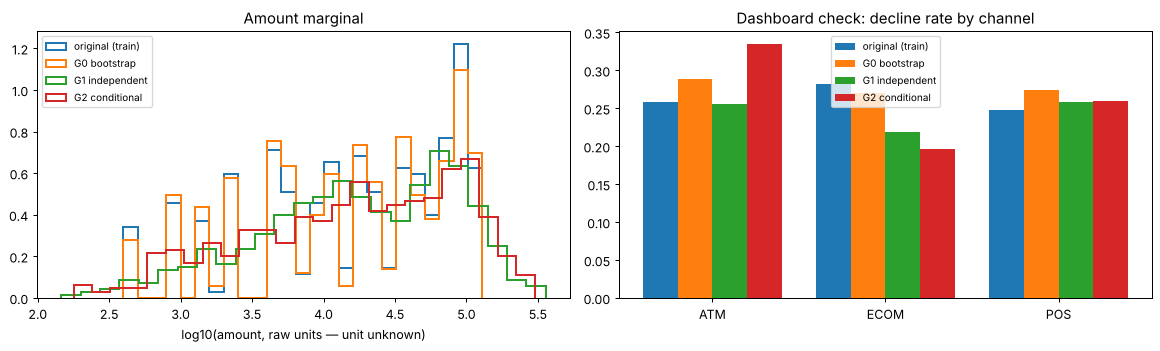

In [56]:
# 4(b)-1  Marginals, pairwise dependencies, validity, dashboard and TSTR classifier
pairs = [('channel', 'status'), ('status', 'respcode'), ('channel', 'city')]
utility_rows = []
sources = {'original (train)': syn_train, 'G0 bootstrap': synth['G0'], 'G1 independent': synth['G1'], 'G2 conditional': synth['G2']}
original_dash = syn_train.assign(d=syn_train['status'].eq('DECLINED')).groupby('channel')['d'].mean()
holdout_X = pd.get_dummies(syn_holdout[['channel', 'city']], dtype=float).reindex(
    columns=['channel_' + c for c in CATS['channel']] + ['city_' + c for c in CATS['city']], fill_value=0)
holdout_X['log_amount'] = np.log(syn_holdout['amount_raw_units'])
holdout_X['hour'] = syn_holdout['txn_hour']
holdout_y = syn_holdout['status'].eq('DECLINED').astype(int)
for label, frame in sources.items():
    row = {'dataset': label}
    for col in ['channel', 'city', 'status', 'respcode']:
        p_frame = frame[col].value_counts(normalize=True)
        p_orig = syn_train[col].value_counts(normalize=True)
        row['TVD_' + col] = round(0.5 * p_frame.subtract(p_orig, fill_value=0).abs().sum(), 3)
    row['KS_log_amount'] = round(ks_2samp(np.log(frame['amount_raw_units']), np.log(syn_train['amount_raw_units'])).statistic, 3)
    for left, right in pairs:
        chi2_value = chi2_contingency(pd.crosstab(frame[left], frame[right]))[0]
        k_min = min(frame[left].nunique(), frame[right].nunique()) - 1
        row['CramersV_' + left + '_' + right] = round(math.sqrt(chi2_value / (len(frame) * k_min)), 3)
    row['status_code_consistency'] = round(float(((frame['status'] == 'SUCCESS') == (frame['respcode'] == '00')).mean()), 3)
    dash = frame.assign(d=frame['status'].eq('DECLINED')).groupby('channel')['d'].mean()
    row['dashboard_max_err_decline_rate'] = round(float((dash - original_dash).abs().max()), 3)
    train_X = pd.get_dummies(frame[['channel', 'city']], dtype=float).reindex(columns=holdout_X.columns[:-2], fill_value=0)
    train_X['log_amount'] = np.log(frame['amount_raw_units'])
    train_X['hour'] = frame['txn_hour'].astype(int)
    clf = LogisticRegression(max_iter=2000).fit(train_X, frame['status'].eq('DECLINED').astype(int))
    row['TSTR_AUC_on_real_holdout'] = round(roc_auc_score(holdout_y, clf.predict_proba(holdout_X)[:, 1]), 3)
    utility_rows.append(row)
utility_table = pd.DataFrame(utility_rows)
utility_table.to_csv(EVID / 'Q4b_utility_table.csv', index=False)
display(utility_table.T)

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for label, frame in sources.items():
    axes[0].hist(np.log10(frame['amount_raw_units']), bins=25, histtype='step', density=True, lw=1.6, label=label)
axes[0].set_xlabel('log10(amount, raw units — unit unknown)')
axes[0].set_title('Amount marginal')
axes[0].legend(fontsize=8)
bar_width = 0.2
for position, (label, frame) in enumerate(sources.items()):
    dash = frame.assign(d=frame['status'].eq('DECLINED')).groupby('channel')['d'].mean().reindex(CATS['channel'])
    axes[1].bar(np.arange(3) + position * bar_width, dash.to_numpy(), width=bar_width, label=label)
axes[1].set_xticks(np.arange(3) + 1.5 * bar_width)
axes[1].set_xticklabels(CATS['channel'])
axes[1].set_title('Dashboard check: decline rate by channel')
axes[1].legend(fontsize=8)
plt.tight_layout()
plt.savefig(EVID / 'Q4b_utility_plots.png', dpi=140)
plt.show()

In [57]:
# 4(b)  TESTS
u = utility_table.set_index('dataset')
assert u.loc['G1 independent', 'status_code_consistency'] < 0.9          # G1 fabricates impossible SUCCESS/51 rows
assert u.loc['G2 conditional', 'status_code_consistency'] == 1.0         # G2 keeps the observed invariant
assert u.loc['G1 independent', 'CramersV_status_respcode'] < u.loc['G2 conditional', 'CramersV_status_respcode']
assert u.loc['G2 conditional', 'TVD_channel'] < 0.1 and u.loc['G2 conditional', 'KS_log_amount'] < 0.15
print('Q4(b) tests passed: G2 preserves marginals and the status/response dependency; G1 breaks it.')

Q4(b) tests passed: G2 preserves marginals and the status/response dependency; G1 breaks it.


**Utility interpretation.**
- **Both generators:** reproduce the channel, city and status marginals and the shape of the amount distribution (low TVD and KS values). Neither reproduces the exact price points of the source amounts.
- **G1:** fabricates independence. Its rows pair `SUCCESS` with decline codes, so a dashboard that validates those rules would raise false alarms. That is a fabricated relationship.
- **G2:** keeps the status → response-code structure (consistency = 1.0). It also **fabricates relationships**: the channel → status edge is near zero in the source (Cramér's V 0.03) but sampling noise in the learned conditional inflates it to about 0.13, which is why G2's dashboard decline-rate error (0.085) is slightly worse than G1's. It also **fabricates independence** for every pair that is not an edge, for example city–amount and day–status. A dashboard test that compares channels must therefore treat differences in G2 as artefacts, not findings.
- **Classifier holdout task:** a model trained on the *real* training data scores AUC ≈ 0.5 on the real holdout, so decline status carries no learnable signal in this synthetic source. TSTR AUCs near 0.5 therefore mean "no signal to preserve", not "the generator failed". For the vendor, the data is only fit to test pipeline **plumbing** (schema, class balance, edge cases), not model accuracy.

## 4(c) Disclosure risk: overlap, near neighbours, rare patterns and a red-team [3]

In [58]:
# 4(c)-1  Exact overlap, distance-to-closest-record (DCR), rare-pattern replication, membership proxy
FEATURE_COLS = ['channel_' + c for c in CATS['channel']] + ['city_' + c for c in CATS['city']]
day_index = {}
for position, day_value in enumerate(CATS['txn_day']):
    day_index[day_value] = position
mu_log = np.log(syn_train['amount_raw_units']).mean()
sd_log = np.log(syn_train['amount_raw_units']).std()
embedded = {}
for label, frame in [('train', syn_train), ('holdout', syn_holdout), ('G0', synth['G0']), ('G1', synth['G1']), ('G2', synth['G2'])]:
    matrix = pd.get_dummies(frame[['channel', 'city']], dtype=float).reindex(columns=FEATURE_COLS, fill_value=0)
    matrix['amount_z'] = (np.log(frame['amount_raw_units']) - mu_log) / sd_log
    matrix['day'] = frame['txn_day'].map(day_index) / 41
    matrix['hour'] = frame['txn_hour'].astype(int) / 23
    matrix['declined'] = frame['status'].eq('DECLINED').astype(float)
    embedded[label] = matrix.to_numpy()
key_cols = ['city', 'txn_day', 'channel', 'amount_raw_units']
train_unique_amounts = syn_train['amount_raw_units'].value_counts()
rare_amounts = set(train_unique_amounts[train_unique_amounts == 1].index)
nn_to_train = NearestNeighbors(n_neighbors=1).fit(embedded['train'])
holdout_dcr = nn_to_train.kneighbors(embedded['holdout'])[0][:, 0]
risk_rows = []
for label in ['G0', 'G1', 'G2']:
    frame = synth[label]
    exact_full = frame.merge(syn_train.drop_duplicates(), on=APPROVED_COLS, how='inner')
    exact_key = frame[key_cols].drop_duplicates().merge(syn_train[key_cols].drop_duplicates(), on=key_cols, how='inner')
    dcr = nn_to_train.kneighbors(embedded[label])[0][:, 0]
    nn_synth = NearestNeighbors(n_neighbors=1).fit(embedded[label])
    member_d = nn_synth.kneighbors(embedded['train'])[0][:, 0]
    nonmember_d = nn_synth.kneighbors(embedded['holdout'])[0][:, 0]
    mia_auc = roc_auc_score(np.r_[np.ones(len(member_d)), np.zeros(len(nonmember_d))], -np.r_[member_d, nonmember_d])
    risk_rows.append({'generator': label, 'exact_full_row_copies': len(exact_full),
                      'distinct_QI_keys_shared_with_train': len(exact_key),
                      'median_DCR': round(float(np.median(dcr)), 3), 'share_DCR_zero': round(float((dcr < 1e-9).mean()), 3),
                      'holdout_median_DCR_baseline': round(float(np.median(holdout_dcr)), 3),
                      'rare_amounts_replicated': int(len(rare_amounts.intersection(set(frame['amount_raw_units'])))),
                      'rare_amounts_in_train': len(rare_amounts),
                      'distance_MIA_AUC': round(float(mia_auc), 3)})
risk_table = pd.DataFrame(risk_rows)
risk_table.to_csv(EVID / 'Q4c_disclosure_risk.csv', index=False)
display(risk_table)

,generator,exact_full_row_copies,distinct_QI_keys_shared_with_train,median_DCR,share_DCR_zero,holdout_median_DCR_baseline,rare_amounts_replicated,rare_amounts_in_train,distance_MIA_AUC
0,G0,500,257,0.000,0.998,0.562,76,109,0.878
1,G1,0,0,0.508,0.000,0.562,2,109,0.520
2,G2,0,0,0.548,0.000,0.562,2,109,0.510


In [59]:
# 4(c)-2  Red-team: the attacker from Q3b observed a target purchase (city, day, channel, amount) in the TRAIN data
target_rng = np.random.default_rng(99)
targets = syn_train.loc[target_rng.choice(syn_train.index.to_numpy(), size=50, replace=False)]
redteam4_rows = []
for label in ['G0', 'G1', 'G2']:
    hits = targets.merge(synth[label], on=key_cols, how='left', suffixes=('_true', '_syn'))
    found = hits.dropna(subset=['status_syn']).drop_duplicates(subset=key_cols)
    correct = int((found['status_true'] == found['status_syn']).sum())
    redteam4_rows.append({'generator': label, 'targets': len(targets), 'targets_found_exactly': len(found),
                          'status_inferred_correctly': correct,
                          'KS_log_amount (similarity)': utility_table.set_index('dataset').loc[
                              {'G0': 'G0 bootstrap', 'G1': 'G1 independent', 'G2': 'G2 conditional'}[label], 'KS_log_amount']})
redteam4 = pd.DataFrame(redteam4_rows)
redteam4.to_csv(EVID / 'Q4c_redteam.csv', index=False)
display(redteam4)

,generator,targets,targets_found_exactly,status_inferred_correctly,KS_log_amount (similarity)
0,G0,50,36,36,0.029
1,G1,50,0,0,0.076
2,G2,50,0,0,0.088


In [60]:
# 4(c)  TESTS
r = risk_table.set_index('generator')
rt = redteam4.set_index('generator')
assert r.loc['G0', 'exact_full_row_copies'] > 100 and r.loc['G0', 'distance_MIA_AUC'] > 0.7        # control leaks
assert rt.loc['G0', 'KS_log_amount (similarity)'] <= 0.1 and rt.loc['G0', 'status_inferred_correctly'] >= 25  # similar AND leaky
assert r.loc['G2', 'exact_full_row_copies'] <= 2 and rt.loc['G2', 'targets_found_exactly'] <= 3
assert abs(r.loc['G2', 'distance_MIA_AUC'] - 0.5) < 0.1
print('Q4(c) tests passed: bootstrap looks statistically perfect yet discloses targets; G2 shows no exact-copy or MIA signal.')

Q4(c) tests passed: bootstrap looks statistically perfect yet discloses targets; G2 shows no exact-copy or MIA signal.


**Red-team finding.** The G0 bootstrap scores **best** on distributional similarity (KS ≈ 0), yet it copies hundreds of real rows. An attacker holding one observed purchase finds the exact row and reads its status. A distance-based membership test also separates training records from holdout records. **Distributional similarity alone would have approved the leakiest dataset.** For G2 the same attacks find (almost) nothing, and its DCR matches the holdout baseline. Absence of copies is *evidence*, not proof: G2's conditional tables are still functions of the source data, and smoothing is not differential privacy.

## 4(d) Release decision [1]

In [61]:
# 4(d)-1  Privacy–utility decision table
decision4 = pd.DataFrame([
    {'option': 'G0 bootstrap', 'utility': 'highest similarity', 'disclosure': 'copies real rows; target status inferred', 'decision': 'REJECT'},
    {'option': 'G1 independent marginals', 'utility': 'marginals only; invalid status/code rows', 'disclosure': 'low copy rate', 'decision': 'REJECT for dashboard rule tests'},
    {'option': 'G2 conditional network', 'utility': 'marginals + status/code + channel structure; no classifier signal', 'disclosure': 'no exact copies; MIA ~ chance in this test',
     'decision': 'RELEASE to vendor under contract, test purpose only'},
])
decision4.to_csv(EVID / 'Q4d_release_decision.csv', index=False)
display(decision4)

,option,utility,disclosure,decision
0,G0 bootstrap,highest similarity,copies real rows; target status inferred,REJECT
1,G1 independent marginals,marginals only; invalid status/code rows,low copy rate,REJECT for dashboard rule tests
2,G2 conditional network,marginals + status/code + channel structure; no classifier signal,no exact copies; MIA ~ chance in this test,"RELEASE to vendor under contract, test purpose only"


**Release decision (G2 only).**
- **Permitted purpose:** testing dashboard logic and classifier pipeline plumbing, in the vendor's non-production test environment.
- **Controls:**
  - a contract banning re-identification attempts, linkage and onward sharing;
  - deletion after 90 days;
  - no tokens, merchant ids or account structure in the data;
  - regeneration with a fresh seed for each vendor;
  - a DLP scan before transfer (Q2d);
  - a release logged in the audit trail.
- **Unacceptable remaining disclosures:**
  - generator parameters (conditional tables) must not be shared;
  - G2 must not be used for model accuracy claims or business decisions;
  - G2 must not be combined with any real Silver extract.

**Why synthetic ≠ anonymous ≠ DP.** Synthetic rows can still copy or closely resemble real ones (G0 shows this). "Anonymous" is a legal and contextual judgement about identifiability that no single metric settles. Differential privacy is a mathematical bound on what *any* output reveals about one account, and it requires calibrated noise and budget accounting. G2 has none of these, so it is neither anonymous by proof nor DP.

---
# QUESTION 5 — Person-level (account-level) differential-privacy release service [18]

Budget ceiling for **all** published statistics: **ε ≤ 2.0, δ ≤ 10⁻⁵**. Released noise comes from `secrets`-seeded randomness. Seeded generators are used **only** for offline accuracy simulation.

## 5(a) Neighbouring relation, contribution bounds and sensitivity [4]

- **Neighbouring datasets:** D and D′ differ by **adding or removing one account together with all of its transactions** (up to 9 here, unbounded in general).
- **Unit of contribution:** each account contributes exactly one row to an account-level table (built in 3(a)) before any query runs. This bounds influence regardless of how many transactions it has.
- **Clipping (public, fixed in policy before release):** per-account total value clipped to [0, B] with **B = 300,000 raw units**. The unit is unknown, so the value is reported in raw units. Binary attributes are already in {0, 1}.
- **Public:** query definitions, B, ε/δ allocations, mechanisms and the reporting window. **Not public:** the number of accounts, per-account values and the clipping rate (internal evaluation only).

| Query | Definition | Sensitivity (add/remove one account) |
|---|---|---|
| Q1 COUNT | number of distinct accounts | Δ₁ = 1 |
| Q2 SUM | Σ min(max(total_i, 0), B) | Δ₁ = B |
| Q3 MEAN | Q2 / max(Q1, floor), post-processing | no extra budget |
| Q4 DECLINE-ACCOUNTS (Gaussian) | Σ any_decline_i | Δ₂ = 1 |

In [62]:
# 5(a)-1  Account-level query inputs and the transaction-level counterexample
B_CLIP = 300_000
COUNT_FLOOR = 25                       # public denominator floor for the mean
dp_input = account_table[['acct_token', 'total_amount_raw', 'any_decline', 'transactions']].copy()
dp_input['clipped_total'] = dp_input['total_amount_raw'].clip(lower=0, upper=B_CLIP)

# Counterexample: adjacent dataset = D + one fictional account with 9 transactions of very large value
fake_txns = pd.DataFrame({'acct_token': ['acct_v1_counterexample'] * 9, 'amount_raw_units': [10 ** 9] * 9})
txn_rows_D = txn[['acct_token', 'amount_raw_units']]
txn_rows_D2 = pd.concat([txn_rows_D, fake_txns], ignore_index=True)
counter = pd.DataFrame([
    {'query': 'transaction-row COUNT', 'D': len(txn_rows_D), "D'": len(txn_rows_D2), 'change': len(txn_rows_D2) - len(txn_rows_D), 'claimed_sensitivity': 1},
    {'query': 'unbounded transaction SUM', 'D': int(txn_rows_D['amount_raw_units'].sum()), "D'": int(txn_rows_D2['amount_raw_units'].sum()),
     'change': int(txn_rows_D2['amount_raw_units'].sum() - txn_rows_D['amount_raw_units'].sum()), 'claimed_sensitivity': B_CLIP},
    {'query': 'account COUNT (ours)', 'D': txn_rows_D['acct_token'].nunique(), "D'": txn_rows_D2['acct_token'].nunique(),
     'change': txn_rows_D2['acct_token'].nunique() - txn_rows_D['acct_token'].nunique(), 'claimed_sensitivity': 1},
    {'query': 'account clipped SUM (ours)', 'D': int(dp_input['clipped_total'].sum()), "D'": int(dp_input['clipped_total'].sum() + min(9 * 10 ** 9, B_CLIP)),
     'change': min(9 * 10 ** 9, B_CLIP), 'claimed_sensitivity': B_CLIP}])
counter['violates_claim'] = counter['change'].abs() > counter['claimed_sensitivity']
counter.to_csv(EVID / 'Q5a_sensitivity_counterexample.csv', index=False)
display(counter)
assert counter.loc[0, 'violates_claim'] and counter.loc[1, 'violates_claim']
assert not counter.loc[2, 'violates_claim'] and not counter.loc[3, 'violates_claim']
print('Row-level count changes by 9 and unbounded sum by 9e9 for ONE account: they do not have the claimed sensitivity.')

Row-level count changes by 9 and unbounded sum by 9e9 for ONE account: they do not have the claimed sensitivity.


,query,D,D',change,claimed_sensitivity,violates_claim
0,transaction-row COUNT,500,509,9,1,True
1,unbounded transaction SUM,19157208,9019157208,9000000000,300000,True
2,account COUNT (ours),157,158,1,1,False
3,account clipped SUM (ours),18695303,18995303,300000,300000,False


## 5(b)–(c) Mechanisms, budget ledger and safe refusal [5 + 3]

**Composition rule:** basic sequential composition over the same accounts: ε_total = Σεᵢ and δ_total = Σδᵢ. This is conservative; mixing pure (Laplace) and approximate (Gaussian) DP under this rule is valid.

**Allocation:** COUNT ε = 0.5; SUM ε = 0.6; Gaussian DECLINE-ACCOUNTS ε = 0.8, δ = 10⁻⁵, with σ = Δ₂·√(2 ln(1.25/δ))/ε. The classical bound is valid here because ε < 1. **Total: ε = 1.9, δ = 10⁻⁵.**

The ledger checks the budget **before** any noise is drawn or any true value is touched. A repeated request returns the **cached** published answer: fresh noise would let an attacker average repeated answers.

In [63]:
# 5(b)-1  Release service: requests processed in order through the ledger
DP_RNG = np.random.default_rng(secrets.randbits(128))     # unpredictable; never stored or printed
BUDGET = {'epsilon': 2.0, 'delta': 1e-5}
ledger_rows = []
published = {}
internal_truth = {}
spent = {'epsilon': 0.0, 'delta': 0.0}
release_requests = [
    {'query_id': 'Q1_COUNT_ACCOUNTS', 'mechanism': 'laplace', 'epsilon': 0.5, 'delta': 0.0, 'sensitivity': 1},
    {'query_id': 'Q2_SUM_CLIPPED_VALUE', 'mechanism': 'laplace', 'epsilon': 0.6, 'delta': 0.0, 'sensitivity': B_CLIP},
    {'query_id': 'Q4_DECLINE_ACCOUNTS', 'mechanism': 'gaussian', 'epsilon': 0.8, 'delta': 1e-5, 'sensitivity': 1},
    {'query_id': 'Q1_COUNT_ACCOUNTS', 'mechanism': 'laplace', 'epsilon': 0.5, 'delta': 0.0, 'sensitivity': 1},          # repeat
    {'query_id': 'Q5_CITY_HISTOGRAM', 'mechanism': 'laplace', 'epsilon': 0.3, 'delta': 0.0, 'sensitivity': 1},          # excessive
    {'query_id': 'Q4_DECLINE_ACCOUNTS_FRESH', 'mechanism': 'gaussian', 'epsilon': 0.8, 'delta': 1e-5, 'sensitivity': 1}, # excessive
]
for request in release_requests:
    entry = {'query_id': request['query_id'], 'mechanism': request['mechanism'], 'epsilon_requested': request['epsilon'],
             'delta_requested': request['delta']}
    if request['query_id'] in published:
        entry.update({'decision': 'SERVED FROM CACHE', 'epsilon_charged': 0.0, 'delta_charged': 0.0})
    elif spent['epsilon'] + request['epsilon'] > BUDGET['epsilon'] + 1e-12 or spent['delta'] + request['delta'] > BUDGET['delta'] + 1e-18:
        entry.update({'decision': 'BLOCKED: would exceed budget (no computation run)', 'epsilon_charged': 0.0, 'delta_charged': 0.0})
    else:
        if request['query_id'] == 'Q1_COUNT_ACCOUNTS':
            true_value = float(len(dp_input))
        elif request['query_id'] == 'Q2_SUM_CLIPPED_VALUE':
            true_value = float(dp_input['clipped_total'].sum())
        else:
            true_value = float(dp_input['any_decline'].sum())
        if request['mechanism'] == 'laplace':
            scale = request['sensitivity'] / request['epsilon']
            noisy = true_value + DP_RNG.laplace(0, scale)
        else:
            scale = request['sensitivity'] * math.sqrt(2 * math.log(1.25 / request['delta'])) / request['epsilon']
            noisy = true_value + DP_RNG.normal(0, scale)
        published[request['query_id']] = noisy
        internal_truth[request['query_id']] = true_value
        spent['epsilon'] = spent['epsilon'] + request['epsilon']
        spent['delta'] = spent['delta'] + request['delta']
        entry.update({'decision': 'RELEASED', 'epsilon_charged': request['epsilon'], 'delta_charged': request['delta'], 'noise_scale': round(scale, 3)})
    entry['epsilon_spent_after'] = round(spent['epsilon'], 3)
    entry['delta_spent_after'] = spent['delta']
    ledger_rows.append(entry)
    AUDIT.append({'time': datetime.now(timezone.utc).isoformat(), 'principal': 'dp-release-svc', 'role': 'dp_service',
                  'action': 'DPRelease', 'resource': request['query_id'], 'decision': 'DENY' if entry['decision'].startswith('BLOCKED') else 'ALLOW',
                  'reason': entry['decision'] + ' eps=' + str(request['epsilon'])})
dp_ledger = pd.DataFrame(ledger_rows)
dp_ledger.to_csv(EVID / 'Q5c_privacy_budget_ledger.csv', index=False)
display(dp_ledger)

# Post-processing (free): non-negative integer count; mean with denominator floor and clipping; declines <= count
release_count = max(0, int(round(published['Q1_COUNT_ACCOUNTS'])))
if release_count >= COUNT_FLOOR:
    release_mean = float(np.clip(published['Q2_SUM_CLIPPED_VALUE'] / release_count, 0, B_CLIP))
    mean_note = 'noisy SUM / noisy COUNT, clipped to [0, B]'
else:
    release_mean = None
    mean_note = 'withheld: noisy count below public floor'
release_declines = int(np.clip(round(published['Q4_DECLINE_ACCOUNTS']), 0, release_count))
dp_release = pd.DataFrame([
    {'statistic': 'Active accounts (distinct)', 'published_value': release_count, 'mechanism': 'Laplace, Δ1=1, ε=0.5'},
    {'statistic': 'Mean clipped account value (raw units)', 'published_value': None if release_mean is None else round(release_mean, 0),
     'mechanism': 'post-processing of Laplace SUM (Δ1=B, ε=0.6) and COUNT; ' + mean_note},
    {'statistic': 'Accounts with ≥1 recorded decline', 'published_value': release_declines, 'mechanism': 'Gaussian, Δ2=1, ε=0.8, δ=1e-5'}])
dp_release.to_csv(ROOT / ZONE_DIRS['release'] / 'dp_release_v1.csv', index=False)
dp_release.to_csv(EVID / 'Q5b_dp_release_PUBLIC.csv', index=False)
print('PUBLIC DP RELEASE (the only figures that leave the service):')
display(dp_release)
# internal-only evaluation (restricted; never released or zipped)
pd.DataFrame({'query_id': list(internal_truth), 'true_value_INTERNAL': list(internal_truth.values()),
              'noisy_value': [published[q] for q in internal_truth]}).to_csv(RESTRICTED_EVAL / 'dp_internal_evaluation_RESTRICTED.csv', index=False)
print('Internal only: clipping affected', int((dp_input['total_amount_raw'] > B_CLIP).sum()), 'accounts (not published).')

PUBLIC DP RELEASE (the only figures that leave the service):
Internal only: clipping affected 4 accounts (not published).


,query_id,mechanism,epsilon_requested,delta_requested,decision,epsilon_charged,delta_charged,noise_scale,epsilon_spent_after,delta_spent_after
0,Q1_COUNT_ACCOUNTS,laplace,0.5,0.00000,RELEASED,0.5,0.00000,2.000,0.5,0.00000
1,Q2_SUM_CLIPPED_VALUE,laplace,0.6,0.00000,RELEASED,0.6,0.00000,500000.000,1.1,0.00000
2,Q4_DECLINE_ACCOUNTS,gaussian,0.8,0.00001,RELEASED,0.8,0.00001,6.056,1.9,0.00001
3,Q1_COUNT_ACCOUNTS,laplace,0.5,0.00000,SERVED FROM CACHE,0.0,0.00000,NaN,1.9,0.00001
4,Q5_CITY_HISTOGRAM,laplace,0.3,0.00000,BLOCKED: would exceed budget (no computation run),0.0,0.00000,NaN,1.9,0.00001
5,Q4_DECLINE_ACCOUNTS_FRESH,gaussian,0.8,0.00001,BLOCKED: would exceed budget (no computation run),0.0,0.00000,NaN,1.9,0.00001


,statistic,published_value,mechanism
0,Active accounts (distinct),159.0,"Laplace, Δ1=1, ε=0.5"
1,Mean clipped account value (raw units),113492.0,"post-processing of Laplace SUM (Δ1=B, ε=0.6) and COUNT; noisy SUM / noisy COUNT, clipped to [0, B]"
2,Accounts with ≥1 recorded decline,92.0,"Gaussian, Δ2=1, ε=0.8, δ=1e-5"


In [64]:
# 5(c)  TESTS — budget proof and safe refusal
charged = dp_ledger[dp_ledger['decision'] == 'RELEASED']
assert charged['epsilon_charged'].sum() <= BUDGET['epsilon'] and charged['delta_charged'].sum() <= BUDGET['delta']
assert round(charged['epsilon_charged'].sum(), 6) == 1.9 and charged['delta_charged'].sum() == 1e-5
assert (dp_ledger['decision'].str.startswith('BLOCKED')).sum() == 2              # both excessive queries refused
assert 'Q5_CITY_HISTOGRAM' not in published and 'Q4_DECLINE_ACCOUNTS_FRESH' not in published
assert dp_ledger.loc[3, 'decision'] == 'SERVED FROM CACHE' and dp_ledger.loc[3, 'epsilon_charged'] == 0
assert 'true_value' not in ' '.join(dp_release.columns)
print('Q5(c) tests passed: ε_total = 1.9 ≤ 2.0, δ_total = 1e-5 ≤ 1e-5 (basic composition); excess queries blocked before release.')

Q5(c) tests passed: ε_total = 1.9 ≤ 2.0, δ_total = 1e-5 ≤ 1e-5 (basic composition); excess queries blocked before release.


**What is private and what is internal.**
- **Private (public outputs):** the three published figures in `dp_release_v1.csv`.
- **Internal (restricted folder only, never released):** the noisy SUM, the true values, the clipping rate and the errors. A real deployment would delete them after evaluation.
- **Mean:** pure post-processing of two DP outputs, so it costs no extra budget. The public floor (25) avoids dividing by a tiny or negative noisy count. The ratio estimator is biased when counts are small.
- **Laplace sampling:** this uses floating-point Laplace sampling, which has known precision attacks. A production service would use a vetted library (for example OpenDP or Google DP) with secure noise.

## 5(d) Accuracy for three predeclared ε allocations (offline simulation) [3]

,allocation,eps_total,COUNT_MAE,SUM_rel_MAE_%,MEAN_rel_MAE_%,MEAN_rel_p95_%,DECLINES_MAE (Gaussian),sigma_gauss
0,A1 conservative (0.3/0.3/0.6),1.2,3.24,5.48,5.94,16.69,6.35,8.07
1,A2 chosen (0.5/0.6/0.8),1.9,2.10,2.68,3.20,8.94,4.96,6.06
2,A3 sum-heavy (0.3/0.9/0.7),1.9,3.36,1.85,2.97,8.04,5.67,6.92


,query,sensitivity,scale_at_eps_0.5
0,COUNT,1.0,2.0
1,SUM,300000.0,600000.0
2,MEAN (effective),1910.8,3821.7


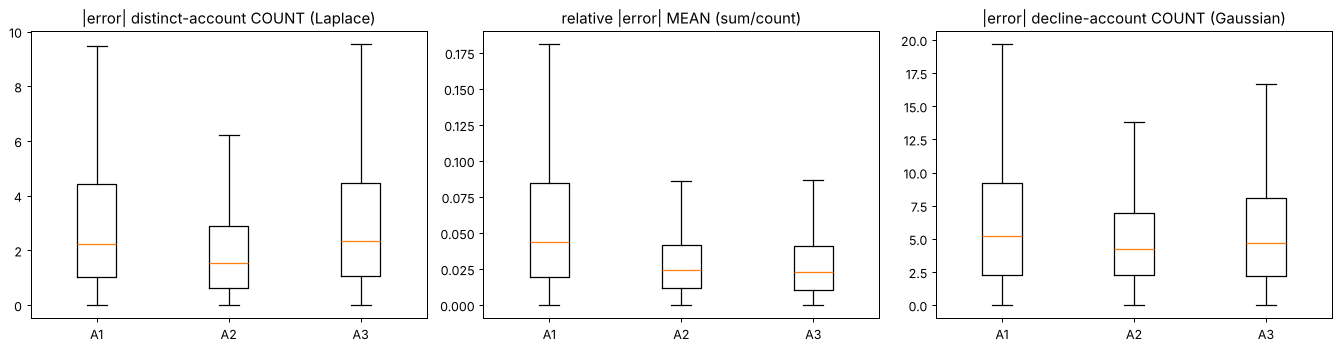

In [65]:
# 5(d)-1  1,000 candidate noise draws per setting — offline, seeded, NOT released
allocations = {'A1 conservative (0.3/0.3/0.6)': (0.3, 0.3, 0.6), 'A2 chosen (0.5/0.6/0.8)': (0.5, 0.6, 0.8),
               'A3 sum-heavy (0.3/0.9/0.7)': (0.3, 0.9, 0.7)}
sim_rng = np.random.default_rng(20261117)
true_n = float(len(dp_input))
true_sum = float(dp_input['clipped_total'].sum())
true_mean = true_sum / true_n
true_decl = float(dp_input['any_decline'].sum())
sim_rows = []
sim_draws = {}
for label, (eps_c, eps_s, eps_g) in allocations.items():
    assert eps_c + eps_s + eps_g <= 2.0 and eps_g < 1
    noisy_n = true_n + sim_rng.laplace(0, 1 / eps_c, 1000)
    noisy_s = true_sum + sim_rng.laplace(0, B_CLIP / eps_s, 1000)
    noisy_mean = np.clip(noisy_s / np.maximum(noisy_n, COUNT_FLOOR), 0, B_CLIP)
    sigma_g = math.sqrt(2 * math.log(1.25 / 1e-5)) / eps_g
    noisy_d = true_decl + sim_rng.normal(0, sigma_g, 1000)
    sim_draws[label] = {'count': np.abs(noisy_n - true_n), 'mean_rel': np.abs(noisy_mean - true_mean) / true_mean,
                        'declines': np.abs(noisy_d - true_decl)}
    sim_rows.append({'allocation': label, 'eps_total': round(eps_c + eps_s + eps_g, 2),
                     'COUNT_MAE': round(float(sim_draws[label]['count'].mean()), 2),
                     'SUM_rel_MAE_%': round(100 * float((np.abs(noisy_s - true_sum) / true_sum).mean()), 2),
                     'MEAN_rel_MAE_%': round(100 * float(sim_draws[label]['mean_rel'].mean()), 2),
                     'MEAN_rel_p95_%': round(100 * float(np.percentile(sim_draws[label]['mean_rel'], 95)), 2),
                     'DECLINES_MAE (Gaussian)': round(float(sim_draws[label]['declines'].mean()), 2),
                     'sigma_gauss': round(sigma_g, 2)})
accuracy = pd.DataFrame(sim_rows)
accuracy.to_csv(EVID / 'Q5d_accuracy_simulation.csv', index=False)
display(accuracy)

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for position, metric in enumerate(['count', 'mean_rel', 'declines']):
    axes[position].boxplot([sim_draws[label][metric] for label in allocations], showfliers=False)
    axes[position].set_xticks([1, 2, 3])
    axes[position].set_xticklabels(['A1', 'A2', 'A3'])
axes[0].set_title('|error| distinct-account COUNT (Laplace)')
axes[1].set_title('relative |error| MEAN (sum/count)')
axes[2].set_title('|error| decline-account COUNT (Gaussian)')
plt.tight_layout()
plt.savefig(EVID / 'Q5d_error_plots.png', dpi=140)
plt.show()
sensitivity_compare = pd.DataFrame({'query': ['COUNT', 'SUM', 'MEAN (effective)'],
                                    'sensitivity': [1, B_CLIP, round(B_CLIP / true_n, 1)],
                                    'scale_at_eps_0.5': [2, 2 * B_CLIP, round(2 * B_CLIP / true_n, 1)]})
display(sensitivity_compare)
assert accuracy.loc[0, 'COUNT_MAE'] > accuracy.loc[1, 'COUNT_MAE']        # smaller ε -> larger error
assert accuracy.loc[2, 'SUM_rel_MAE_%'] < accuracy.loc[1, 'SUM_rel_MAE_%']

**Interpretation.**
- **COUNT:** has sensitivity 1, so even ε = 0.3 errs by only a few accounts.
- **SUM:** has sensitivity B = 300,000. A single account can move it by up to B, so its noise is proportionally larger, and it drives the error in the mean.
- **MEAN:** behaves like a query with sensitivity of roughly B/n. With only about 157 accounts that is still large: several percent relative error in A2.
- **A3:** spends more budget on the sum, which improves the mean but worsens the count and the Gaussian statistic.
- **Gaussian query:** its σ (≈ 6.1 at ε = 0.8) is larger than the equivalent Laplace scale. The δ slack buys a lighter tail, not lower error, at this ε.
- **Choice:** A2 balances the three published figures. The simulation spent no privacy budget because nothing was released.

## 5(e) Adjacent-account counterfactual and limits of empirical testing [3]

In [66]:
# 5(e)-1  D' = D minus the account with the most transactions
heaviest = dp_input.sort_values(['transactions', 'acct_token'], ascending=[False, True]).iloc[0]
d_prime = dp_input[dp_input['acct_token'] != heaviest['acct_token']]
adj = pd.DataFrame([
    {'query': 'COUNT accounts', 'D': len(dp_input), "D'": len(d_prime), 'bound': 1},
    {'query': 'SUM clipped', 'D': dp_input['clipped_total'].sum(), "D'": d_prime['clipped_total'].sum(), 'bound': B_CLIP},
    {'query': 'DECLINE accounts', 'D': dp_input['any_decline'].sum(), "D'": d_prime['any_decline'].sum(), 'bound': 1},
    {'query': 'transaction rows (NOT used)', 'D': dp_input['transactions'].sum(), "D'": d_prime['transactions'].sum(), 'bound': 1}])
adj['abs_change'] = (adj['D'] - adj["D'"]).abs()
adj['within_bound'] = adj['abs_change'] <= adj['bound']
display(adj)
assert adj.loc[:2, 'within_bound'].all() and not adj.loc[3, 'within_bound']

# Empirical privacy-loss check for the Laplace COUNT (offline; evidence, not proof)
check_rng = np.random.default_rng(7)
eps_check = 0.5
draws_D = np.round(len(dp_input) + check_rng.laplace(0, 1 / eps_check, 400_000))
draws_Dp = np.round(len(d_prime) + check_rng.laplace(0, 1 / eps_check, 400_000))
bins = np.arange(len(dp_input) - 8, len(dp_input) + 8).astype(float)
freq_D = pd.Series(draws_D).value_counts().reindex(bins, fill_value=0)
freq_Dp = pd.Series(draws_Dp).value_counts().reindex(bins, fill_value=0)
log_ratio = np.log(freq_D / freq_Dp).replace([np.inf, -np.inf], np.nan).dropna()
print('Max observed |log P(D)/P(D\')| over central bins:', round(float(log_ratio.abs().max()), 3), '| ε =', eps_check)
assert log_ratio.abs().max() <= eps_check + 0.08

# Output-domain post-processing and reproducibility checks
assert release_count >= 0 and isinstance(release_count, int) and 0 <= release_declines <= release_count
assert release_mean is None or 0 <= release_mean <= B_CLIP
query_spec = json.dumps({'queries': release_requests[:3], 'B': B_CLIP, 'floor': COUNT_FLOOR, 'neighbour': 'add/remove one account'}, sort_keys=True)
print('Query-spec fingerprint (stable across runs):', hashlib.sha256(query_spec.encode()).hexdigest()[:16])

# A random seed is NOT a privacy guarantee: a known seed lets an attacker regenerate and subtract the noise
seeded_noise = np.random.default_rng(5211).laplace(0, 2.0)
leaky_release = len(dp_input) + seeded_noise
attacker_recovers = leaky_release - np.random.default_rng(5211).laplace(0, 2.0)
assert round(float(attacker_recovers), 9) == len(dp_input)
print('Seeded "DP" count fully reversed by an attacker who knows the seed -> recovered exact value:', round(float(attacker_recovers), 9) == len(dp_input))

# Releasing de-identified microdata ALONGSIDE the DP answer
exact_from_microdata = int(release_r2['any_decline'].sum())
print('If R2 account-level microdata were also published, the exact decline-account count is', exact_from_microdata,
      '-> the Gaussian noise protects nothing at system level.')
assert exact_from_microdata == int(dp_input['any_decline'].sum())

Max observed |log P(D)/P(D')| over central bins: 0.518 | ε = 0.5
Query-spec fingerprint (stable across runs): 9648450c014c8dfe
Seeded "DP" count fully reversed by an attacker who knows the seed -> recovered exact value: True
If R2 account-level microdata were also published, the exact decline-account count is 91 -> the Gaussian noise protects nothing at system level.


,query,D,D',bound,abs_change,within_bound
0,COUNT accounts,157,156,1,1,True
1,SUM clipped,18695303,18424245,300000,271058,True
2,DECLINE accounts,91,90,1,1,True
3,transaction rows (NOT used),500,491,1,9,False


**Why tests are not a proof.**
- **What the tests show:** the counterfactual confirms each query moves by at most its claimed sensitivity on *one* neighbour. The histogram log-ratio stays within sampling error of ε (about 0.52 observed for ε = 0.5) on the bins we sampled.
- **What they cannot show:** DP is a worst-case statement over **all** neighbouring datasets and **all** output sets, including tail events that a simulation rarely samples. It also depends on implementation details (floating-point noise, timing, the cache) that a test does not observe. The guarantee rests on the derivation (sensitivity + mechanism + composition), and the tests can only falsify it.
- **System-level risk:** DP bounds what *these outputs* reveal. If de-identified microdata (R1/R2) or the Q2 exact aggregates are released for the same accounts, the attacker reads the exact answers there. The ε guarantee does not cover the combined system, so the DP release must be the **only** public channel for these statistics.

---
# QUESTION 6 — Federated alternative and PET choices [14]

## 6(a) Three disjoint institutions by deterministic account-level assignment [3]

**Rule (documented, deterministic, account-level):** `bucket = int(SHA-256("partition-v1|" + ACCT1)[:8], 16) mod 100`. Buckets 0–44 go to **Inst_A**, 45–84 to **Inst_B**, and 85–99 to **Inst_C**, the deliberately small institution.

The rule runs inside the tokenisation boundary, where `ACCT1` is available. Only the institution label is attached to the token. Because the hash input is the account, every transaction of an account goes to the same institution, and the result is identical on every run.

In [67]:
# 6(a)-1  Partition accounts (inside TB2 via the token vault), then report approved metadata only
institution_of_token = {}
for token, account in TOKEN_VAULT.items():
    bucket = int(hashlib.sha256(('partition-v1|' + account).encode()).hexdigest()[:8], 16) % 100
    institution_of_token[token] = 'Inst_A' if bucket < 45 else ('Inst_B' if bucket < 85 else 'Inst_C')
fed = account_table[['acct_token', 'any_decline', 'total_amount_raw']].copy()
fed['institution'] = fed['acct_token'].map(institution_of_token)
fed['clipped_total'] = fed['total_amount_raw'].clip(0, B_CLIP)
SITES = ['Inst_A', 'Inst_B', 'Inst_C']
site_data = {}
for site in SITES:
    site_data[site] = fed[fed['institution'] == site].reset_index(drop=True)     # stays "local" to the site
approved_metadata = pd.DataFrame({'institution': SITES,
                                  'accounts_rounded_to_5': [int(5 * round(len(site_data[s]) / 5)) for s in SITES],
                                  'size_class': ['large' if len(site_data[s]) >= 40 else 'small' for s in SITES]})
approved_metadata.to_csv(EVID / 'Q6a_approved_partition_metadata.csv', index=False)
display(approved_metadata)

# Counterexample: partitioning by TRANSACTION ROW (hash of the case token) splits accounts across institutions
row_site = []
for token in txn['case_token']:
    row_bucket = int(hashlib.sha256(('partition-v1|' + token).encode()).hexdigest()[:8], 16) % 100
    row_site.append('Inst_A' if row_bucket < 45 else ('Inst_B' if row_bucket < 85 else 'Inst_C'))
row_partition = txn[['acct_token']].assign(institution=row_site)
split_accounts = int((row_partition.groupby('acct_token')['institution'].nunique() > 1).sum())
row_distinct_sum = int(row_partition.groupby('institution')['acct_token'].nunique().sum())
print('Row-level partition: accounts split across institutions =', split_accounts,
      '| sum of per-site distinct accounts =', row_distinct_sum, 'vs true 157')

Row-level partition: accounts split across institutions = 103 | sum of per-site distinct accounts = 299 vs true 157


,institution,accounts_rounded_to_5,size_class
0,Inst_A,75,large
1,Inst_B,65,large
2,Inst_C,20,small


In [68]:
# 6(a)  TESTS
sets_by_site = [set(site_data[s]['acct_token']) for s in SITES]
assert sets_by_site[0].isdisjoint(sets_by_site[1]) and sets_by_site[0].isdisjoint(sets_by_site[2]) and sets_by_site[1].isdisjoint(sets_by_site[2])
assert sum(len(x) for x in sets_by_site) == 157 and set().union(*sets_by_site) == set(account_table['acct_token'])
assert len(site_data['Inst_C']) < 0.5 * min(len(site_data['Inst_A']), len(site_data['Inst_B']))   # one substantially smaller site
assert split_accounts > 0 and row_distinct_sum > 157                                               # negative: row partition invalid
print('Q6(a) tests passed: three disjoint, exhaustive, account-level partitions; row-level partitioning shown invalid.')

Q6(a) tests passed: three disjoint, exhaustive, account-level partitions; row-level partitioning shown invalid.


**Why not partition by transaction row:** the same account would appear at two or three institutions. That breaks "each institution holds its own customers", double-counts distinct accounts (the sum above exceeds 157), and multiplies one account's influence across sites, which invalidates the per-account sensitivity used in Q5.

## 6(b) Federated weighted mean vs naïve site average [3]

**Statistic:** the mean clipped account value, bounded to [0, B]. Each site sends only `(sum of clipped values, number of accounts)`.

In [69]:
# 6(b)-1  Local computation -> shared aggregates -> coordinator
site_reports = []
for site in SITES:
    local = site_data[site]
    site_reports.append({'institution': site, 'local_sum': int(local['clipped_total'].sum()), 'local_count': len(local),
                         'local_mean': float(local['clipped_total'].mean()),
                         'local_decline_prevalence': float(local['any_decline'].mean())})
site_reports = pd.DataFrame(site_reports)
central_mean = float(fed['clipped_total'].mean())                                        # benchmark (centralised)
naive_mean = float(site_reports['local_mean'].mean())                                     # unweighted average of site means
weighted_mean = float(site_reports['local_sum'].sum() / site_reports['local_count'].sum())
central_prev = float(fed['any_decline'].mean())
naive_prev = float(site_reports['local_decline_prevalence'].mean())
weighted_prev = float((site_reports['local_decline_prevalence'] * site_reports['local_count']).sum() / site_reports['local_count'].sum())
fed_compare = pd.DataFrame({'method': ['central benchmark', 'naive unweighted site average', 'correct weighted (Σsum/Σcount)'],
                            'mean_clipped_value': [central_mean, naive_mean, weighted_mean],
                            'decline_prevalence': [central_prev, naive_prev, weighted_prev]})
fed_compare['bias_vs_central_value'] = fed_compare['mean_clipped_value'] - central_mean
fed_compare['bias_vs_central_prevalence'] = fed_compare['decline_prevalence'] - central_prev
fed_compare.round(4).to_csv(EVID / 'Q6b_federated_comparison.csv', index=False)
display(fed_compare.round(4))
assert math.isclose(weighted_mean, central_mean, rel_tol=1e-12) and math.isclose(weighted_prev, central_prev, rel_tol=1e-12)
assert abs(naive_mean - central_mean) > 0 and abs(naive_prev - central_prev) > 0
print('Q6(b) tests passed: weighted federated result equals the central benchmark exactly; naive average is biased.')

Q6(b) tests passed: weighted federated result equals the central benchmark exactly; naive average is biased.


,method,mean_clipped_value,decline_prevalence,bias_vs_central_value,bias_vs_central_prevalence
0,central benchmark,119078.3631,0.5796,0.0000,0.000
1,naive unweighted site average,115910.4829,0.5616,-3167.8802,-0.018
2,correct weighted (Σsum/Σcount),119078.3631,0.5796,0.0000,0.000


**Bias and denominators.**
- **Bias:** the naïve average gives the small Inst_C the same weight as the large sites, so its local mean pulls the result off the benchmark. The weighted aggregate Σsum/Σcount is exact.
- **Denominator disclosure:** correct weighting needs counts, but per-site counts reveal each institution's customer base, which is business-confidential. They also enable differencing: a later round without Inst_C would reveal Inst_C's sum. And a small site's per-site sum and count are close to individual-level data.
- **Mitigations:**
  - aggregate numerators **and** denominators only through secure summation (6c), so the coordinator sees just Σsum and Σcount;
  - apply DP noise to the totals (Q5);
  - enforce a minimum cohort (6d).

## 6(c) Toy additive-mask secure sum, traced [3]

Work in the prime field $\mathbb{Z}_M$ with $M = 2^{61}-1$. Each pair (i, j) with i < j shares a mask r_ij, drawn from `secrets`. Client i sends

$y_i = x_i + \sum_{j>i} r_{ij} - \sum_{j<i} r_{ji} \pmod M$

The masks cancel in Σy. Two values are summed securely: `local_sum` and `local_count`.

In [70]:
# 6(c)-1  One round, fully traced
M = 2 ** 61 - 1
pair_masks = {}
for i in range(3):
    for j in range(i + 1, 3):
        pair_masks[(SITES[i], SITES[j])] = {'sum': secrets.randbelow(M), 'count': secrets.randbelow(M)}
trace_rows = []
coordinator_view = {}
for i in range(3):
    site = SITES[i]
    x_sum = int(site_reports.loc[i, 'local_sum'])
    x_count = int(site_reports.loc[i, 'local_count'])
    y_sum = x_sum
    y_count = x_count
    for (a, b), masks in pair_masks.items():
        if a == site:
            y_sum = (y_sum + masks['sum']) % M
            y_count = (y_count + masks['count']) % M
        if b == site:
            y_sum = (y_sum - masks['sum']) % M
            y_count = (y_count - masks['count']) % M
    coordinator_view[site] = (y_sum, y_count)
    trace_rows.append({'institution': site, 'x_sum (local only)': x_sum, 'x_count (local only)': x_count,
                       'y_sum sent': y_sum, 'y_count sent': y_count})
trace = pd.DataFrame(trace_rows)
display(trace)
secure_sum = sum(v[0] for v in coordinator_view.values()) % M
secure_count = sum(v[1] for v in coordinator_view.values()) % M
print('Coordinator reconstructs Σsum =', secure_sum, 'and Σcount =', secure_count, '-> mean =', round(secure_sum / secure_count, 2))
trace[['institution', 'y_sum sent', 'y_count sent']].to_csv(EVID / 'Q6c_coordinator_view_masked.csv', index=False)

# Indistinguishability experiment (simulation of many rounds): the coordinator's view of Inst_C is ~uniform
# whether Inst_C's true sum is small or large. Seeded ONLY to make the experiment reproducible.
sim_mask_rng = np.random.default_rng(611)
ks_results = {}
for candidate_value in [1_000, 9_000_000]:
    masks_ac = sim_mask_rng.integers(0, M, 5000, dtype=np.int64)
    masks_bc = sim_mask_rng.integers(0, M, 5000, dtype=np.int64)
    y_c = (candidate_value - masks_ac.astype(object) - masks_bc.astype(object)) % M
    ks_results[candidate_value] = ks_2samp(np.array(y_c, dtype=float) / M, sim_mask_rng.random(5000)).statistic
print('KS distance of y_C/M from Uniform(0,1): true x_C=1,000 ->', round(ks_results[1_000], 4),
      '| x_C=9,000,000 ->', round(ks_results[9_000_000], 4))

Coordinator reconstructs Σsum = 18695303 and Σcount = 157 -> mean = 119078.36
KS distance of y_C/M from Uniform(0,1): true x_C=1,000 -> 0.0186 | x_C=9,000,000 -> 0.0182


,institution,x_sum (local only),x_count (local only),y_sum sent,y_count sent
0,Inst_A,8408425,74,2061655061564016180,2232896465806940374
1,Inst_B,8398836,65,1539038080164522542,961946641238075574
2,Inst_C,1888042,18,1010992876717544483,1416842911382372111


In [71]:
# 6(c)  TESTS
assert secure_sum == int(site_reports['local_sum'].sum()) and secure_count == int(site_reports['local_count'].sum())   # cancellation
assert math.isclose(secure_sum / secure_count, central_mean, rel_tol=1e-12)
for i in range(3):
    assert trace.loc[i, 'y_sum sent'] != trace.loc[i, 'x_sum (local only)'] and trace.loc[i, 'y_count sent'] != trace.loc[i, 'x_count (local only)']
assert ks_results[1_000] < 0.05 and ks_results[9_000_000] < 0.05            # view is uniform-looking for both inputs
# negative: if one client "forgets" its mask, the coordinator sees the raw value
unmasked_c = int(site_reports.loc[2, 'local_sum'])
assert unmasked_c == int(site_data['Inst_C']['clipped_total'].sum())
print('Q6(c) tests passed: masks cancel exactly; individual masked inputs are uniform-looking; aggregate equals benchmark.')

Q6(c) tests passed: masks cancel exactly; individual masked inputs are uniform-looking; aggregate equals benchmark.


**What this toy does NOT establish:**
- authenticated pairwise key agreement (the masks here come from one Python process);
- security against a malicious coordinator or malicious clients (no input-range proofs, so a client can send any value);
- collusion resistance: **two** colluding institutions learn the third's value from the total minus their own;
- dropout tolerance (see 6d);
- protection against replay or round mixing;
- integrity of the result;
- any protection of the **output** itself: the total remains exact, so DP is still needed;
- side channels and timing.

Under the stated toy assumptions only (honest-but-curious coordinator, no collusion, uniform secret masks, every client completes the round), the coordinator learns the aggregate and nothing more about the individual x_i.

## 6(d) Dropout after masks are exchanged [2]

In [72]:
# 6(d)-1  Inst_C disconnects after mask exchange, before sending y_C
partial_sum = (coordinator_view['Inst_A'][0] + coordinator_view['Inst_B'][0]) % M
true_ab = int(site_reports.loc[0, 'local_sum'] + site_reports.loc[1, 'local_sum'])
print('Coordinator total with C missing:', partial_sum, '| true A+B:', true_ab, '-> garbage (uncancelled masks)')
assert partial_sum != true_ab and partial_sum != int(site_reports['local_sum'].sum())

# Toy recovery: survivors reveal masks they shared with C -> coordinator obtains A+B
recovered_ab = (partial_sum - pair_masks[('Inst_A', 'Inst_C')]['sum'] - pair_masks[('Inst_B', 'Inst_C')]['sum']) % M
assert recovered_ab == true_ab
# ...but the A+B partial combined with the full 3-site total from the completed round exposes Inst_C exactly
exposed_c = (secure_sum - recovered_ab) % M
assert exposed_c == int(site_reports.loc[2, 'local_sum'])
print('Recovered A+B =', recovered_ab, '| differencing with the full-round total reveals Inst_C sum =', exposed_c, '(= true value)')
AUDIT.append({'time': datetime.now(timezone.utc).isoformat(), 'principal': 'fed-coordinator', 'role': 'coordinator',
              'action': 'SecureSumRound', 'resource': 'round-2', 'decision': 'DENY',
              'reason': 'abort: participant dropout; cohort 2 < minimum 3; partial aggregate discarded'})

Coordinator total with C missing: 1294850132514844771 | true A+B: 16807261 -> garbage (uncancelled masks)
Recovered A+B = 16807261 | differencing with the full-round total reveals Inst_C sum = 1888042 (= true value)


**Recovery protocol (proposed, not implemented as production-safe):**
1. **Mask derivation:** derive pairwise masks from seeds agreed by authenticated key exchange, and Shamir-share each seed t-of-n among participants (Bonawitz et al. style secure aggregation). If a client drops, the survivors reconstruct only the dropped client's pairwise seeds, never its private input.
2. **Minimum cohort = 3 of 3 for any release.** With only three institutions, any two-site partial reveals the third site through differencing (shown above). A round with a dropout is **aborted**, its partial is discarded, and a fresh round runs with new masks. Partial aggregates are never published, and the toy unmasking above must not be used in production.
3. **Audit conditions:** log the round id, participant list, commitment hashes of the masked inputs, timestamps, abort reason and the policy rule applied (payload-free, as in Q2e). Alert on repeated aborts that involve the same site, because that pattern could be a deliberate attempt to obtain a differencing pair.
4. **Output protection:** add DP noise to the completed aggregate (Q5 ledger), so that even correct aggregates over time cannot be differenced to reveal one site.

## 6(e) PET architecture decision [3]

In [73]:
# 6(e)-1  Toy additive HE (Paillier, intentionally tiny insecure primes, Unit 6 demo maths) on site decline counts
p_he, q_he = 1019, 1237
n_he = p_he * q_he
n2_he = n_he * n_he
lam_he = math.lcm(p_he - 1, q_he - 1)
g_he = n_he + 1
mu_he = pow((pow(g_he, lam_he, n2_he) - 1) // n_he, -1, n_he)
cipher_by_site = {}
for site in SITES:
    plaintext = int(site_data[site]['any_decline'].sum())
    r_he = secrets.randbelow(n_he - 2) + 2
    while math.gcd(r_he, n_he) != 1:
        r_he = secrets.randbelow(n_he - 2) + 2
    cipher_by_site[site] = (pow(g_he, plaintext, n2_he) * pow(r_he, n_he, n2_he)) % n2_he
cipher_total = 1
for site in SITES:
    cipher_total = (cipher_total * cipher_by_site[site]) % n2_he         # coordinator multiplies ciphertexts only
decrypted_total = (((pow(cipher_total, lam_he, n2_he) - 1) // n_he) * mu_he) % n_he
assert decrypted_total == int(fed['any_decline'].sum())
# key-custody problem: whoever holds λ, μ can also decrypt ONE institution's ciphertext
single_c = (((pow(cipher_by_site['Inst_C'], lam_he, n2_he) - 1) // n_he) * mu_he) % n_he
assert single_c == int(site_data['Inst_C']['any_decline'].sum())
print('HE total =', decrypted_total, '| but the private-key holder can also decrypt Inst_C alone =', single_c,
      '-> needs threshold decryption / neutral custodian. (Tiny primes: insecure, demonstration only.)')

HE total = 91 | but the private-key holder can also decrypt Inst_C alone = 9 -> needs threshold decryption / neutral custodian. (Tiny primes: insecure, demonstration only.)


,0,1,2,3
option,"Secure aggregation (Bonawitz-style, e.g. Flower SecAgg+)","General SMPC (3-party, e.g. MP-SPDZ / replicated secret sharing)",Additive HE (Paillier / threshold variant),"TEE (Intel SGX/TDX, AMD SEV-SNP, Nitro Enclaves)"
trust,honest-but-curious coordinator; threshold of honest clients,honest majority (2 of 3) or malicious-secure variants,decryption-key holder,hardware vendor + enclave code + attestation service
collusion,safe below threshold t; with n=3 any 2 colluders learn the 3rd,breaks if 2 of 3 collude (honest-majority),key holder + coordinator can decrypt any single site (shown above),not party-based; side-channels & compromised firmware are the risk
key_custody,pairwise keys at each institution; no central key,shares held by each party,central private key unless threshold decryption,keys released only after attestation verifies measurement
attestation,not needed,not needed,not needed,REQUIRED before key release
overhead,low (masking + seed shares),"medium-high (rounds, bandwidth)","medium (large ciphertexts, slow exponentiation)",low compute; high assurance/ops effort
access_control,mTLS client identity; round enrolment,per-party identities and protocol transcripts,strict control of decryption service,attested code identity + operator exclusion
fit_for_3_institutions,GOOD for sums/means; dropout handled by seed recovery; still needs DP on output,"GOOD when computations beyond sums are needed (e.g. medians, joins)",ACCEPTABLE only with threshold decryption shared by all 3,GOOD if all 3 accept a common cloud/vendor; flexible computation


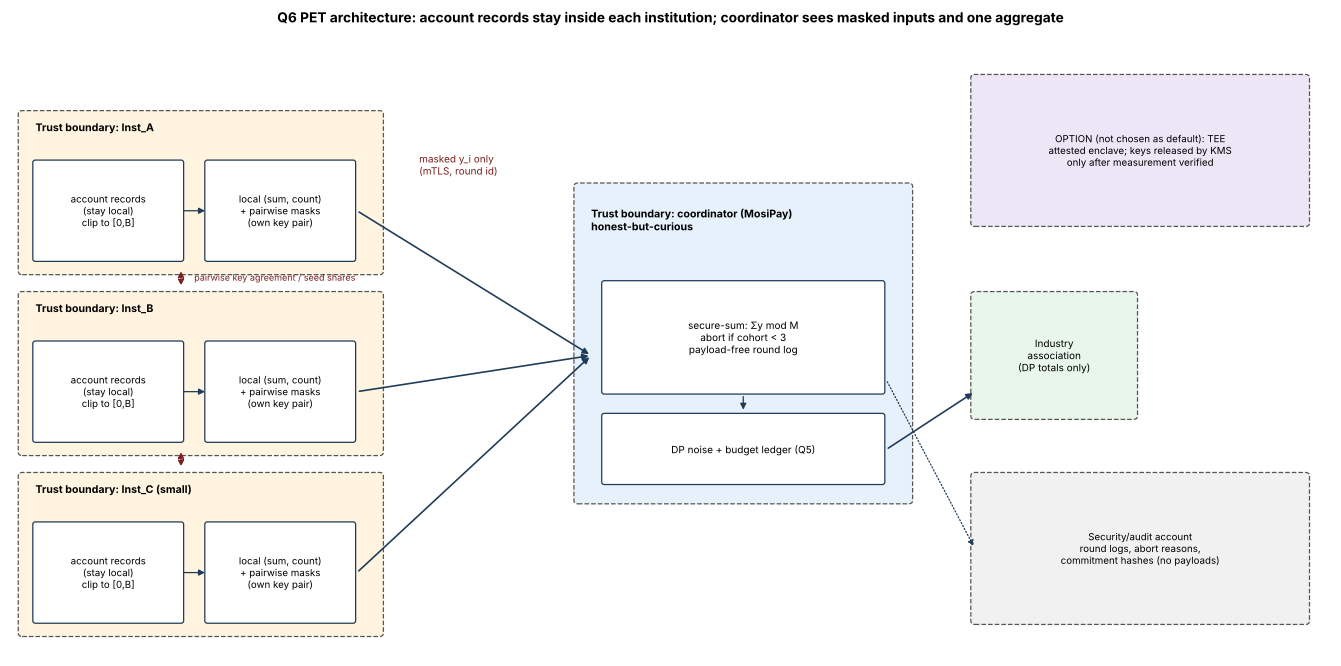

In [74]:
# 6(e)-2  Comparative decision table and PET trust-boundary diagram
pet_table = pd.DataFrame([
    {'option': 'Secure aggregation (Bonawitz-style, e.g. Flower SecAgg+)', 'trust': 'honest-but-curious coordinator; threshold of honest clients',
     'collusion': 'safe below threshold t; with n=3 any 2 colluders learn the 3rd', 'key_custody': 'pairwise keys at each institution; no central key',
     'attestation': 'not needed', 'overhead': 'low (masking + seed shares)', 'access_control': 'mTLS client identity; round enrolment',
     'fit_for_3_institutions': 'GOOD for sums/means; dropout handled by seed recovery; still needs DP on output'},
    {'option': 'General SMPC (3-party, e.g. MP-SPDZ / replicated secret sharing)', 'trust': 'honest majority (2 of 3) or malicious-secure variants',
     'collusion': 'breaks if 2 of 3 collude (honest-majority)', 'key_custody': 'shares held by each party', 'attestation': 'not needed',
     'overhead': 'medium-high (rounds, bandwidth)', 'access_control': 'per-party identities and protocol transcripts',
     'fit_for_3_institutions': 'GOOD when computations beyond sums are needed (e.g. medians, joins)'},
    {'option': 'Additive HE (Paillier / threshold variant)', 'trust': 'decryption-key holder', 'collusion': 'key holder + coordinator can decrypt any single site (shown above)',
     'key_custody': 'central private key unless threshold decryption', 'attestation': 'not needed', 'overhead': 'medium (large ciphertexts, slow exponentiation)',
     'access_control': 'strict control of decryption service', 'fit_for_3_institutions': 'ACCEPTABLE only with threshold decryption shared by all 3'},
    {'option': 'TEE (Intel SGX/TDX, AMD SEV-SNP, Nitro Enclaves)', 'trust': 'hardware vendor + enclave code + attestation service',
     'collusion': 'not party-based; side-channels & compromised firmware are the risk', 'key_custody': 'keys released only after attestation verifies measurement',
     'attestation': 'REQUIRED before key release', 'overhead': 'low compute; high assurance/ops effort', 'access_control': 'attested code identity + operator exclusion',
     'fit_for_3_institutions': 'GOOD if all 3 accept a common cloud/vendor; flexible computation'},
])
pet_table.to_csv(EVID / 'Q6e_pet_comparison.csv', index=False)
display(pet_table.T)

fig, ax = plt.subplots(figsize=(15, 7.5))
ax.set_xlim(0, 100)
ax.set_ylim(0, 52)
ax.axis('off')
site_boxes = {'Inst_A': (2, 33), 'Inst_B': (2, 18), 'Inst_C': (2, 3)}
for site, (bx, by) in site_boxes.items():
    ax.add_patch(FancyBboxPatch((bx - 1, by - 1), 27, 13, boxstyle='round,pad=0.3', fc='#fff4e0', ec='#555555', ls='--'))
    ax.text(bx, by + 10.6, 'Trust boundary: ' + site + (' (small)' if site == 'Inst_C' else ''), fontsize=8.5, weight='bold')
    ax.add_patch(FancyBboxPatch((bx, by), 11, 8, boxstyle='round,pad=0.2', fc='white', ec='#1f3b57'))
    ax.text(bx + 5.5, by + 4, 'account records\n(stay local)\nclip to [0,B]', ha='center', va='center', fontsize=7.8)
    ax.add_patch(FancyBboxPatch((bx + 13, by), 11, 8, boxstyle='round,pad=0.2', fc='white', ec='#1f3b57'))
    ax.text(bx + 18.5, by + 4, 'local (sum, count)\n+ pairwise masks\n(own key pair)', ha='center', va='center', fontsize=7.8)
    ax.annotate('', xy=(bx + 13, by + 4), xytext=(bx + 11, by + 4), arrowprops=dict(arrowstyle='-|>', color='#1f3b57'))
    ax.annotate('', xy=(44, 25), xytext=(bx + 24.3, by + 4), arrowprops=dict(arrowstyle='-|>', color='#1f3b57', lw=1.3))
ax.text(31, 40, 'masked y_i only\n(mTLS, round id)', fontsize=8, color='#7a1f1f')
ax.annotate('', xy=(13, 30.6), xytext=(13, 32.2), arrowprops=dict(arrowstyle='<|-|>', color='#7a1f1f', ls='--'))
ax.annotate('', xy=(13, 15.6), xytext=(13, 17.2), arrowprops=dict(arrowstyle='<|-|>', color='#7a1f1f', ls='--'))
ax.text(14, 31.2, 'pairwise key agreement / seed shares', fontsize=7.2, color='#7a1f1f')
ax.add_patch(FancyBboxPatch((43, 13), 25, 26, boxstyle='round,pad=0.3', fc='#e7f1fb', ec='#555555', ls='--'))
ax.text(44, 37.3, 'Trust boundary: coordinator (MosiPay)\nhonest-but-curious', fontsize=8.5, weight='bold', va='top')
ax.add_patch(FancyBboxPatch((45, 22), 21, 9, boxstyle='round,pad=0.2', fc='white', ec='#1f3b57'))
ax.text(55.5, 26.5, 'secure-sum: Σy mod M\nabort if cohort < 3\npayload-free round log', ha='center', va='center', fontsize=8)
ax.add_patch(FancyBboxPatch((45, 14.5), 21, 5.5, boxstyle='round,pad=0.2', fc='white', ec='#1f3b57'))
ax.text(55.5, 17.2, 'DP noise + budget ledger (Q5)', ha='center', va='center', fontsize=8)
ax.annotate('', xy=(55.5, 20.3), xytext=(55.5, 21.8), arrowprops=dict(arrowstyle='-|>', color='#1f3b57'))
ax.add_patch(FancyBboxPatch((73, 20), 12, 10, boxstyle='round,pad=0.3', fc='#e8f6ec', ec='#555555', ls='--'))
ax.text(79, 25, 'Industry\nassociation\n(DP totals only)', ha='center', va='center', fontsize=8)
ax.annotate('', xy=(73, 22), xytext=(66.3, 17.2), arrowprops=dict(arrowstyle='-|>', color='#1f3b57', lw=1.3))
ax.add_patch(FancyBboxPatch((73, 36), 25, 12, boxstyle='round,pad=0.3', fc='#ece6f7', ec='#555555', ls='--'))
ax.text(85.5, 42, 'OPTION (not chosen as default): TEE\nattested enclave; keys released by KMS\nonly after measurement verified', ha='center', va='center', fontsize=7.8)
ax.add_patch(FancyBboxPatch((73, 3), 25, 12, boxstyle='round,pad=0.3', fc='#f1f1f1', ec='#555555', ls='--'))
ax.text(85.5, 9, 'Security/audit account\nround logs, abort reasons,\ncommitment hashes (no payloads)', ha='center', va='center', fontsize=7.8)
ax.annotate('', xy=(73, 9), xytext=(66.3, 23), arrowprops=dict(arrowstyle='-|>', ls=':', color='#1f3b57'))
ax.set_title('Q6 PET architecture: account records stay inside each institution; coordinator sees masked inputs and one aggregate',
             fontsize=11, weight='bold')
plt.tight_layout()
plt.savefig(EVID / 'Q6e_pet_trust_boundaries.png', dpi=160)
plt.show()

**Architecture decision (ADR-006, proposed, not deployed).** For three institutions that compute sums, counts and means:

1. **Use a vetted secure-aggregation implementation** with authenticated key agreement and t-of-n seed recovery, such as Bonawitz-style SecAgg as implemented in Flower. Key custody stays distributed (each institution holds its own keys), no attestation infrastructure is required, and overhead is low.
2. **Set the minimum cohort to 3 of 3.** Abort on dropout. Never publish partials.
3. **Add calibrated DP noise to every released total** through the Q5 ledger. Secure aggregation hides *inputs* from the coordinator but not the *output* from the public.
4. **Use general 3-party SMPC** (honest majority) only if later analyses need non-linear functions.
5. **Use a TEE** only if all three institutions accept the same hardware vendor and attestation process, and side-channel patching is governed.
6. **Use HE only with threshold decryption.** A single key holder can decrypt any one institution's input, as the toy above demonstrated.

Federated processing alone provides **neither anonymity nor DP**. The toy masks in this notebook are **not** a hardened protocol.

## Final audit flush (all questions)
Q5 and Q6 added further audit events (DP releases, the blocked queries, the aborted federated round). The payload-free, hash-chained log from Q2(e) is rebuilt over **all** events, so the evidence log is complete.

In [75]:
flush_prev = 'genesis'
flushed = []
for event in AUDIT:
    serialised = json.dumps(event, sort_keys=True, default=str)
    assert set(event).issubset(ALLOWED_KEYS), event
    assert re.search(DLP_RULES['v2']['account'], serialised) is None and re.search(DLP_RULES['v2']['card'], serialised) is None
    chained = dict(event)
    chained['prev_hash'] = flush_prev
    chained['event_hash'] = base64.b32encode(hashlib.sha256((flush_prev + serialised).encode()).digest()).decode().lower()
    flush_prev = chained['event_hash']
    flushed.append(json.dumps(chained, sort_keys=True, default=str))
audit_path.write_text('\n'.join(flushed) + '\n')
shutil.copy2(audit_path, EVID / 'Q2e_audit_log_sanitised.jsonl')
flushed_df = pd.DataFrame([json.loads(line) for line in flushed])
print('Audit events:', len(flushed), '| by action:', flushed_df['action'].value_counts().to_dict())
assert {'DPRelease', 'SecureSumRound'}.issubset(set(flushed_df['action']))
assert (flushed_df.loc[flushed_df['action'] == 'DPRelease', 'decision'] == 'DENY').sum() == 2

Audit events: 42 | by action: {'read': 13, 'DPRelease': 6, 'export': 5, 'Quarantine': 3, 'ReEncrypt(RewrapDEK)': 3, 'detokenise': 3, 'GenerateDataKey+Encrypt': 2, 'IngestSource': 1, 'HMACTokenise': 1, 'CreateKey': 1, 'DisableKey+ScheduleDeletion': 1, 'Decrypt': 1, 'TokenVaultLookup': 1, 'SecureSumRound': 1}


## Evidence package and final integrity check

The ZIP contains only derived, payload-free evidence for Q1–Q6: profiles, contracts, architecture figures, ADR, risk and decision logs, access matrices, crypto and DLP tests, the audit log, k/l/t reports, the attack comparisons, synthetic-data utility and risk tables, the DP release and ledger, and the federated comparison and PET diagram. **Excluded:** the restricted raw copy, the quarantine payload, Bronze/Silver files, the restricted account-level table, internal DP truth values, synthetic candidate files, encrypted batches and all keys.

In [76]:
evidence_zip = ROOT / ZONE_DIRS['evidence'] / '..' / 'ICD5211_Q1_Q6_evidence.zip'
evidence_zip = evidence_zip.resolve()
with zipfile.ZipFile(evidence_zip, 'w', compression=zipfile.ZIP_DEFLATED) as bundle:
    for path in sorted(EVID.iterdir()):
        bundle.write(path, arcname='evidence/' + path.name)
zip_scan_hits = 0
with zipfile.ZipFile(evidence_zip) as bundle:
    names = bundle.namelist()
    for name in names:
        if not name.endswith(('.csv', '.json', '.jsonl', '.md')):
            continue
        text = bundle.read(name).decode('utf-8', errors='ignore')
        zip_scan_hits = zip_scan_hits + len(re.findall(DLP_RULES['v2']['account'], text)) + len(re.findall(DLP_RULES['v2']['card'], text))
        assert ACCT_KEY.hex() not in text and CASE_KEY.hex() not in text
SOURCE_SHA256_AFTER = hashlib.sha256(SOURCE.read_bytes()).hexdigest()
RAW_SHA256_AFTER = hashlib.sha256(RAW_COPY.read_bytes()).hexdigest()
assert zip_scan_hits == 0
for name in names:
    assert 'source_readonly' not in name and 'RESTRICTED' not in name and not name.endswith('.bin') and 'synthetic_G' not in name
assert SOURCE_SHA256_AFTER == SOURCE_SHA256_BEFORE == RAW_SHA256_AFTER
print('Evidence ZIP:', evidence_zip.name, '|', len(names), 'files | identifier hits:', zip_scan_hits)
print('Original CSV unchanged (SHA-256 before == after):', SOURCE_SHA256_AFTER[:16], '...')
display(pd.DataFrame({'evidence_file': names}))
if 'google.colab' in sys.modules:
    from google.colab import files
    files.download(str(evidence_zip))

Evidence ZIP: ICD5211_Q1_Q6_evidence.zip | 50 files | identifier hits: 0
Original CSV unchanged (SHA-256 before == after): 3db5ef0eecb1a4d8 ...


,evidence_file
0,evidence/ADR-001.md
1,evidence/Q1a_data_profile.csv
2,evidence/Q1a_hazards.csv
3,evidence/Q1a_transactions_per_account.png
4,evidence/Q1a_transactions_vs_accounts.csv
5,evidence/Q1b_architecture.pdf
6,evidence/Q1b_architecture.png
7,evidence/Q1b_cloud_mapping_PROPOSED.csv
8,evidence/Q1b_flow_control_check.csv
9,evidence/Q1b_principals.csv


## Disclosure of assistance
In line with Mulungushi University's academic-integrity requirements: this notebook was drafted with the help of an AI assistant (Anthropic Claude). The student reviewed, ran and is responsible for the code, the design decisions and their defence in the oral walkthrough.